#  Códigos Antigos

In [ ]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

# Load an audio file
# 'y' is the audio time series (a NumPy array)
# 'sr' is the sampling rate
y, sr = librosa.load('/content/musicas/audioTeste.mp3',sr = None)

# Extract MFCC features (a common audio feature)
mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)

# Print the shape of the features
print(f"Audio time series shape: {y.shape}")
print(f"MFCC features shape: {mfccs.shape}")

/tmp/ipython-input-1029447312.py:9: UserWarning: PySoundFile failed. Trying audioread instead.
  y, sr = librosa.load('/content/musicas/audioTeste.mp3',sr = None)
/usr/local/lib/python3.12/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


FileNotFoundError: [Errno 2] No such file or directory: '/content/musicas/audioTeste.mp3'

--- Iniciando processamento para: /content/drive/MyDrive/MusicaFFT/Do_2.mp3 ---
Carregando áudio e convertendo para mono...
Áudio carregado. Duração: 11.46 segundos. Sample Rate: 22050Hz

Calculando o Cromatograma (juntando as oitavas)...

Gerando o gráfico...
Mostrando gráfico na tela. Feche a janela do gráfico para encerrar.


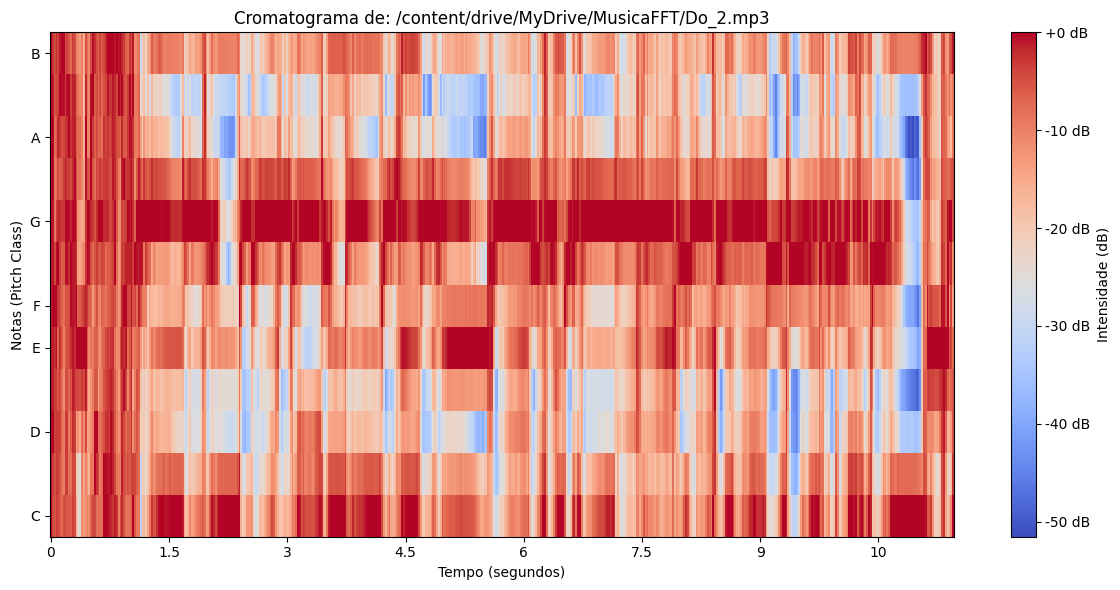

--- Iniciando processamento para: /content/drive/MyDrive/MusicaFFT/Do_2.mp3 ---
Carregando áudio e convertendo para mono...
Áudio carregado. Duração: 11.46 segundos. Sample Rate: 22050Hz

Calculando o Cromatograma (juntando as oitavas)...

Gerando o gráfico...
Mostrando gráfico na tela. Feche a janela do gráfico para encerrar.


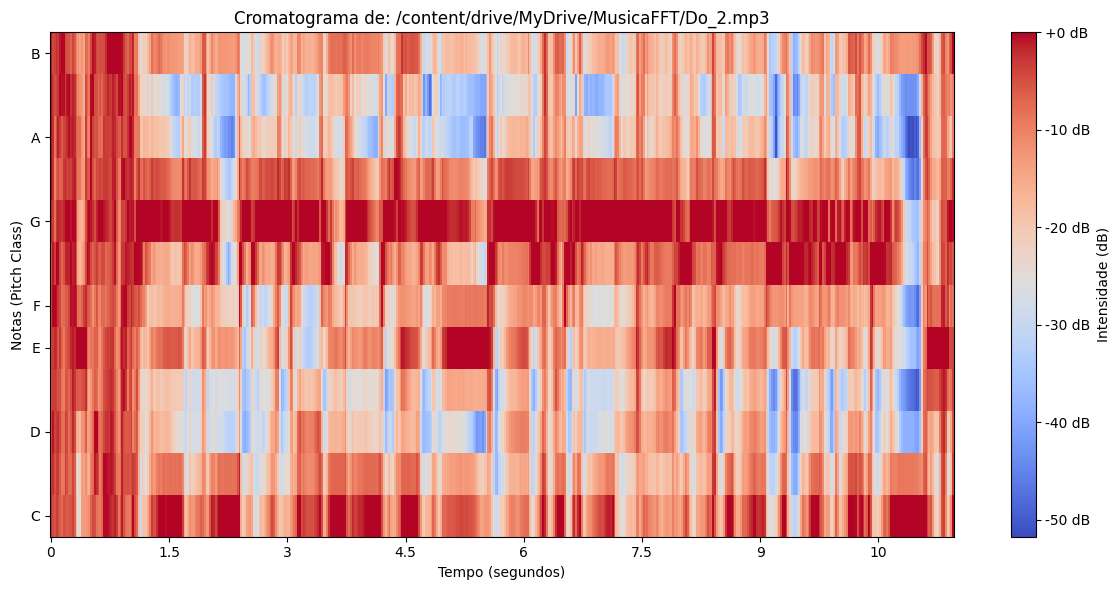

In [ ]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import scipy.signal


troca_de_acorde = '/content/drive/MyDrive/MusicaFFT/TrocaDeAcordes(C-G-F).mp3'
do_1 = '/content/drive/MyDrive/MusicaFFT/Do_1.mp3'
do_2 = '/content/drive/MyDrive/MusicaFFT/Do_2.mp3'



# Se você não tiver um arquivo agora, o librosa tem um exemplo embutido.
# Descomente a linha abaixo para usar o áudio de exemplo se o seu arquivo falhar:
# audio_path = librosa.ex('trumpet')


def analisar_e_plotar_chroma(caminho_arquivo, janelamento=None):
    """

    Carrega um áudio, calcula suas características Chroma e plota o resultado.
    """
    print(f"--- Iniciando processamento para: {caminho_arquivo} ---")

    # 1. FASE DE CARREGAMENTO (Load)
    # O librosa.load já faz várias coisas úteis por padrão:
    # - Converte para Mono (mistura L e R)
    # - Reamostra (resample) para 22050Hz (padrão bom para música)
    print("Carregando áudio e convertendo para mono...")
    try:
        y, sr = librosa.load(caminho_arquivo)#, sr = 22050*2
    except FileNotFoundError:
        print(f"\nERRO: O arquivo '{caminho_arquivo}' não foi encontrado.")
        print("Verifique o nome do arquivo ou coloque o caminho completo.")
        return

    print(f"Áudio carregado. Duração: {len(y)/sr:.2f} segundos. Sample Rate: {sr}Hz")


    # 2. & 3. FASE DE PROCESSAMENTO (STFT -> Chroma)
    # Calcula o Cromatograma. O librosa faz a STFT internamente aqui.
    # O resultado 'chromagram' é uma matriz onde:
    # - Eixo Y (linhas) são as 12 notas (C, C#, D...)
    # - Eixo X (colunas) são os frames de tempo
    # Os valores dentro são a intensidade (magnitude) daquela nota naquele momento.
    print("\nCalculando o Cromatograma (juntando as oitavas)...")

    # 'hop_length' define o quão "rápida" é a análise temporal.
    # 512 é um padrão comum. Valores menores = mais detalhes no tempo, mas mais lento.
    hop_length = 512

    #chromagram = librosa.feature.chroma_stft(y=y, sr=sr, hop_length=hop_length)

    # Exemplo usando a janela de Hamming (muito comum para áudio)
    if janelamento:
      chromagram = librosa.feature.chroma_stft(
          y=y,
          sr=sr,
          hop_length=512,
          n_fft=2048,
          window= janelamento  # <--- AQUI
      )
      #chromagram = librosa.feature.chroma_cqt(y=y, sr=sr, hop_length=512)
    else:
      chromagram = librosa.feature.chroma_stft(y=y, sr=sr, hop_length=hop_length)

    # Opcional: Para melhorar a visualização, usamos uma escala logarítmica ou decibéis,
    # pois nossos ouvidos não percebem volume de forma linear.
    # O 'ref=np.max' normaliza o ponto mais alto para 0 dB.
    chroma_db = librosa.amplitude_to_db(chromagram, ref=np.max)


    # 4. VISUALIZAÇÃO (Plot)
    print("\nGerando o gráfico...")
    plt.figure(figsize=(12, 6))

    # specshow é a função mágica do librosa para plotar espectrogramas
    img = librosa.display.specshow(chroma_db,
                                   y_axis='chroma', # Rotula o eixo Y com notas musicais
                                   x_axis='time',   # Rotula o eixo X com segundos
                                   sr=sr,
                                   hop_length=hop_length,
                                   cmap='coolwarm') # Mapa de cores (azul=frio/fraco, vermelho=quente/forte)

    plt.colorbar(img, format='%+2.0f dB', label='Intensidade (dB)')
    plt.title(f'Cromatograma de: {caminho_arquivo}')
    plt.xlabel('Tempo (segundos)')
    plt.ylabel('Notas (Pitch Class)')

    plt.tight_layout()
    print("Mostrando gráfico na tela. Feche a janela do gráfico para encerrar.")
    plt.show()

# Executa a função principal
if __name__ == "__main__":
    # analisar_e_plotar_chroma(troca_de_acorde)
    analisar_e_plotar_chroma(do_2, 'blackman')
    analisar_e_plotar_chroma(do_2, 'hamming')

--- Iniciando processamento para: /content/musicas/audioTeste.mp3 ---
Carregando áudio e convertendo para mono...
Áudio carregado. Duração: 21.14 segundos. Sample Rate: 22050Hz

Calculando o Cromatograma (juntando as oitavas)...

Gerando o gráfico...
Mostrando gráfico na tela. Feche a janela do gráfico para encerrar.


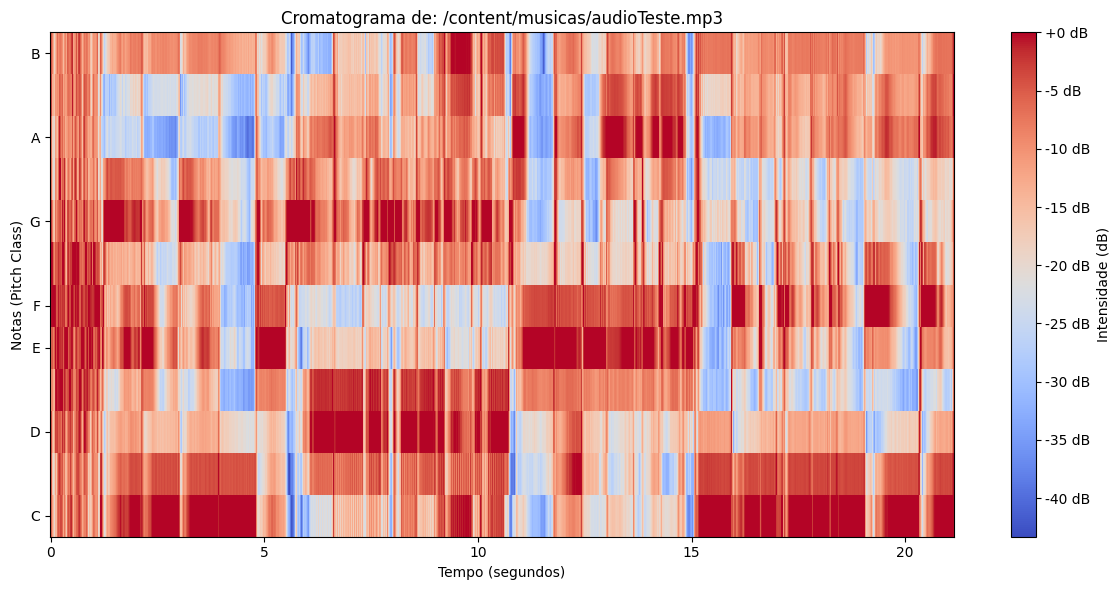

In [ ]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np


audio_path = '/content/musicas/audioTeste.mp3'

# Se você não tiver um arquivo agora, o librosa tem um exemplo embutido.
# Descomente a linha abaixo para usar o áudio de exemplo se o seu arquivo falhar:
# audio_path = librosa.ex('trumpet')


def analisar_e_plotar_chroma(caminho_arquivo):
    """
    Carrega um áudio, calcula suas características Chroma e plota o resultado.
    """
    print(f"--- Iniciando processamento para: {caminho_arquivo} ---")

    # 1. FASE DE CARREGAMENTO (Load)
    # O librosa.load já faz várias coisas úteis por padrão:
    # - Converte para Mono (mistura L e R)
    # - Reamostra (resample) para 22050Hz (padrão bom para música)
    print("Carregando áudio e convertendo para mono...")
    try:
        y, sr = librosa.load(caminho_arquivo)
    except FileNotFoundError:
        print(f"\nERRO: O arquivo '{caminho_arquivo}' não foi encontrado.")
        print("Verifique o nome do arquivo ou coloque o caminho completo.")
        return

    print(f"Áudio carregado. Duração: {len(y)/sr:.2f} segundos. Sample Rate: {sr}Hz")


    # 2. & 3. FASE DE PROCESSAMENTO (STFT -> Chroma)
    # Calcula o Cromatograma. O librosa faz a STFT internamente aqui.
    # O resultado 'chromagram' é uma matriz onde:
    # - Eixo Y (linhas) são as 12 notas (C, C#, D...)
    # - Eixo X (colunas) são os frames de tempo
    # Os valores dentro são a intensidade (magnitude) daquela nota naquele momento.
    print("\nCalculando o Cromatograma (juntando as oitavas)...")

    # 'hop_length' define o quão "rápida" é a análise temporal.
    # 512 é um padrão comum. Valores menores = mais detalhes no tempo, mas mais lento.
    hop_length = 512
    chromagram = librosa.feature.chroma_stft(y=y, sr=sr, hop_length=hop_length)

    # Opcional: Para melhorar a visualização, usamos uma escala logarítmica ou decibéis,
    # pois nossos ouvidos não percebem volume de forma linear.
    # O 'ref=np.max' normaliza o ponto mais alto para 0 dB.
    chroma_db = librosa.amplitude_to_db(chromagram, ref=np.max)


    # 4. VISUALIZAÇÃO (Plot)
    print("\nGerando o gráfico...")
    plt.figure(figsize=(12, 6))

    # specshow é a função mágica do librosa para plotar espectrogramas
    img = librosa.display.specshow(chroma_db,
                                   y_axis='chroma', # Rotula o eixo Y com notas musicais
                                   x_axis='time',   # Rotula o eixo X com segundos
                                   sr=sr,
                                   hop_length=hop_length,
                                   cmap='coolwarm') # Mapa de cores (azul=frio/fraco, vermelho=quente/forte)

    plt.colorbar(img, format='%+2.0f dB', label='Intensidade (dB)')
    plt.title(f'Cromatograma de: {caminho_arquivo}')
    plt.xlabel('Tempo (segundos)')
    plt.ylabel('Notas (Pitch Class)')

    plt.tight_layout()
    print("Mostrando gráfico na tela. Feche a janela do gráfico para encerrar.")
    plt.show()

# Executa a função principal
if __name__ == "__main__":
    analisar_e_plotar_chroma(audio_path)

Codigos do Daniel


Calculando CQT ajustada para escala cromática...


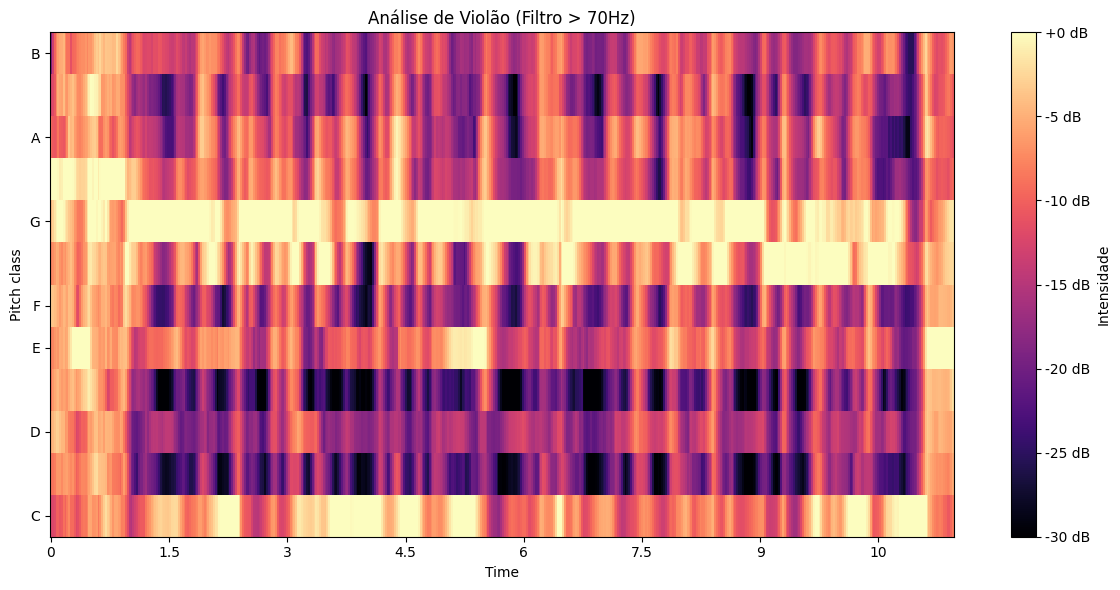

Calculando CQT ajustada para escala cromática...


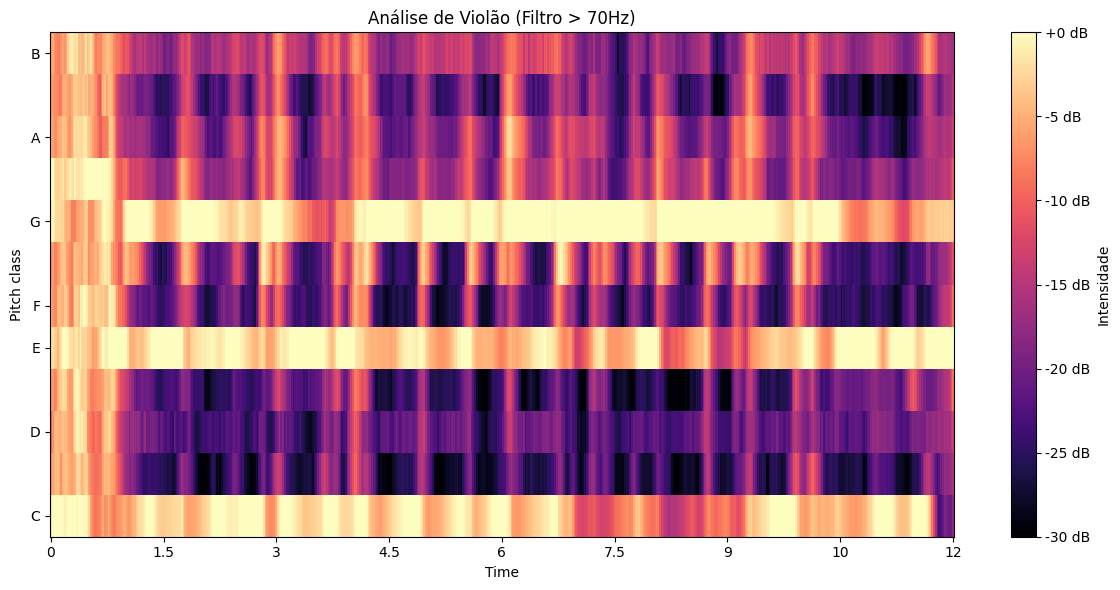

Calculando CQT ajustada para escala cromática...


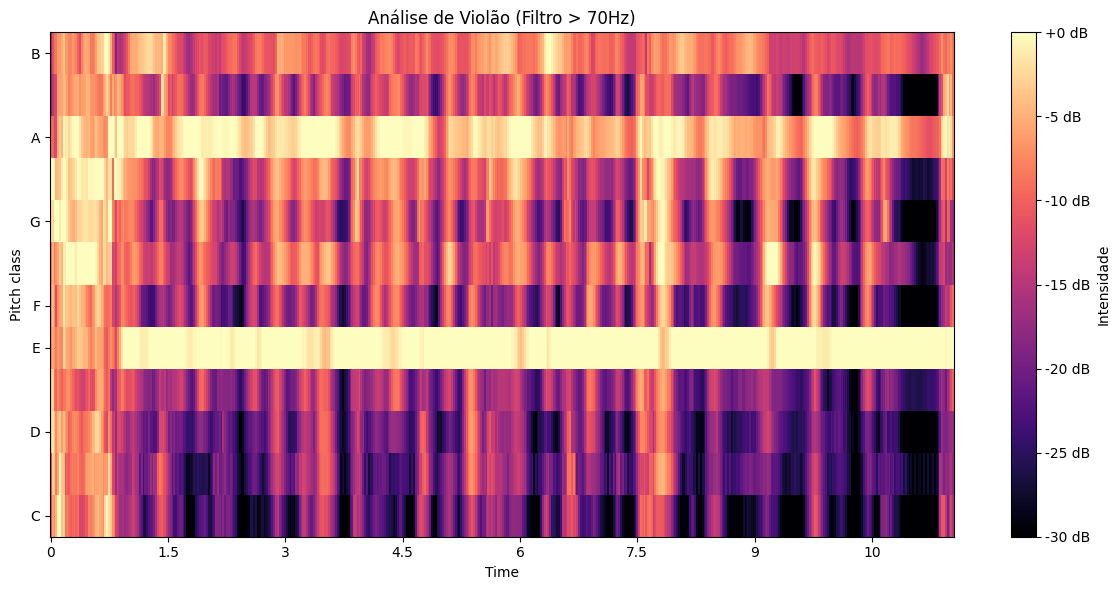

Calculando CQT ajustada para escala cromática...


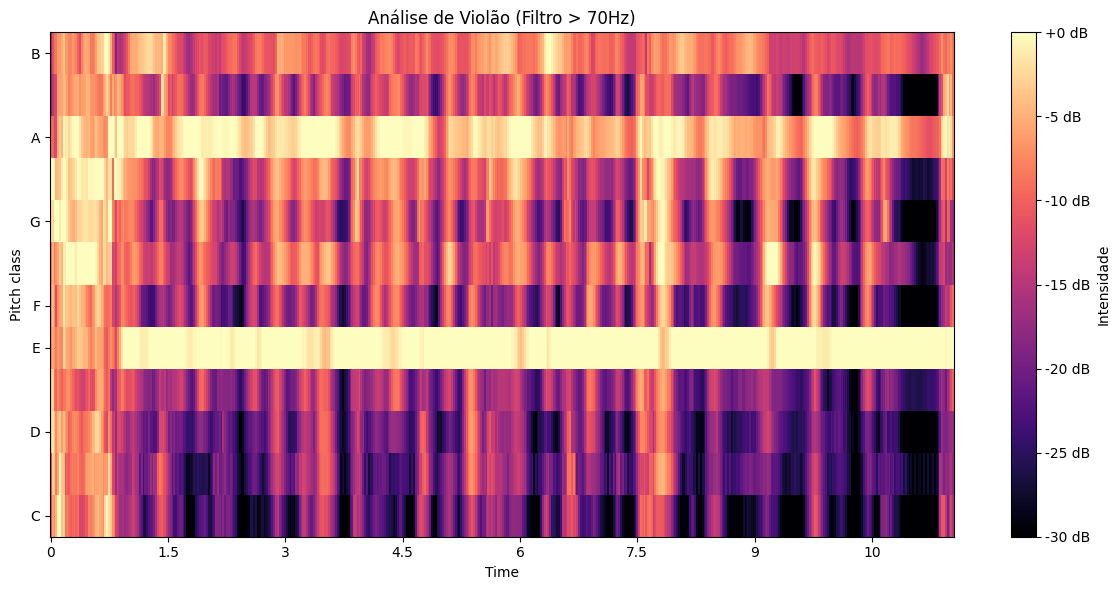

Calculando CQT ajustada para escala cromática...


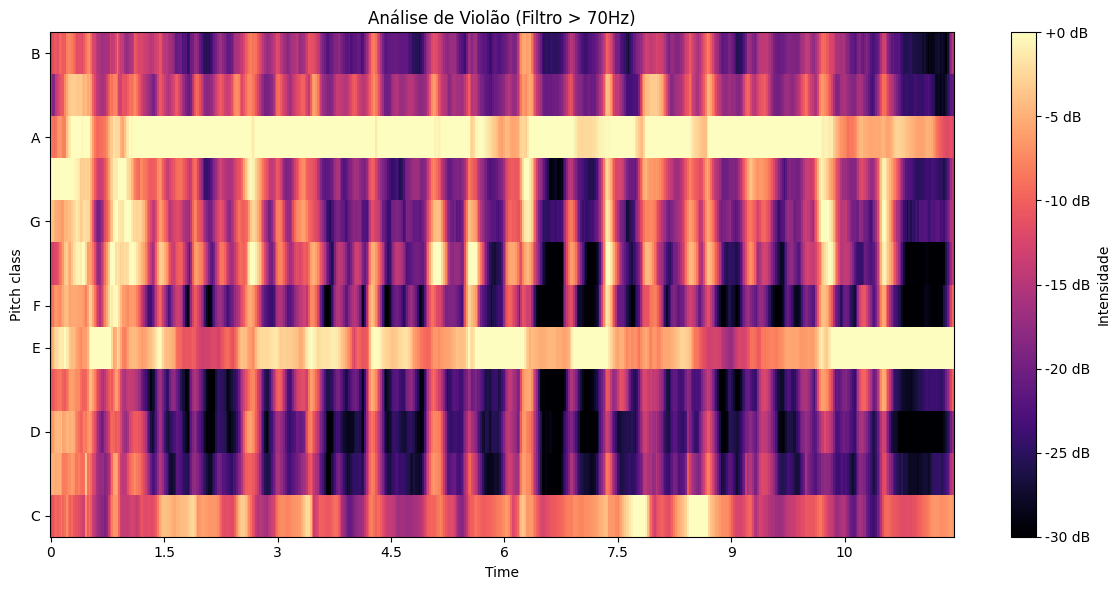

In [ ]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import scipy.signal

# --- Configurações ---
troca_de_acorde = '/content/drive/MyDrive/MusicaFFT/TrocaDeAcordes(C-G-F).mp3'
do_1 = '/content/drive/MyDrive/MusicaFFT/Do_1.mp3'
do_2 = '/content/drive/MyDrive/MusicaFFT/Do_2.mp3'
re_1 = '/content/drive/MyDrive/MusicaFFT/Re_1.mp3'
re_2 = '/content/drive/MyDrive/MusicaFFT/Re_2.mp3'
la_menor_2 = '/content/drive/MyDrive/MusicaFFT/La_menor_1.mp3'


# O Mizão (E2) é ~82Hz. Cortamos em 70Hz para segurança.
frequencia_corte = 70
frequencia_minima = 65  # O CQT precisa saber onde começar (C2 = ~65Hz é um bom piso)

def aplicar_filtro_passa_alta(y, sr, cutoff_freq):
    # Filtro Butterworth (mais suave para áudio que o Chebyshev)
    nyquist = 0.5 * sr
    norm_cutoff = cutoff_freq / nyquist
    # Ordem 5 é suficiente para limpar o grave sem destruir a fase
    b, a = scipy.signal.butter(5, norm_cutoff, btype='high', analog=False)
    y_filtrado = scipy.signal.filtfilt(b, a, y)
    return y_filtrado

def analisar_violao(audio_path):
    # 1. Carregar
    y, sr = librosa.load(audio_path)

    # 2. Filtrar frequências sub-graves (batidas na caixa, ar condicionado)
    # Isso limpa a região abaixo do E2 (82Hz)
    y_clean = aplicar_filtro_passa_alta(y, sr, frequencia_corte)

    # 3. CQT (A Melhor Transformada para Violão)
    # Em vez de STFT com padding, usamos CQT que já é naturalmente ajustada para notas.
    print("Calculando CQT ajustada para escala cromática...")

    chromagram = librosa.feature.chroma_cqt(
        y=y_clean,
        sr=sr,
        hop_length=512,
        fmin=librosa.note_to_hz('C2'), # Começa a analisar do Dó grave (C2)
        n_octaves=6, # Analisa 6 oitavas (cobre todo o braço do violão)
        bins_per_octave=36 # 3 bins por nota = Alta resolução (detecta vibratos/bends)
    )

    # 4. Limpeza Visual (Threshold)
    # Violão tem muita ressonância harmônica. Vamos ignorar sons muito fracos.
    chroma_db = librosa.amplitude_to_db(chromagram, ref=np.max)

    # Plotagem
    plt.figure(figsize=(12, 6))

    # vmin=-30 limpa o "fantasma" das cordas vibrando por simpatia
    librosa.display.specshow(chroma_db, y_axis='chroma', x_axis='time',
                             sr=sr, hop_length=512, cmap='magma', vmin=-30)

    plt.title(f'Análise de Violão (Filtro > {frequencia_corte}Hz)')
    plt.colorbar(format='%+2.0f dB', label='Intensidade')
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    analisar_violao(do_2)
    analisar_violao(do_1)
    analisar_violao(re_2)
    analisar_violao(re_2)
    analisar_violao(la_menor_2)




--- Processando: Do_2.mp3 ---
Filtrando áudio: 70Hz < Som < 6000Hz


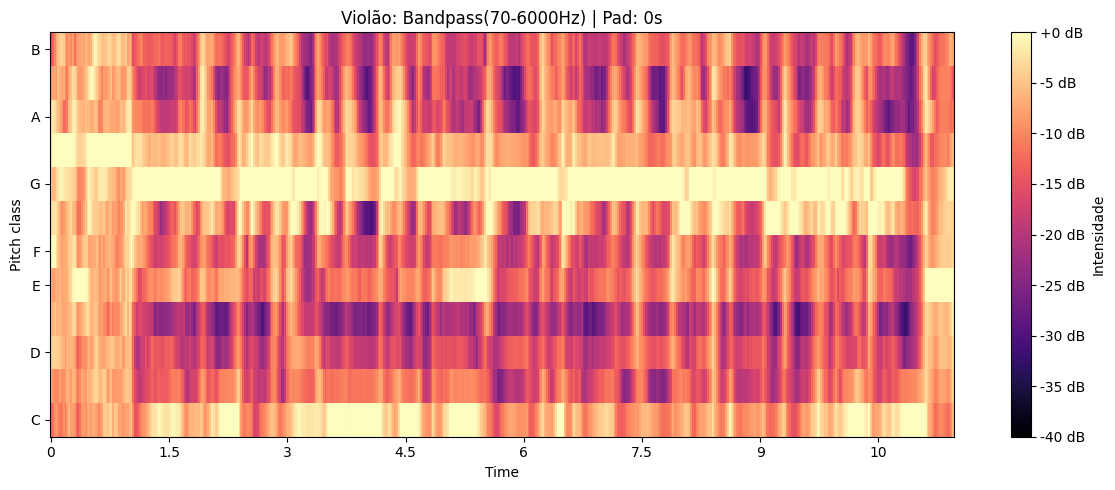


--- Processando: Do_1.mp3 ---
Filtrando áudio: 70Hz < Som < 6000Hz


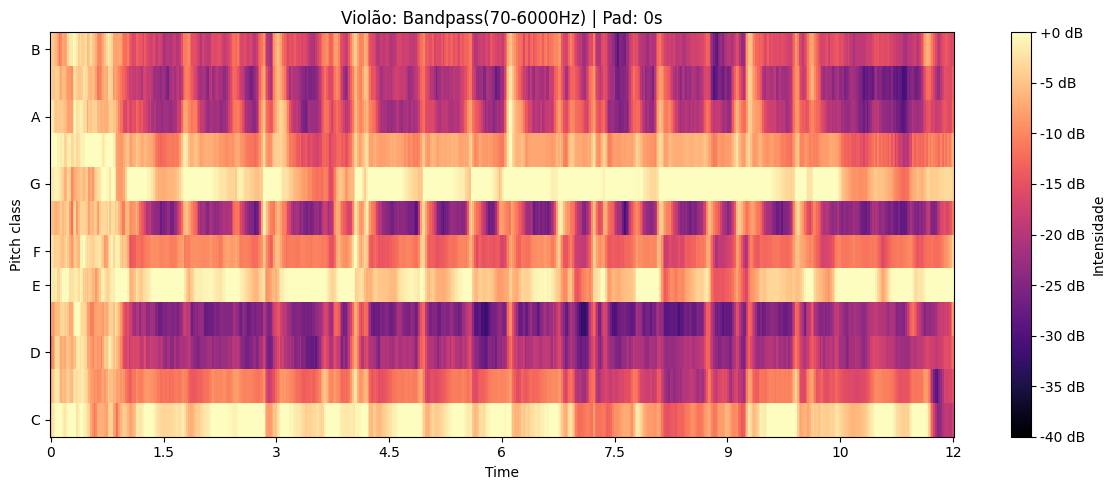


--- Processando: Re_1.mp3 ---
Filtrando áudio: 70Hz < Som < 6000Hz


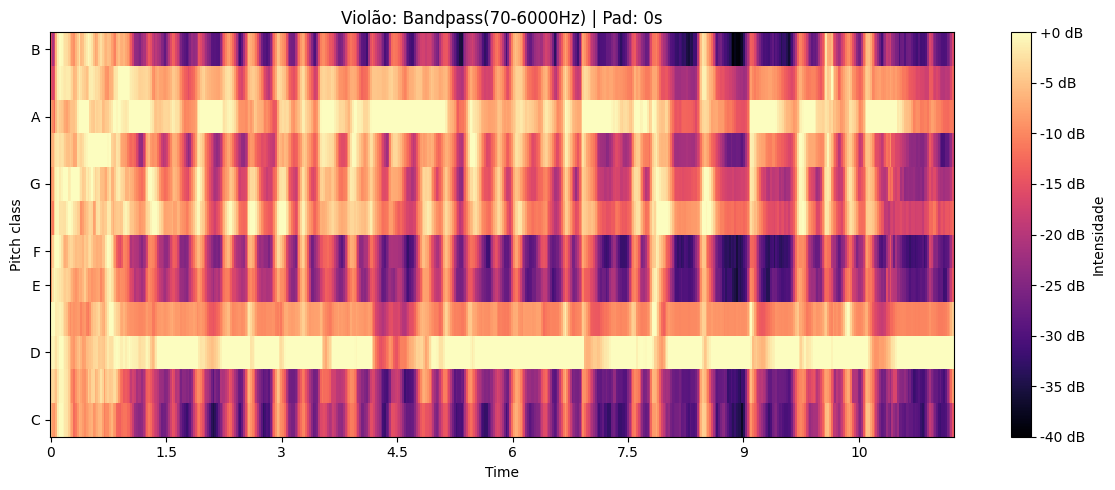


--- Processando: La_1.mp3 ---
Filtrando áudio: 70Hz < Som < 6000Hz


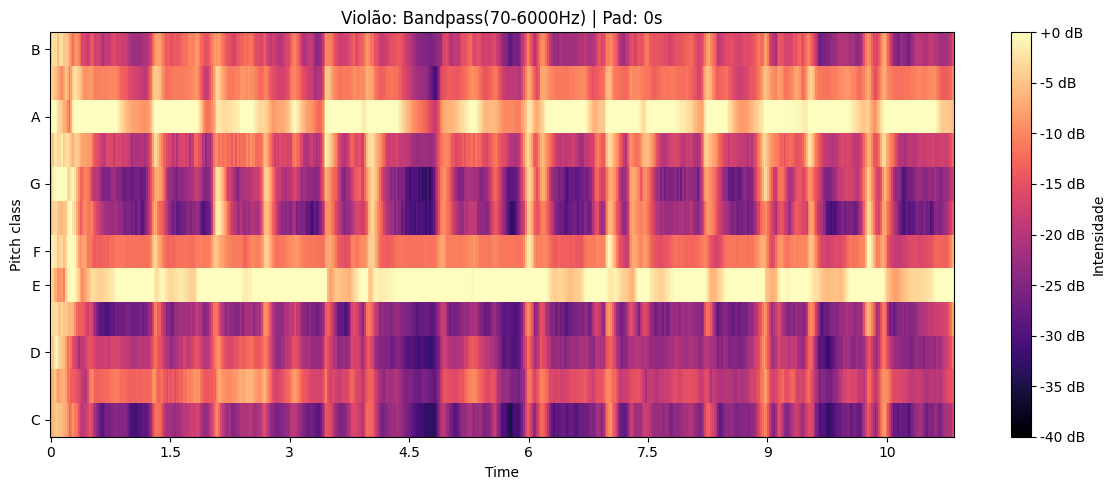

In [ ]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import scipy.signal

# --- Configurações de Arquivos ---
troca_de_acorde = '/content/drive/MyDrive/MusicaFFT/TrocaDeAcordes(C-G-F).mp3'
do_1 = '/content/drive/MyDrive/MusicaFFT/Do_1.mp3'
do_2 = '/content/drive/MyDrive/MusicaFFT/Do_2.mp3'
re_1 = '/content/drive/MyDrive/MusicaFFT/Re_1.mp3'
re_2 = '/content/drive/MyDrive/MusicaFFT/Re_2.mp3'
la_menor_2 = '/content/drive/MyDrive/MusicaFFT/La_menor_1.mp3'
la_1= '/content/drive/MyDrive/MusicaFFT/La_1.mp3'

# --- Configurações de Física do Violão ---
FREQ_CORTE_GRAVE = 70    # Hz (Remove batidas no corpo/rumble)
FREQ_CORTE_AGUDO = 6000  # Hz (Novo: Remove chiado/hiss. Acima de 6kHz pouco importa para acordes)

def aplicar_filtro_bandpass(y, sr, f_min, f_max):
    """
    Aplica um filtro Bandpass (Passa-Faixa).
    Remove tudo ABAIXO de f_min e tudo ACIMA de f_max.
    """
    # Verificação de segurança: f_max não pode ser maior que Nyquist (metade do SR)
    nyquist = 0.5 * sr
    if f_max >= nyquist:
        f_max = nyquist - 1

    # Normaliza as frequências
    low = f_min / nyquist
    high = f_max / nyquist

    # Cria o filtro (btype='band')
    # Usamos output='sos' (Second-Order Sections) pois é mais estável numericamente para bandpass
    sos = scipy.signal.butter(5, [low, high], btype='band', analog=False, output='sos')

    # Aplica o filtro
    y_filtrado = scipy.signal.sosfiltfilt(sos, y)
    return y_filtrado

def analisar_violao(audio_path, padding_segundos=1.0, f_max=FREQ_CORTE_AGUDO):
    """
    Analisa o áudio com parâmetros ajustáveis de padding e filtro.

    Args:
        padding_segundos (float): Quanto tempo de silêncio adicionar antes e depois.
                                  Aumentar isso ajuda a FFT a pegar o 'ataque' inicial do acorde.
        f_max (int): Frequência de corte superior.
    """
    print(f"\n--- Processando: {audio_path.split('/')[-1]} ---")

    # 1. Carregar
    try:
        y, sr = librosa.load(audio_path)
    except FileNotFoundError:
        print("Arquivo não encontrado.")
        return

    # 2. Zero Padding (No Domínio do Tempo)
    # Adicionamos zeros (silêncio) no início e fim.
    # Isso substitui o padding da FFT no contexto da CQT, permitindo melhor resolução nas bordas.
    if padding_segundos > 0:
        n_pad = int(padding_segundos * sr)
        print(f"Aplicando Zero Padding: +{padding_segundos}s de silêncio nas bordas.")
        y = np.pad(y, (n_pad, n_pad), mode='constant')

    # 3. Filtragem (Bandpass)
    # Limpa graves profundos E agudos estridentes
    print(f"Filtrando áudio: {FREQ_CORTE_GRAVE}Hz < Som < {f_max}Hz")
    y_clean = aplicar_filtro_bandpass(y, sr, FREQ_CORTE_GRAVE, f_max)

    chromagram = librosa.feature.chroma_cqt(
        y=y_clean,
        sr=sr,
        hop_length=512,
        fmin=librosa.note_to_hz('C2'),
        n_octaves=6,
        bins_per_octave=24
    )

    # Suavização temporal
    chroma_smooth = scipy.ndimage.uniform_filter1d(
        chromagram, size=9, axis=1
    )

    # Normalização por frame
    chroma_norm = chroma_smooth / (np.max(chroma_smooth, axis=0, keepdims=True) + 1e-6)

    # Threshold visual
    chroma_norm[chroma_norm < 0.3] = 0


    # 5. Visualização
    chroma_db = librosa.amplitude_to_db(chromagram, ref=np.max)

    plt.figure(figsize=(12, 5))

    # vmin ajuda a esconder o ruído de fundo (tudo abaixo de -30dB vira azul escuro)
    librosa.display.specshow(chroma_db, y_axis='chroma', x_axis='time',
                             sr=sr, hop_length=512, cmap='magma', vmin=-40)

    plt.title(f'Violão: Bandpass({FREQ_CORTE_GRAVE}-{f_max}Hz) | Pad: {padding_segundos}s')
    plt.colorbar(format='%+2.0f dB', label='Intensidade')
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    # Exemplo de chamada com parâmetros personalizados
    # padding_segundos=0.5 -> Adiciona meio segundo de silêncio para "respiro" da análise

    analisar_violao(do_2, padding_segundos=0)
    analisar_violao(do_1, padding_segundos=0)
    analisar_violao(re_1, padding_segundos=0)
    analisar_violao(la_1, padding_segundos=0)



    # Você pode testar remover o filtro agudo se quiser, passando um valor alto
    # analisar_violao(re_2, f_max=15000)


--- Processando: Do_2.mp3 ---
Aplicando Zero Padding: +75s de silêncio nas bordas.
Filtrando áudio: 70Hz < Som < 6000Hz
Calculando Cromagrama STFT...


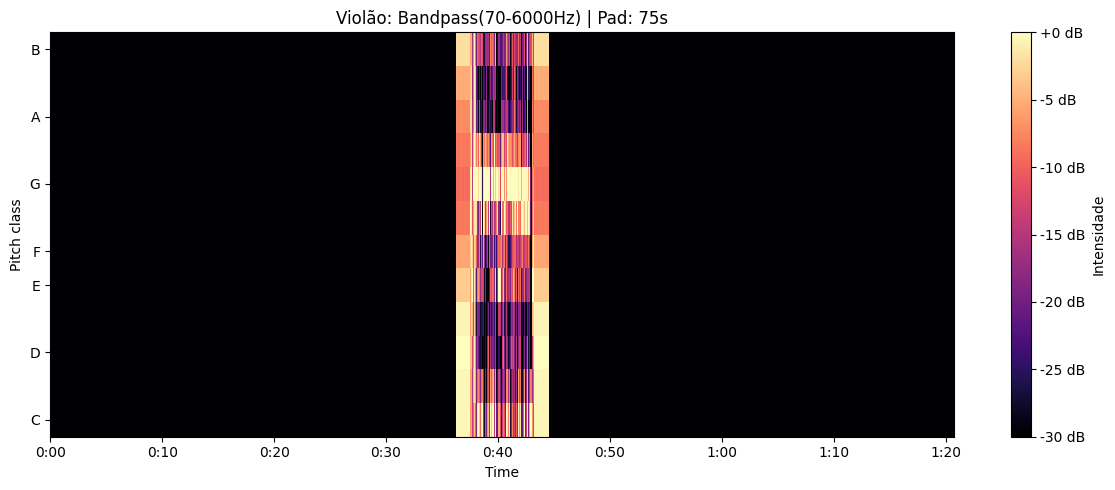


--- Processando: Do_1.mp3 ---
Filtrando áudio: 70Hz < Som < 6000Hz
Calculando Cromagrama STFT...


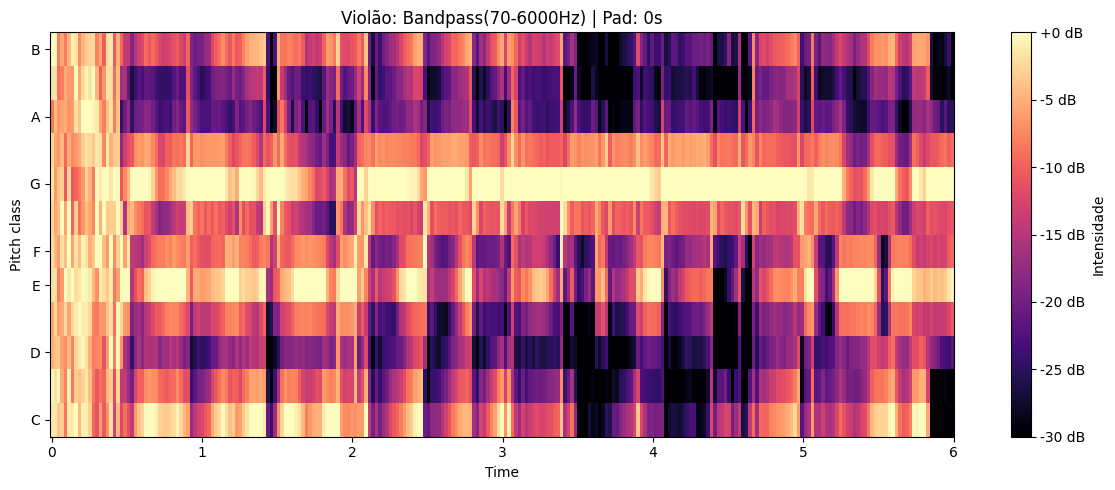


--- Processando: Re_1.mp3 ---
Filtrando áudio: 70Hz < Som < 6000Hz
Calculando Cromagrama STFT...


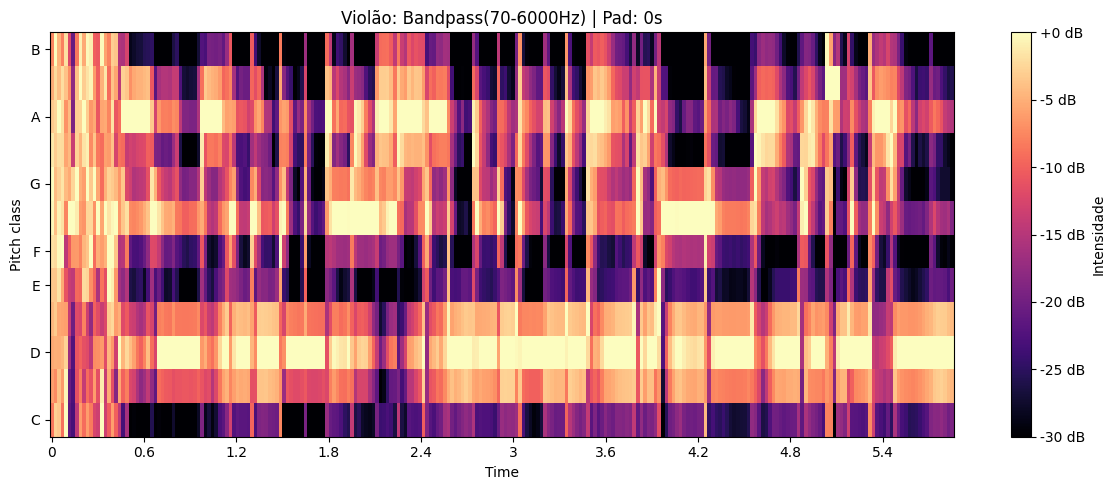


--- Processando: Re_1.mp3 ---
Filtrando áudio: 70Hz < Som < 6000Hz
Calculando Cromagrama STFT...


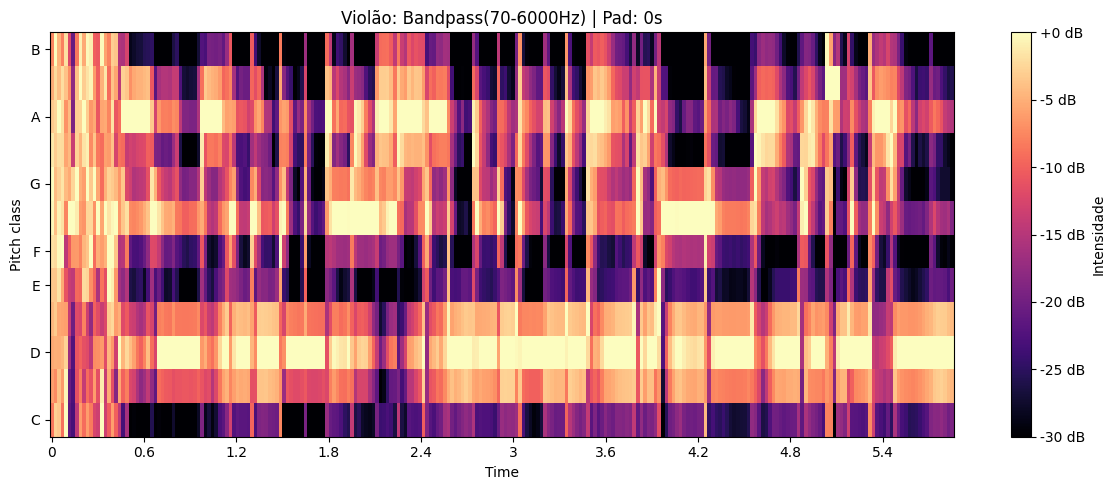

In [ ]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import scipy.signal

# --- Configurações de Arquivos ---
troca_de_acorde = '/content/drive/MyDrive/MusicaFFT/TrocaDeAcordes(C-G-F).mp3'
do_1 = '/content/drive/MyDrive/MusicaFFT/Do_1.mp3'
do_2 = '/content/drive/MyDrive/MusicaFFT/Do_2.mp3'
re_1 = '/content/drive/MyDrive/MusicaFFT/Re_1.mp3'
re_2 = '/content/drive/MyDrive/MusicaFFT/Re_2.mp3'
la_menor_2 = '/content/drive/MyDrive/MusicaFFT/La_menor_1.mp3'

# --- Configurações de Física do Violão ---
FREQ_CORTE_GRAVE = 70    # Hz (Remove batidas no corpo/rumble)
FREQ_CORTE_AGUDO = 6000  # Hz (Novo: Remove chiado/hiss. Acima de 6kHz pouco importa para acordes)

def aplicar_filtro_bandpass(y, sr, f_min, f_max):
    """
    Aplica um filtro Bandpass (Passa-Faixa).
    Remove tudo ABAIXO de f_min e tudo ACIMA de f_max.
    """
    # Verificação de segurança: f_max não pode ser maior que Nyquist (metade do SR)
    nyquist = 0.5 * sr
    if f_max >= nyquist:
        f_max = nyquist - 1

    # Normaliza as frequências
    low = f_min / nyquist
    high = f_max / nyquist

    # Cria o filtro (btype='band')
    # Usamos output='sos' (Second-Order Sections) pois é mais estável numericamente para bandpass
    sos = scipy.signal.butter(5, [low, high], btype='band', analog=False, output='sos')

    # Aplica o filtro
    y_filtrado = scipy.signal.sosfiltfilt(sos, y)
    return y_filtrado

def analisar_violao(audio_path, padding_segundos=1.0, f_max=FREQ_CORTE_AGUDO):
    """
    Analisa o áudio com parâmetros ajustáveis de padding e filtro.

    Args:
        padding_segundos (float): Quanto tempo de silêncio adicionar antes e depois.
                                  Aumentar isso ajuda a FFT a pegar o 'ataque' inicial do acorde.
        f_max (int): Frequência de corte superior.
    """
    print(f"\n--- Processando: {audio_path.split('/')[-1]} ---")

    # 1. Carregar
    try:
        y, sr = librosa.load(audio_path)
    except FileNotFoundError:
        print("Arquivo não encontrado.")
        return

    # 2. Zero Padding (No Domínio do Tempo)
    # Adicionamos zeros (silêncio) no início e fim.
    # Isso substitui o padding da FFT no contexto da CQT, permitindo melhor resolução nas bordas.
    if padding_segundos > 0:
        n_pad = int(padding_segundos * sr)
        print(f"Aplicando Zero Padding: +{padding_segundos}s de silêncio nas bordas.")
        y = np.pad(y, (n_pad, n_pad), mode='constant')

    # 3. Filtragem (Bandpass)
    # Limpa graves profundos E agudos estridentes
    print(f"Filtrando áudio: {FREQ_CORTE_GRAVE}Hz < Som < {f_max}Hz")
    y_clean = aplicar_filtro_bandpass(y, sr, FREQ_CORTE_GRAVE, f_max)

    # 4. CQT (Transformada Constant-Q)
    print("Calculando Cromagrama STFT...")
    chromagram = librosa.feature.chroma_stft(
        y=y_clean,
        sr=sr,
        hop_length=512*2
    )

    # 5. Visualização
    chroma_db = librosa.amplitude_to_db(chromagram, ref=np.max)

    plt.figure(figsize=(12, 5))

    # vmin ajuda a esconder o ruído de fundo (tudo abaixo de -30dB vira azul escuro)
    librosa.display.specshow(chroma_db, y_axis='chroma', x_axis='time',
                             sr=sr, hop_length=512, cmap='magma', vmin=-30)

    plt.title(f'Violão: Bandpass({FREQ_CORTE_GRAVE}-{f_max}Hz) | Pad: {padding_segundos}s')
    plt.colorbar(format='%+2.0f dB', label='Intensidade')
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    # Exemplo de chamada com parâmetros personalizados
    # padding_segundos=0.5 -> Adiciona meio segundo de silêncio para "respiro" da análise

    analisar_violao(do_2, padding_segundos=75)
    analisar_violao(do_1, padding_segundos=0)
    analisar_violao(re_1, padding_segundos=0)
    analisar_violao(re_1, padding_segundos=0)



    # Você pode testar remover o filtro agudo se quiser, passando um valor alto
    # analisar_violao(re_2, f_max=15000)


--- Processando: Do_1.mp3 ---
Notas detectadas: [np.str_('G3'), np.str_('G4')]


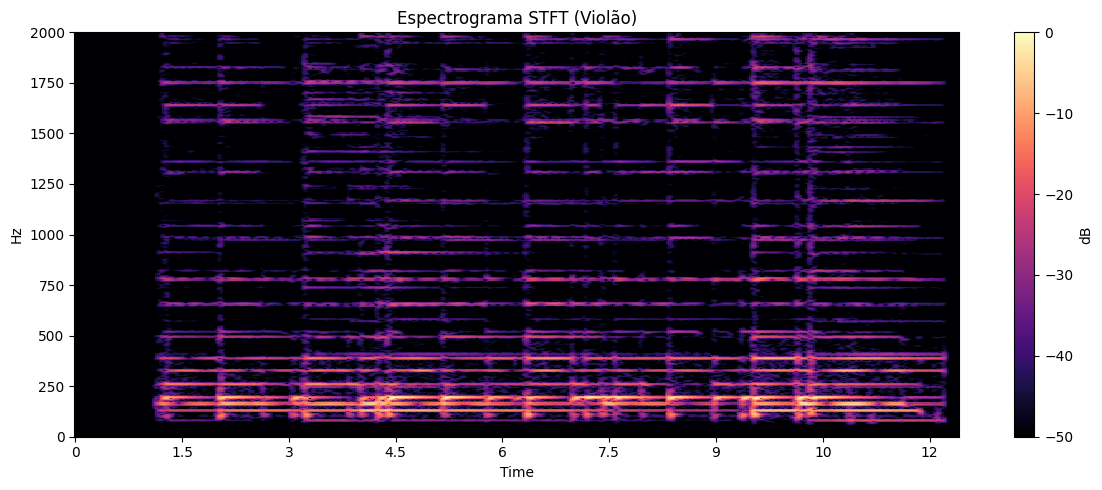


--- Processando: Re_1.mp3 ---
Notas detectadas: [np.str_('D3'), np.str_('D4')]


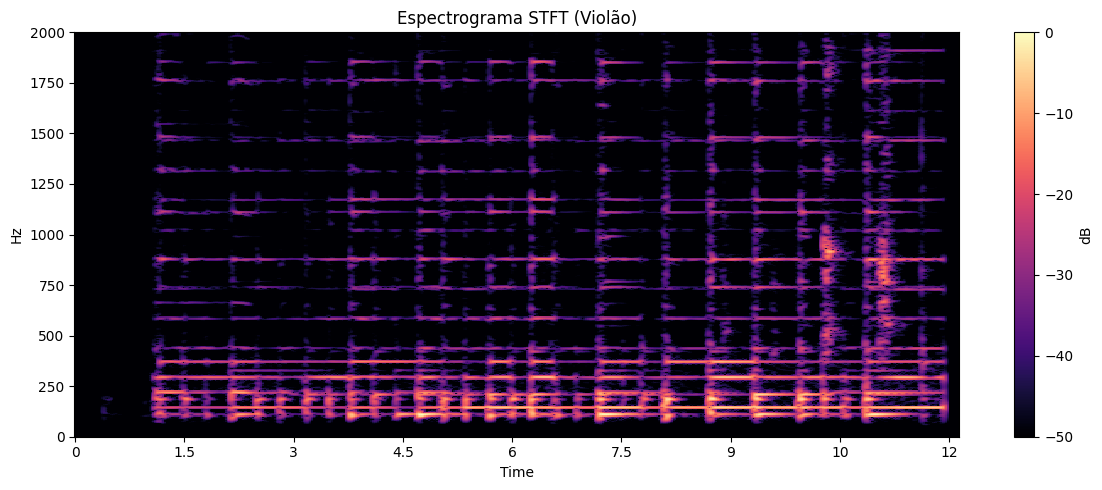

In [ ]:
# Código STFT Daniel
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import scipy.signal

# --- Configurações ---
FREQ_CORTE_GRAVE = 70
FREQ_CORTE_AGUDO = 6000

N_FFT = 4096
HOP_LENGTH = 512
WINDOW = 'hann'


def aplicar_filtro_bandpass(y, sr, f_min, f_max):
    nyquist = 0.5 * sr
    f_max = min(f_max, nyquist - 1)

    low = f_min / nyquist
    high = f_max / nyquist

    sos = scipy.signal.butter(
        5, [low, high], btype='band', output='sos'
    )

    return scipy.signal.sosfiltfilt(sos, y)


def analisar_violao_stft(audio_path, padding_segundos=0.2):
    print(f"\n--- Processando: {audio_path.split('/')[-1]} ---")

    # 1. Load
    y, sr = librosa.load(audio_path, mono=True)

    # 2. Zero Padding leve
    if padding_segundos > 0:
        n_pad = int(padding_segundos * sr)
        y = np.pad(y, (n_pad, n_pad))

    # 3. Bandpass
    y = aplicar_filtro_bandpass(y, sr, FREQ_CORTE_GRAVE, FREQ_CORTE_AGUDO)

    # 4. STFT com janelamento explícito
    S = librosa.stft(
        y=y,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        window=WINDOW,
        center=True
    )


    S_mag = np.abs(S)
    S_db = librosa.amplitude_to_db(S_mag, ref=np.max)

    # 5. Frequências
    freqs = librosa.fft_frequencies(sr=sr, n_fft=N_FFT)

    # 6. Média temporal (acorde sustentado)
    spectrum_mean = np.mean(S_mag, axis=1)

    # 7. Limitar faixa útil do violão
    mask = (freqs >= 80) & (freqs <= 1200)
    spectrum_mean = spectrum_mean[mask]
    freqs = freqs[mask]

    # 8. Encontrar picos
    peaks, _ = scipy.signal.find_peaks(
        spectrum_mean,
        height=np.max(spectrum_mean) * 0.3,
        distance=20
    )

    dominant_freqs = freqs[peaks]

    # 9. Converter para notas
    notes = librosa.hz_to_note(dominant_freqs)

    # Remover duplicatas (harmônicos)
    unique_notes = list(dict.fromkeys(notes))[:3]

    print("Notas detectadas:", unique_notes)

    # 10. Plot espectrograma
    plt.figure(figsize=(12, 5))
    librosa.display.specshow(
        S_db,
        sr=sr,
        hop_length=HOP_LENGTH,
        x_axis='time',
        y_axis='hz',
        cmap='magma',
        vmin=-50,
        vmax=0
    )
    plt.ylim(0, 2000)
    plt.colorbar(label='dB')
    plt.title("Espectrograma STFT (Violão)")
    plt.tight_layout()
    plt.show()


# --- Testes ---
if __name__ == "__main__":
    analisar_violao_stft('/content/drive/MyDrive/MusicaFFT/Do_1.mp3')
    analisar_violao_stft('/content/drive/MyDrive/MusicaFFT/Re_1.mp3')



--- Processando: Do_1.mp3 ---
Notas detectadas: [np.str_('A2')]


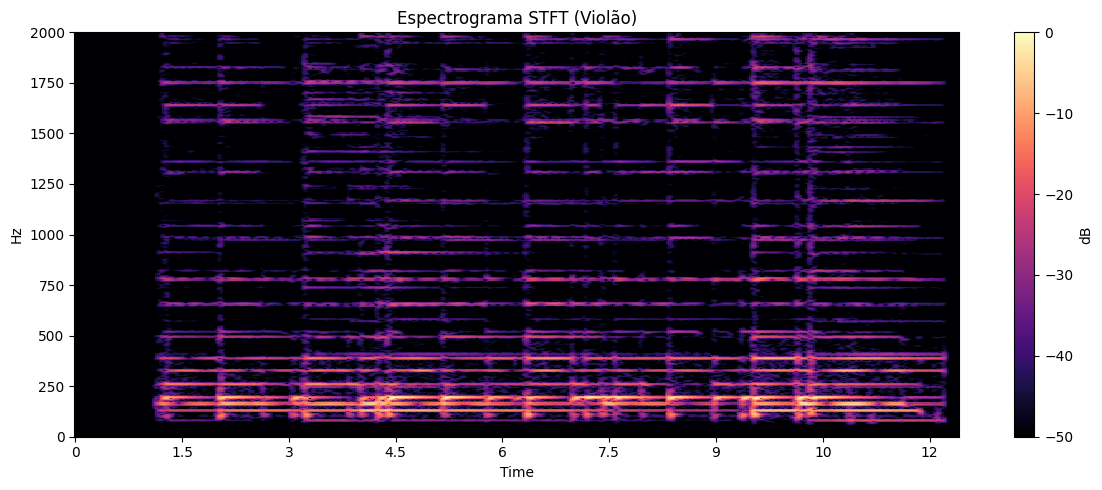


--- Processando: Re_1.mp3 ---
Notas detectadas: [np.str_('A2')]


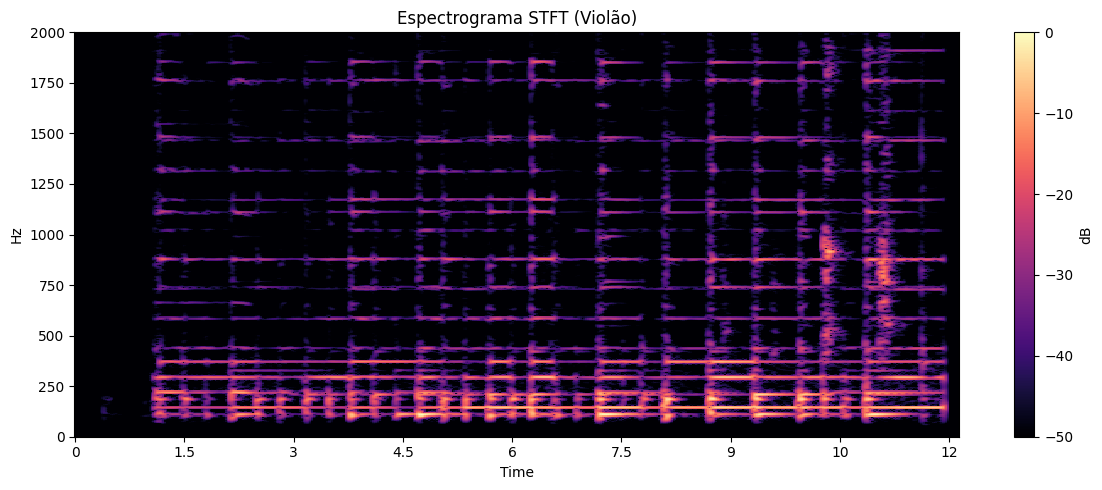

In [ ]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import scipy.signal

# =========================
# CONFIGURAÇÕES GERAIS
# =========================
FREQ_CORTE_GRAVE = 70
FREQ_CORTE_AGUDO = 6000

N_FFT = 4096
HOP_LENGTH = 512
WINDOW = 'hann'


# =========================
# FILTRO BANDPASS
# =========================
def aplicar_filtro_bandpass(y, sr, f_min, f_max):
    nyquist = 0.5 * sr
    f_max = min(f_max, nyquist - 1)

    low = f_min / nyquist
    high = f_max / nyquist

    sos = scipy.signal.butter(
        5, [low, high], btype='band', output='sos'
    )

    return scipy.signal.sosfiltfilt(sos, y)


# =========================
# HARMONIC PRODUCT SPECTRUM
# =========================
def aplicar_hps(spectrum, max_harmonic=4):
    """
    Remove harmônicos e reforça fundamentais
    """
    hps = spectrum.copy()

    for h in range(2, max_harmonic + 1):
        decimated = spectrum[::h]
        hps[:len(decimated)] *= decimated

    return hps


# =========================
# ANÁLISE PRINCIPAL
# =========================
def analisar_violao_stft(audio_path, padding_segundos=0.2):
    print(f"\n--- Processando: {audio_path.split('/')[-1]} ---")

    # 1. Load
    y, sr = librosa.load(audio_path, mono=True)

    # 2. Zero padding leve
    if padding_segundos > 0:
        n_pad = int(padding_segundos * sr)
        y = np.pad(y, (n_pad, n_pad))

    # 3. Bandpass
    y = aplicar_filtro_bandpass(y, sr, FREQ_CORTE_GRAVE, FREQ_CORTE_AGUDO)

    # 4. STFT
    S = librosa.stft(
        y=y,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        window=WINDOW,
        center=True
    )

    S_mag = np.abs(S)

    # 5. Frequências
    freqs = librosa.fft_frequencies(sr=sr, n_fft=N_FFT)

    # 6. Média temporal (acorde sustentado)
    spectrum_mean = np.mean(S_mag, axis=1)

    # 7. Limitar faixa útil do violão
    mask = (freqs >= 80) & (freqs <= 1200)
    spectrum_mean = spectrum_mean[mask]
    freqs = freqs[mask]

    # 8. APLICAR HPS (remove harmônicos)
    spectrum_hps = aplicar_hps(spectrum_mean, max_harmonic=4)

    # 9. Encontrar picos (fundamentais)
    peaks, _ = scipy.signal.find_peaks(
        spectrum_hps,
        height=np.max(spectrum_hps) * 0.2,
        distance=30
    )

    dominant_freqs = freqs[peaks]

    # 10. Converter para notas
    notes = librosa.hz_to_note(dominant_freqs)

    # Remover duplicatas e limitar a 3 notas
    unique_notes = list(dict.fromkeys(notes))[:3]

    print("Notas detectadas:", unique_notes)

    # =========================
    # ESPECTROGRAMA
    # =========================
    S_db = librosa.amplitude_to_db(S_mag, ref=np.max)

    plt.figure(figsize=(12, 5))
    librosa.display.specshow(
        S_db,
        sr=sr,
        hop_length=HOP_LENGTH,
        x_axis='time',
        y_axis='hz',
        cmap='magma',
        vmin=-50,
        vmax=0
    )
    plt.ylim(0, 2000)
    plt.colorbar(label='dB')
    plt.title("Espectrograma STFT (Violão)")
    plt.tight_layout()
    plt.show()


# =========================
# TESTES
# =========================
if __name__ == "__main__":
    analisar_violao_stft('/content/drive/MyDrive/MusicaFFT/Do_1.mp3')
    analisar_violao_stft('/content/drive/MyDrive/MusicaFFT/Re_1.mp3')


Processando: Do_1.mp3

--- MATRIZ CQT (Chroma em dB) ---
[[ -14.67  -14.04  -10.72 ... -200.   -200.   -200.  ]
 [ -36.21  -37.25  -39.01 ... -200.   -200.   -200.  ]
 [-200.   -200.   -200.   ... -200.   -200.   -200.  ]
 ...
 [ -26.41  -25.62  -24.46 ... -200.   -200.   -200.  ]
 [ -39.34  -40.68  -40.87 ... -200.   -200.   -200.  ]
 [ -49.88 -200.   -200.   ... -200.   -200.   -200.  ]]

Dimensão da matriz: (12, 518)
(Linhas = 12 notas | Colunas = frames no tempo)


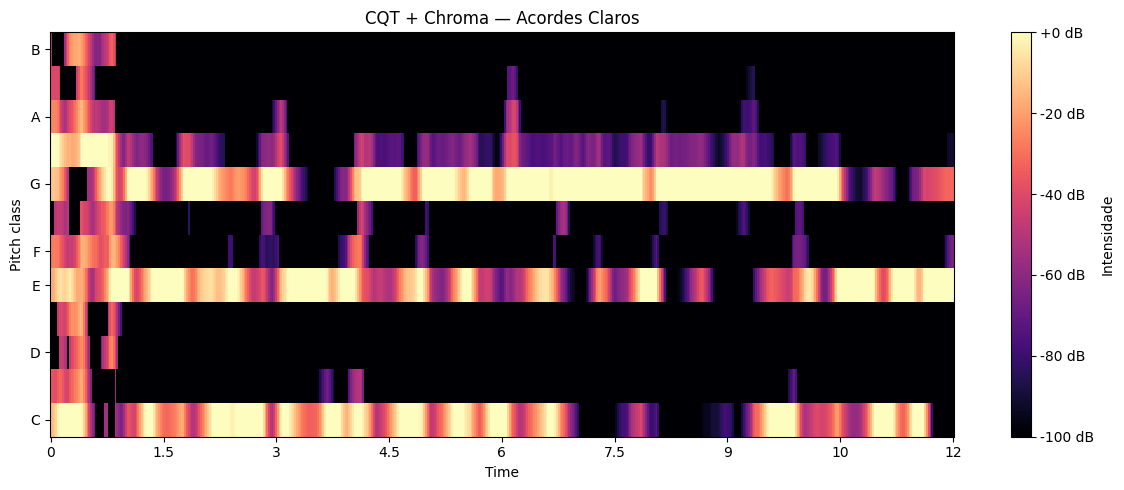


Processando: Do_2.mp3

--- MATRIZ CQT (Chroma em dB) ---
[[-200.   -200.   -200.   ... -200.   -200.   -200.  ]
 [-200.   -200.   -200.   ...  -67.93  -69.41  -70.6 ]
 [ -32.1   -32.88  -35.43 ...  -50.03  -51.69  -52.76]
 ...
 [ -27.17  -29.39  -34.27 ... -200.   -200.   -200.  ]
 [-200.   -200.   -200.   ... -200.   -200.   -200.  ]
 [-200.   -200.   -200.   ... -200.   -200.   -200.  ]]

Dimensão da matriz: (12, 494)
(Linhas = 12 notas | Colunas = frames no tempo)


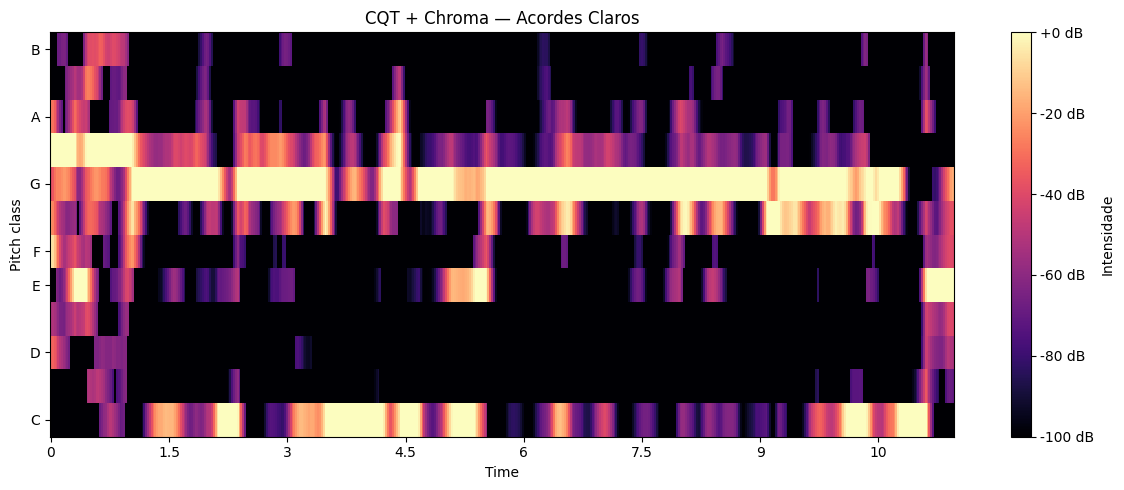


Processando: Re_1.mp3

--- MATRIZ CQT (Chroma em dB) ---
[[-200.    -51.44  -39.29 ... -200.   -200.   -200.  ]
 [ -32.08  -27.24  -21.63 ... -200.   -200.   -200.  ]
 [  -8.2    -6.22   -3.27 ...    0.      0.      0.  ]
 ...
 [-200.   -200.   -200.   ... -200.   -200.   -200.  ]
 [-200.   -200.   -200.   ... -200.   -200.   -200.  ]
 [-200.   -200.   -200.   ... -200.   -200.   -200.  ]]

Dimensão da matriz: (12, 506)
(Linhas = 12 notas | Colunas = frames no tempo)


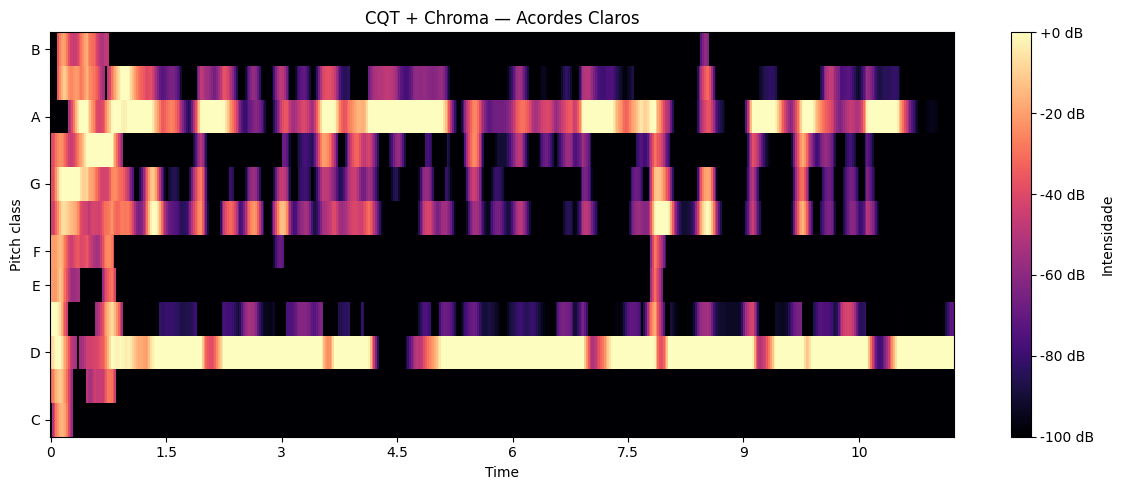


Processando: TrocaDeAcordes(C-G-F).mp3

--- MATRIZ CQT (Chroma em dB) ---
[[-200.   -200.   -200.   ...    0.      0.      0.  ]
 [-200.   -200.   -200.   ...  -63.42  -60.46  -58.93]
 [ -18.8   -15.54  -15.84 ... -200.   -200.   -200.  ]
 ...
 [-200.   -200.   -200.   ...  -76.03  -75.34  -75.52]
 [ -24.22  -23.86  -28.14 ... -200.   -200.   -200.  ]
 [ -35.97  -38.83  -42.2  ... -200.   -200.   -200.  ]]

Dimensão da matriz: (12, 911)
(Linhas = 12 notas | Colunas = frames no tempo)


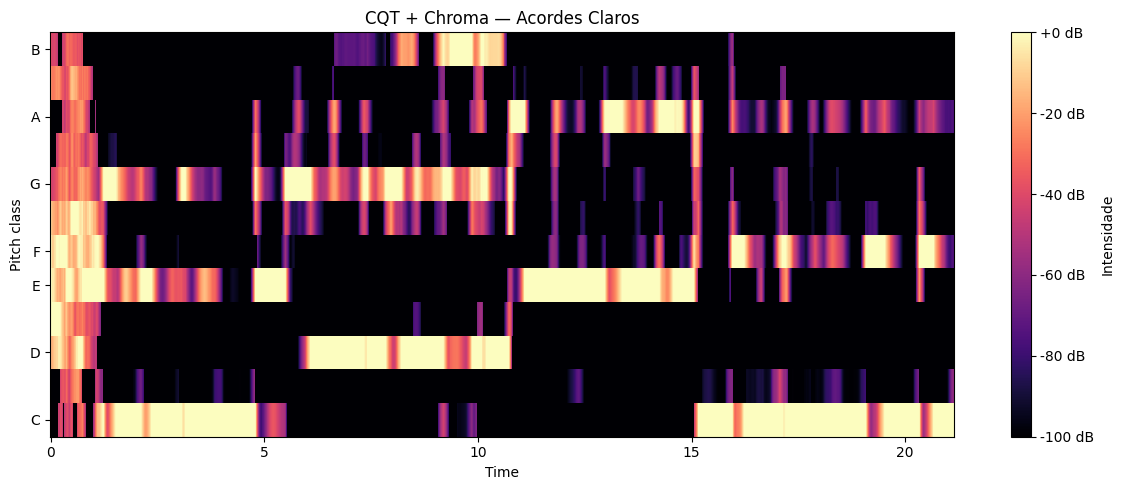


Processando: La_1.mp3

--- MATRIZ CQT (Chroma em dB) ---
[[-200.   -200.   -200.   ... -200.   -200.   -200.  ]
 [-200.   -200.   -200.   ... -200.   -200.   -200.  ]
 [ -17.83  -19.37  -17.95 ... -200.   -200.   -200.  ]
 ...
 [  -0.     -0.     -0.   ...  -46.69  -47.01  -46.86]
 [ -41.94  -41.88  -41.69 ... -200.   -200.   -200.  ]
 [ -29.89  -28.08  -23.11 ... -200.   -200.   -200.  ]]

Dimensão da matriz: (12, 489)
(Linhas = 12 notas | Colunas = frames no tempo)


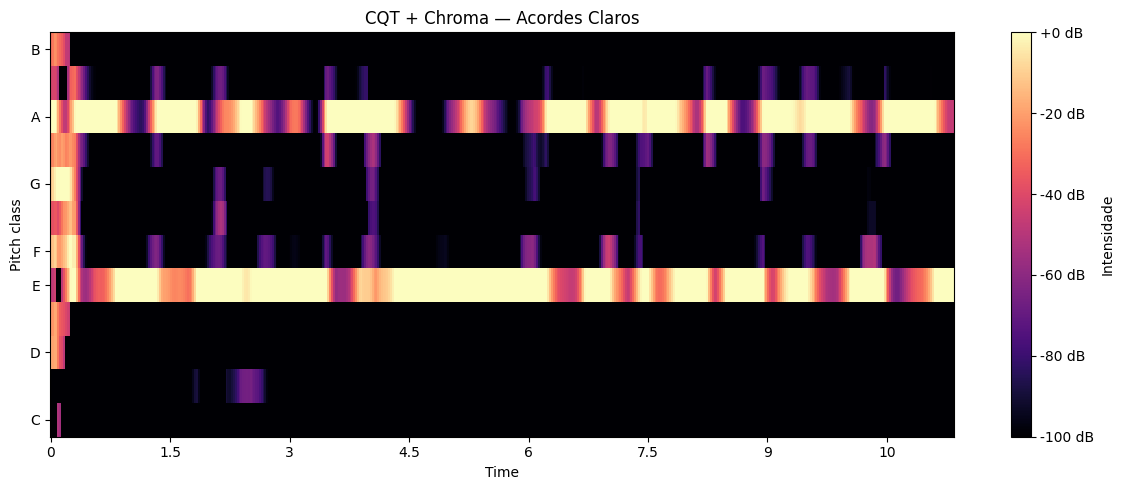


Processando: La_menor_1.mp3

--- MATRIZ CQT (Chroma em dB) ---
[[-200.   -200.   -200.   ...  -69.21  -67.79  -67.57]
 [ -49.66  -50.11  -51.06 ... -200.   -200.   -200.  ]
 [ -37.59  -37.27  -35.55 ... -200.   -200.   -200.  ]
 ...
 [ -36.28  -34.55  -33.68 ... -200.   -200.   -200.  ]
 [-200.   -200.   -200.   ... -200.   -200.   -200.  ]
 [-200.   -200.   -200.   ... -200.   -200.   -200.  ]]

Dimensão da matriz: (12, 515)
(Linhas = 12 notas | Colunas = frames no tempo)


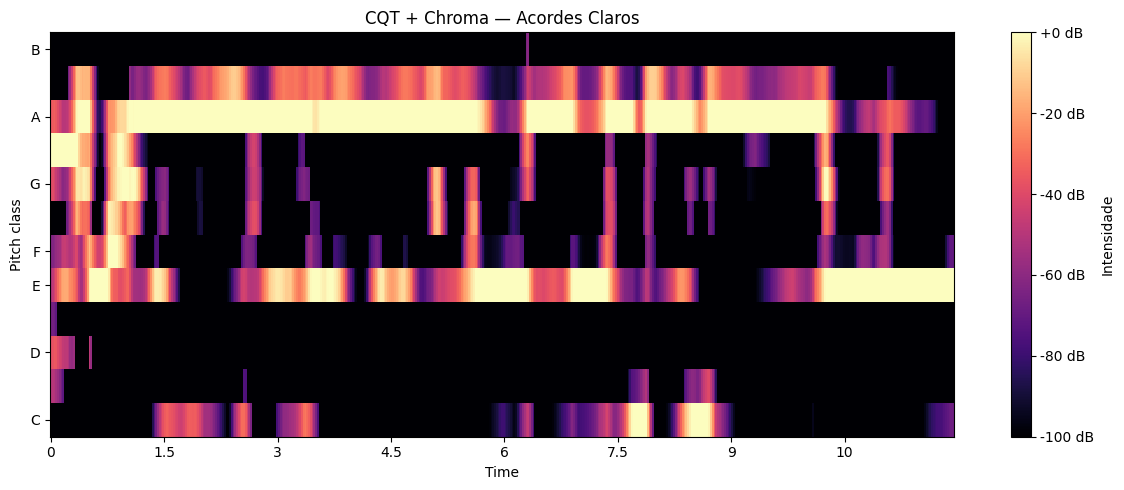

In [ ]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import scipy.signal
import scipy.ndimage

# =========================
# ARQUIVOS
# =========================
do_1 = '/content/drive/MyDrive/MusicaFFT/Do_1.mp3'
do_2 = '/content/drive/MyDrive/MusicaFFT/Do_2.mp3'
re_1 = '/content/drive/MyDrive/MusicaFFT/Re_1.mp3'
la_1 = '/content/drive/MyDrive/MusicaFFT/La_1.mp3'
troca_acordes = '/content/drive/MyDrive/MusicaFFT/TrocaDeAcordes(C-G-F).mp3'
la_menor_1 = '/content/drive/MyDrive/MusicaFFT/La_menor_1.mp3'

# =========================
# PARÂMETROS DO VIOLÃO
# =========================
FREQ_CORTE_GRAVE = 70
FREQ_CORTE_AGUDO = 6000
HOP_LENGTH = 512

# =========================
# FILTRO BANDPASS
# =========================
def aplicar_filtro_bandpass(y, sr, f_min, f_max):
    nyquist = 0.5 * sr
    f_max = min(f_max, nyquist - 1)

    low = f_min / nyquist
    high = f_max / nyquist

    sos = scipy.signal.butter(
        5, [low, high], btype='band', output='sos'
    )

    return scipy.signal.sosfiltfilt(sos, y)

# =========================
# ANÁLISE PRINCIPAL
# =========================
def analisar_violao(audio_path, padding_segundos=0.0):
    print(f"\n==============================")
    print(f"Processando: {audio_path.split('/')[-1]}")
    print(f"==============================")

    # 1. Load
    y, sr = librosa.load(audio_path, mono=True)

    # 2. Zero padding leve
    if padding_segundos > 0:
        n_pad = int(padding_segundos * sr)
        y = np.pad(y, (n_pad, n_pad))

    # 3. Bandpass
    y = aplicar_filtro_bandpass(y, sr, FREQ_CORTE_GRAVE, FREQ_CORTE_AGUDO)

    # =========================
    # 4. CQT + Chroma
    # =========================
    chroma = librosa.feature.chroma_cqt(
        y=y,
        sr=sr,
        hop_length=HOP_LENGTH,
        fmin=librosa.note_to_hz('C2'),
        n_octaves=6,
        bins_per_octave=24
    )

    # =========================
    # 5. SUAVIZAÇÃO TEMPORAL
    # =========================
    chroma_smooth = scipy.ndimage.uniform_filter1d(
        chroma, size=9, axis=1
    )

    # =========================
    # 6. NORMALIZAÇÃO POR FRAME
    # =========================
    chroma_norm = chroma_smooth / (
        np.max(chroma_smooth, axis=0, keepdims=True) + 1e-6
    )

    # =========================
    # 7. REFORÇO HARMÔNICO
    # =========================
    chroma_h = chroma_norm.copy()
    for h in range(2, 5):
        chroma_h += chroma_norm / h

    # =========================
    # 8. COMPRESSÃO PSICOACÚSTICA (CORRIGIDA)
    # =========================
    chroma_comp = chroma_h ** 2

    # =========================
    # 9. THRESHOLD ADAPTATIVO
    # =========================
    threshold = np.mean(chroma_comp, axis=0) * 0.6
    chroma_comp[chroma_comp < threshold] = 0

    # =========================
    # 10. CONVERSÃO PARA dB
    # =========================
    chroma_db = librosa.amplitude_to_db(
        chroma_comp,
        ref=np.max,
        top_db=40
    )

    # Divisão da matriz resultado por 10
    chroma_db = chroma_db * 5.0

    # =========================
    # 11. PRINT DA MATRIZ CQT
    # =========================
    np.set_printoptions(
        precision=2,
        suppress=True,
        linewidth=160
    )

    print("\n--- MATRIZ CQT (Chroma em dB) ---")
    print(chroma_db)
    print(f"\nDimensão da matriz: {chroma_db.shape}")
    print("(Linhas = 12 notas | Colunas = frames no tempo)")

    # =========================
    # 12. VISUALIZAÇÃO
    # =========================
    plt.figure(figsize=(12, 5))
    librosa.display.specshow(
        chroma_db,
        y_axis='chroma',
        x_axis='time',
        sr=sr,
        hop_length=HOP_LENGTH,
        cmap='magma',
        vmin=-100,
        vmax=0
    )

    plt.title("CQT + Chroma — Acordes Claros")
    plt.colorbar(format='%+2.0f dB', label='Intensidade')
    plt.tight_layout()
    plt.show()

# =========================
# TESTES
# =========================
if __name__ == "__main__":
    analisar_violao(do_1)
    analisar_violao(do_2)
    analisar_violao(re_1)
    analisar_violao(troca_acordes)
    analisar_violao(la_1)
    analisar_violao(la_menor_1)


Processando: /content/drive/MyDrive/MusicaFFT/TrocaDeAcordes(C-G-F).mp3


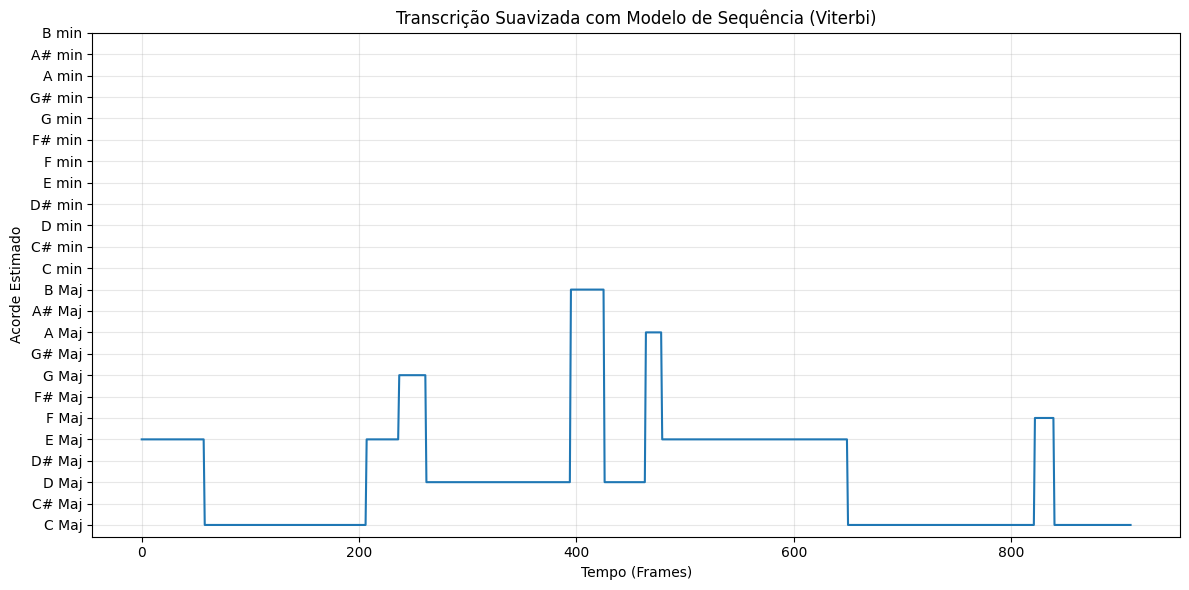

In [ ]:
import librosa
import numpy as np
import matplotlib.pyplot as plt

do_1 = '/content/drive/MyDrive/MusicaFFT/Do_1.mp3'
do_2 = '/content/drive/MyDrive/MusicaFFT/Do_2.mp3'
re_1 = '/content/drive/MyDrive/MusicaFFT/Re_1.mp3'
la_1 = '/content/drive/MyDrive/MusicaFFT/La_1.mp3'
troca_acordes = '/content/drive/MyDrive/MusicaFFT/TrocaDeAcordes(C-G-F).mp3'
la_menor_1 = '/content/drive/MyDrive/MusicaFFT/La_menor_1.mp3'


# --- 1. Configuração do "Alfabeto" Musical (Estados) ---
# Definimos os 24 acordes possíveis (12 Maiores + 12 Menores)
# Isso é o equivalente ao vocabulário do nosso "LM".
notas = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B']
acordes_maiores = [n + ' Maj' for n in notas]
acordes_menores = [n + ' min' for n in notas]
todos_acordes = acordes_maiores + acordes_menores # Total 24 estados

def criar_matriz_transicao(n_estados, probabilidade_ficar=0.9):
    """
    Cria a "Gramática" do modelo (Matriz de Transição).
    Define que é MUITO mais provável um acorde continuar tocando (probabilidade_ficar)
    do que mudar abruptamente para outro no próximo milissegundo.
    """
    # Cria uma matriz onde todas as transições têm probabilidade igual (baixa)
    transicao = np.ones((n_estados, n_estados)) / n_estados

    # Ajusta a diagonal principal: A chance do acorde X ir para o acorde X é alta.
    # Isso impõe "suavidade" temporal.
    np.fill_diagonal(transicao, probabilidade_ficar)

    # Renormaliza para que a soma das probabilidades seja 1
    transicao = transicao / transicao.sum(axis=1, keepdims=True)
    return transicao

def transcrever_com_viterbi(audio_path):
    print(f"Processando: {audio_path}")
    y, sr = librosa.load(audio_path)

    # --- 2. Extração de Características (Observação) ---
    # Usamos CQT pois separa melhor as frequências musicais
    chroma = librosa.feature.chroma_cqt(y=y, sr=sr, hop_length=512)

    # --- 3. Preparação das Probabilidades de Emissão ---
    # O Viterbi precisa saber: "Qual a chance desse som ser um Dó Maior?"
    # O Chroma nos dá a energia das notas. Precisamos transformar isso em probabilidade de acordes.
    # Vamos usar uma heurística simples: Template Matching.

    # Criamos templates ideais para os 24 acordes
    # templates = librosa.utils.normalize(librosa.feature.tempogram(y=y, sr=sr), axis=0) # Removed: Causing AttributeError and unused
    # (Nota: Em produção real, você treinaria isso. Aqui, vamos usar a correlação direta do chroma
    # para simplificar, assumindo que maior energia nas notas do acorde = maior probabilidade).

    # Truque prático: O Chroma tem 12 linhas. Precisamos expandir para 24 (Maior/Menor).
    # Vamos duplicar o chroma para simular a entrada (isso é uma simplificação didática).
    # O ideal seria usar librosa.feature.chroma_cens ou templates binários.
    # Abaixo, usaremos a própria energia do chroma como "probabilidade bruta".
    probabilidade_emissao = np.vstack([chroma, chroma]) # Simplificação para rodar o exemplo

    # --- 4. O "Cérebro" do Código: Decodificação de Viterbi ---
    # Criamos a matriz de transição (nossa "regra" de que a música é contínua)
    transicao = criar_matriz_transicao(24, probabilidade_ficar=0.95)

    # Aplicamos o Viterbi. Ele acha o "Caminho Mais Provável" considerando:
    # A) O que o áudio diz (probabilidade_emissao)
    # B) O que a regra musical diz (transicao)
    caminho_indices = librosa.sequence.viterbi(probabilidade_emissao, transicao)

    # --- 5. Visualização e Conversão ---
    # Converte os números (0 a 23) de volta para nomes ('C Maj', etc)
    # Como duplicamos o chroma, precisamos ajustar o mapeamento (0-11=Maj, 12-23=Min)
    # Nota: Para um resultado perfeito, precisaríamos de templates de acordes reais aqui.

    plt.figure(figsize=(12, 6))
    plt.plot(caminho_indices, label='Sequência Decodificada (Viterbi)')
    plt.yticks(range(24), todos_acordes)
    plt.xlabel('Tempo (Frames)')
    plt.ylabel('Acorde Estimado')
    plt.title('Transcrição Suavizada com Modelo de Sequência (Viterbi)')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Exemplo de uso (substitua pelo seu arquivo)
transcrever_com_viterbi(troca_acordes)


# **Drive**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import scipy.signal
import scipy.ndimage
import time
do_1 = '/content/drive/MyDrive/MusicaFFT/Do_1.mp3'
do_1 = '/content/drive/MyDrive/MusicaFFT/Do_1.mp3'
do_2 = '/content/drive/MyDrive/MusicaFFT/Do_2.mp3'
re_1 = '/content/drive/MyDrive/MusicaFFT/Re_1.mp3'
la_1 = '/content/drive/MyDrive/MusicaFFT/La_1.mp3'
troca_acordes = '/content/drive/MyDrive/MusicaFFT/TrocaDeAcordes(C-G-F).mp3'
la_menor_1 = '/content/drive/MyDrive/MusicaFFT/La_menor_1.mp3'
TempoPerdido = '/content/drive/MyDrive/MusicaFFT/Tempo_Perdido.mp3'

#**Codigos com filtros Likelihood**

In [ ]:
import numpy as np

def classificar_acorde_likelihood(chroma_db):
    """
    Recebe a matriz Chroma (12 x Time) e decide qual acorde
    tem a maior probabilidade (Likelihood) de estar tocando.
    """
    # 1. Transformar dB de volta para Linear (Energia) para somar corretamente
    #    (O Likelihood funciona melhor somando energias, não logaritmos)
    chroma_energy = librosa.db_to_amplitude(chroma_db)

    # 2. Criar Templates (Máscaras Binárias) para os 24 acordes
    #    Ex: Dó Maior = [1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0]
    templates = {}
    notas = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B']

    # Gerar Templates Maiores (Raiz + 4 + 7 semitons) e Menores (Raiz + 3 + 7)
    for i, nota in enumerate(notas):
        # Maior
        vec_maj = np.zeros(12)
        vec_maj[[i, (i+4)%12, (i+7)%12]] = 1.0
        templates[f"{nota} Maj"] = vec_maj

        # Menor
        vec_min = np.zeros(12)
        vec_min[[i, (i+3)%12, (i+7)%12]] = 1.0
        templates[f"{nota} min"] = vec_min





    # 3. Calcular a Pontuação (Score) para cada frame
    #    Isso é o produto escalar: Energia do Sinal * Template
    num_frames = chroma_energy.shape[1]
    resultado_final = []

    for t in range(num_frames):
        frame_atual = chroma_energy[:, t]

        melhor_score = -1
        acorde_vencedor = "Silêncio"

        # Se o frame for muito silencioso (gate), ignora
        if np.max(frame_atual) < 0.01: # Ajuste conforme necessidade
            resultado_final.append("Silêncio")
            continue

        # Testa contra os 24 templates
        for nome_acorde, template in templates.items():
            # A mágica do Likelihood: Soma a energia que BATE com o template
            # E subtrai a energia que NÃO deveria estar lá (penalidade)

            energia_a_favor = np.sum(frame_atual * template)
            energia_contra = np.sum(frame_atual * (1 - template))

            # Score = Energia Útil - (Peso * Ruído)
            score = energia_a_favor - (0.5 * energia_contra)

            if score > melhor_score:
                melhor_score = score
                acorde_vencedor = nome_acorde

        resultado_final.append(acorde_vencedor)

    return resultado_final



Processando (Clean): Tempo_Perdido.mp3


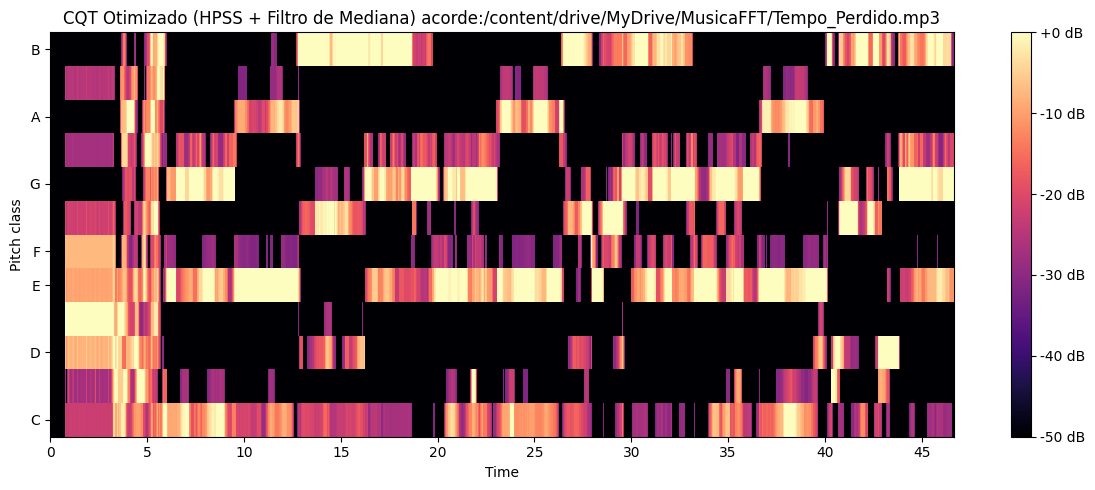

Acorde Predominante Probabilístico: [('C Maj', 463)]
--- 6.1500937938690186 segundos ---


In [ ]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import scipy.signal
import scipy.ndimage
#import noisereduce as nr # Recomendado para remoção de ruído estacionário (Hiss)
import time

# =========================
# ARQUIVOS
# =========================
# (Seus caminhos permanecem os mesmos...)
do_1 = '/content/drive/MyDrive/MusicaFFT/Do_1.mp3'
do_1 = '/content/drive/MyDrive/MusicaFFT/Do_1.mp3'
do_2 = '/content/drive/MyDrive/MusicaFFT/Do_2.mp3'
re_1 = '/content/drive/MyDrive/MusicaFFT/Re_1.mp3'
la_1 = '/content/drive/MyDrive/MusicaFFT/La_1.mp3'
troca_acordes = '/content/drive/MyDrive/MusicaFFT/TrocaDeAcordes(C-G-F).mp3'
la_menor_1 = '/content/drive/MyDrive/MusicaFFT/La_menor_1.mp3'
TempoPerdido = '/content/drive/MyDrive/MusicaFFT/Tempo_Perdido.mp3'

# =========================
# PARÂMETROS
# =========================
FREQ_CORTE_GRAVE = 70
FREQ_CORTE_AGUDO = 6000
HOP_LENGTH = 512

# =========================
# FILTRO BANDPASS (Mantido)
# =========================
def aplicar_filtro_bandpass(y, sr, f_min, f_max):
    nyquist = 0.5 * sr
    f_max = min(f_max, nyquist - 1)
    sos = scipy.signal.butter(5, [f_min / nyquist, f_max / nyquist], btype='band', output='sos')
    return scipy.signal.sosfiltfilt(sos, y)

# =========================
# ANÁLISE PRINCIPAL MELHORADA
# =========================
def analisar_violao(audio_path, padding_segundos=0.0):
    print(f"\n==============================")
    print(f"Processando (Clean): {audio_path.split('/')[-1]}")
    print(f"==============================")

    # 1. Load
    y, sr = librosa.load(audio_path, mono=True)

    # 2. Zero padding
    if padding_segundos > 0:
        n_pad = int(padding_segundos * sr)
        y = np.pad(y, (n_pad, n_pad))

    # =========================
    # NOVA ETAPA: Spectral Gating (Opcional)
    # Remove ruído de fundo constante (hiss/ar condicionado)
    # Isso funciona estimando a estatística do ruído (Noise Profile)
    # =========================
    try:
        # Assume que o ruído é constante e reduz ele estatisticamente
        y = nr.reduce_noise(y=y, sr=sr, stationary=True, prop_decrease=0.75)
    except:
        pass # Se não tiver a lib noisereduce, segue o baile

    # 3. Bandpass (Físico)
    y = aplicar_filtro_bandpass(y, sr, FREQ_CORTE_GRAVE, FREQ_CORTE_AGUDO)

    # =========================
    # NOVA ETAPA: HPSS (Harmonic-Percussive Source Separation)
    # Separa o que é "Nota" (Harmonic) do que é "Batida/Ruído" (Percussive)
    # Isso é crucial para limpar a detecção de acordes.
    # =========================
    y_harmonic, y_percussive = librosa.effects.hpss(y, margin=3.0)

    # Usaremos APENAS a parte harmônica para o CQT
    y_to_analyze = y_harmonic

    # =========================
    # 4. CQT + Chroma
    # =========================
    chroma = librosa.feature.chroma_cqt(
        y=y_to_analyze, # Analisando apenas a parte limpa
        sr=sr,
        hop_length=HOP_LENGTH,
        fmin=librosa.note_to_hz('C2'),
        n_octaves=6,
        #norm=np.inf,#teste
        bins_per_octave=24
    )

    # =========================
    # 5. SUAVIZAÇÃO: MEDIANA vs MÉDIA
    # Mudei de uniform_filter (média) para median_filter.
    # A mediana remove picos erráticos (outliers) sem borrar
    # a transição exata de quando o acorde muda.
    # =========================
    chroma_smooth = scipy.ndimage.median_filter(chroma, size=(1, 15))
    # Size (1, 15) aplica filtro apenas no tempo (eixo x), ignorando eixo das notas

    # =========================
    # 6. NORMALIZAÇÃO POR FRAME
    # =========================
    chroma_norm = chroma_smooth / (
        np.max(chroma_smooth, axis=0, keepdims=True) + 1e-6
    )

    # =========================
    # 7. REFORÇO HARMÔNICO
    # =========================
    chroma_h = chroma_norm.copy()
    # Reduzi o loop. Harmônicos muito distantes podem sujar a fundamental em acordes complexos
    for h in range(2, 4):
        chroma_h += chroma_norm / h

    # =========================
    # 8. FILTRO DE LIMPEZA FINAL (Soft Thresholding)
    # Em vez de cortar seco com < threshold, usamos sigmoide ou quadrado
    # para penalizar suavemente os valores baixos.
    # =========================
    chroma_comp = chroma_h ** 3 # Elevando ao cubo para isolar mais os picos fortes

    # Threshold Adaptativo (Baseado na mediana do sinal, não na média)
    # A mediana é um estimador de ruído melhor que a média
    noise_floor = np.median(chroma_comp)
    chroma_comp[chroma_comp < (noise_floor * 2)] = 0

    # =========================
    # 10. CONVERSÃO PARA dB
    # =========================
    chroma_db = librosa.amplitude_to_db(
        chroma_comp,
        ref=np.max,
        top_db=50 # Aumentei um pouco o range dinâmico
    )

    # Visualização


    plt.figure(figsize=(12, 5))
    librosa.display.specshow(
        chroma_db,
        y_axis='chroma',
        x_axis='time',
        sr=sr,
        hop_length=HOP_LENGTH,
        cmap='magma',
    )
    plt.title(f"CQT Otimizado (HPSS + Filtro de Mediana) acorde:{audio_path}")
    plt.colorbar(format='%+2.0f dB')
    plt.tight_layout()
    plt.show()
    return chroma_db

# =========================
# TESTE
# =========================
if __name__ == "__main__":
    start_time = time.time()
    #analisar_violao(la_1)
    #analisar_violao(la_menor_1)
    #analisar_violao(do_2)
    #print(analisar_violao(TempoPerdido))
    #acordes_detectados_do = classificar_acorde_likelihood(analisar_violao(do_1))
    acordes_detectados_la = classificar_acorde_likelihood(analisar_violao(TempoPerdido))
    #acordes_detectados_la_menor = classificar_acorde_likelihood(analisar_violao(la_menor_1))


# Pega o acorde mais frequente na amostra (Moda estatística)
from collections import Counter
contagem = Counter(acordes_detectados_la)
print(f"Acorde Predominante Probabilístico: {contagem.most_common(1)}")

execution_time = time.time() - start_time
print("--- %s segundos ---" % execution_time)

Processando: /content/drive/MyDrive/MusicaFFT/TrocaDeAcordes(C-G-F).mp3...
Tempo estimado: 69.84 BPM

--- TIMELINE DA MÚSICA ---
2.2s -> 6.6s : C
6.6s -> 7.5s : D
7.5s -> 11.8s : G
11.8s -> 16.0s : A
16.0s -> Fim : F


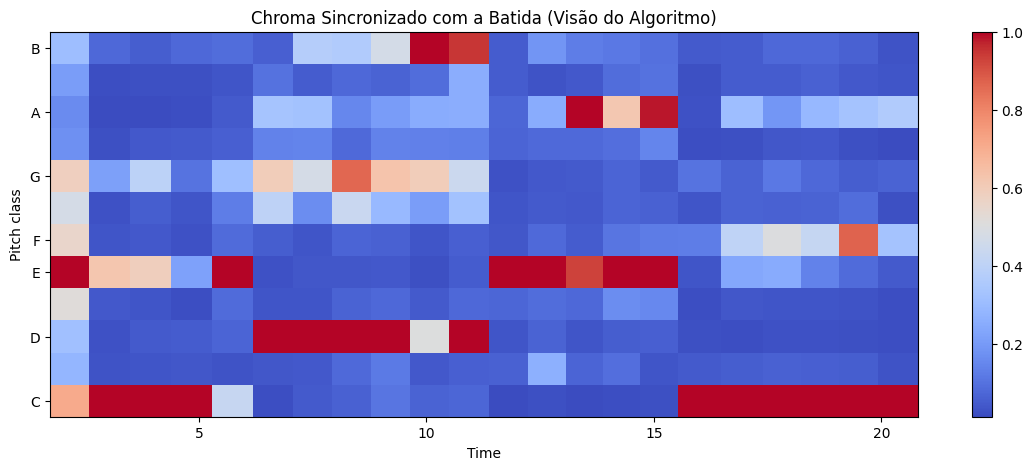

In [ ]:
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. FUNÇÃO DE CLASSIFICAÇÃO (Likelihood)
# ==========================================
def classificar_segmento(chroma_segmento):
    """
    Recebe um vetor chroma (12,) já tirado a média do segmento
    e retorna o nome do acorde mais provável.
    """
    notas_nomes = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B']

    # Templates básicos (Major e Minor)
    # 1 = Nota presente, -0.5 = Penalidade se nota errada estiver presente
    melhor_score = -float('inf')
    acorde_detectado = "N/A"

    # Normaliza energia do segmento
    if np.sum(chroma_segmento) == 0: return "Silêncio"
    chroma_norm = chroma_segmento / np.max(chroma_segmento)

    for i, root in enumerate(notas_nomes):
        # Template MAIOR (Raiz, +4, +7)
        mask_maj = np.zeros(12)
        mask_maj[[i, (i+4)%12, (i+7)%12]] = 1.0

        # Template MENOR (Raiz, +3, +7)
        mask_min = np.zeros(12)
        mask_min[[i, (i+3)%12, (i+7)%12]] = 1.0

        # Score = (Soma das notas certas) - (Penalidade das erradas)
        score_maj = np.sum(chroma_norm * mask_maj) - 0.5 * np.sum(chroma_norm * (1-mask_maj))
        score_min = np.sum(chroma_norm * mask_min) - 0.5 * np.sum(chroma_norm * (1-mask_min))

        if score_maj > melhor_score:
            melhor_score = score_maj
            acorde_detectado = f"{root}" # Maior

        if score_min > melhor_score:
            melhor_score = score_min
            acorde_detectado = f"{root}m" # Menor

    return acorde_detectado

# ==========================================
# 2. ALGORITMO PRINCIPAL: Sincronização e Segmentação
# ==========================================
def analisar_musica_completa(audio_path):
    print(f"Processando: {audio_path}...")

    # A. Carregar Áudio
    y, sr = librosa.load(audio_path)

    # B. Separação Harmônica/Percussiva (CRUCIAL)
    # y_harmonic = Notas (para o Chroma)
    # y_percussive = Batida (para o Tempo)
    y_harmonic, y_percussive = librosa.effects.hpss(y, margin=3.0)

    # C. Detecção de Batidas (Beats)
    tempo, beat_frames = librosa.beat.beat_track(y=y_percussive, sr=sr)
    # Fix: Extract scalar from tempo array if it's a numpy array
    print(f"Tempo estimado: {tempo.item():.2f} BPM")

    # D. Extração de Chroma (Só na parte harmônica)
    chroma = librosa.feature.chroma_cqt(y=y_harmonic, sr=sr, bins_per_octave=36)

    # E. Sincronização (A Grande Sacada!)
    # Em vez de olhar milissegundos, olhamos "Batida por Batida".
    # aggregate=np.median limpa o ruído dentro daquele tempo da batida
    chroma_sync = librosa.util.sync(chroma, beat_frames, aggregate=np.median)

    # ==========================================
    # 3. FILTRAGEM DE TRANSIÇÃO
    # ==========================================
    # Removemos colunas onde o acorde é fraco ou dúbio
    chroma_sync = librosa.util.normalize(chroma_sync, axis=0)

    # 4. Loop para detectar trocas
    acordes_timeline = []
    tempos_beats = librosa.frames_to_time(beat_frames, sr=sr)

    # --- FIX for specshow ParameterError ---
    # Ensure the number of chroma_sync columns matches the length of tempos_beats.
    # The error message implies chroma_sync.shape[1] > len(tempos_beats) by 1 (23 vs 22).
    # We'll truncate chroma_sync to match tempos_beats for plotting.
    if chroma_sync.shape[1] > len(tempos_beats):
        chroma_sync = chroma_sync[:, :len(tempos_beats)]
    elif len(tempos_beats) > chroma_sync.shape[1]:
        # This case is less common for this specific error but added for robustness
        tempos_beats = tempos_beats[:chroma_sync.shape[1]]
    # ------------------------------------

    print("\n--- TIMELINE DA MÚSICA ---")

    acorde_anterior = ""
    inicio_tempo = 0.0

    for i in range(chroma_sync.shape[1]):
        # Pega a coluna da batida atual
        coluna_atual = chroma_sync[:, i]

        # Classifica usando nosso Likelihood
        acorde_atual = classificar_segmento(coluna_atual)

        # Detecção de Mudança:
        # Só imprime se o acorde mudou em relação à batida anterior
        if acorde_atual != acorde_anterior:
            tempo_fim = tempos_beats[i]
            if acorde_anterior != "":
                print(f"{inicio_tempo:.1f}s -> {tempo_fim:.1f}s : {acorde_anterior}")

            # Reseta para o novo acorde
            acorde_anterior = acorde_atual
            inicio_tempo = tempo_fim

    # Imprime o último acorde
    print(f"{inicio_tempo:.1f}s -> Fim : {acorde_anterior}")

    # ==========================================
    # 5. VISUALIZAÇÃO "BLOCKY"
    # ==========================================
    plt.figure(figsize=(14, 5))
    # Plotamos o Chroma Sincronizado (Parece blocos de Lego)
    librosa.display.specshow(chroma_sync, x_axis='time', y_axis='chroma',
                             x_coords=tempos_beats, cmap='coolwarm')
    plt.title("Chroma Sincronizado com a Batida (Visão do Algoritmo)")
    plt.colorbar()
    plt.show()

# ==========================================
# TESTE
# ==========================================
# Substitua pelo caminho do seu arquivo longo (com vários acordes)
analisar_musica_completa(troca_acordes)

## OnSet


In [ ]:
def analisar_com_onset(audio_path):
    y, sr = librosa.load(audio_path)

    # 1. Separação (Igual antes)
    y_harmonic, y_percussive = librosa.effects.hpss(y, margin=3.0)

    # 2. DETECTAR ONSETS (A Mudança)
    # backtrack=True: Volta no tempo para achar o silêncio antes do ataque
    # wait=10: Espera pelo menos 10 frames (~200ms) entre onsets para evitar
    # que um rasgueado seja detectado como 10 acordes diferentes.
    onset_frames = librosa.onset.onset_detect(
        y=y_percussive,
        sr=sr,
        backtrack=True,
        units='frames',
        wait=10,      # <--- Ajuste fino: Aumente se estiver picotando demais
        pre_avg=10,   # <--- Suaviza o ruído antes de detectar
        post_avg=10,  # <--- Suaviza o ruído depois
        delta=0.2     # <--- Threshold: Só detecta ataques fortes
    )

    # FIX: Garantir bordas (Início 0 e Fim da música)
    chroma = librosa.feature.chroma_cqt(y=y_harmonic, sr=sr, bins_per_octave=36)
    onset_frames = librosa.util.fix_frames(onset_frames, x_max=chroma.shape[1])

    # 3. Sincronização usando Onsets em vez de Beats
    chroma_sync = librosa.util.sync(chroma, onset_frames, aggregate=np.median)

    # ... (O resto do código de classificação é idêntico) ...
    # Lembre-se de usar onset_frames para converter para tempo agora
    tempos_limite = librosa.frames_to_time(onset_frames, sr=sr)

    return chroma_sync, tempos_limite

analisar_musica_completa(analisar_com_onset(TempoPerdido))

Processando: (array([[0.4638788 , 0.695368  , 0.54963607, ..., 0.03485697, 0.03722071,
        0.17572501],
       [0.29828632, 0.03344053, 0.03749777, ..., 0.01501156, 0.01892072,
        0.02375465],
       [0.2810614 , 0.0367431 , 0.02741022, ..., 0.01814647, 0.0207978 ,
        0.03860321],
       ...,
       [0.5735499 , 0.01451042, 0.01665145, ..., 0.0361881 , 0.0359486 ,
        0.0638031 ],
       [0.45243207, 0.02530215, 0.02307718, ..., 0.039658  , 0.04481821,
        0.05546728],
       [0.35614604, 0.23657756, 0.15747261, ..., 0.9772284 , 0.8313714 ,
        0.39257002]], dtype=float32), array([ 0.        ,  5.89786848,  6.43192744,  6.68734694,  7.08208617,
        7.36072562,  7.77868481,  8.2430839 ,  8.84680272,  9.12544218,
        9.52018141,  9.9845805 , 10.63473923, 10.86693878, 11.261678  ,
       11.7260771 , 12.35301587, 12.60843537, 13.0031746 , 13.39791383,
       14.04807256, 14.46603175, 15.16263039, 15.76634921, 15.99854875,
       16.46294785, 16.90412698, 

TypeError: Invalid file: (array([[0.4638788 , 0.695368  , 0.54963607, ..., 0.03485697, 0.03722071,
        0.17572501],
       [0.29828632, 0.03344053, 0.03749777, ..., 0.01501156, 0.01892072,
        0.02375465],
       [0.2810614 , 0.0367431 , 0.02741022, ..., 0.01814647, 0.0207978 ,
        0.03860321],
       ...,
       [0.5735499 , 0.01451042, 0.01665145, ..., 0.0361881 , 0.0359486 ,
        0.0638031 ],
       [0.45243207, 0.02530215, 0.02307718, ..., 0.039658  , 0.04481821,
        0.05546728],
       [0.35614604, 0.23657756, 0.15747261, ..., 0.9772284 , 0.8313714 ,
        0.39257002]], dtype=float32), array([ 0.        ,  5.89786848,  6.43192744,  6.68734694,  7.08208617,
        7.36072562,  7.77868481,  8.2430839 ,  8.84680272,  9.12544218,
        9.52018141,  9.9845805 , 10.63473923, 10.86693878, 11.261678  ,
       11.7260771 , 12.35301587, 12.60843537, 13.0031746 , 13.39791383,
       14.04807256, 14.46603175, 15.16263039, 15.76634921, 15.99854875,
       16.46294785, 1

Agglomerative

Processando com Onset Detection: TrocaDeAcordes(C-G-F).mp3...

--- RESULTADO DA TRANSCRIÇÃO ---
 0.00s ->  6.57s : C
 5.43s ->  7.59s : Gm
 6.57s -> 11.75s : G
10.68s -> 16.49s : A
15.35s -> 21.15s : F


TypeError: Dimensions of C (12, 21) should be one smaller than X(22) and Y(12) while using shading='flat' see help(pcolormesh)

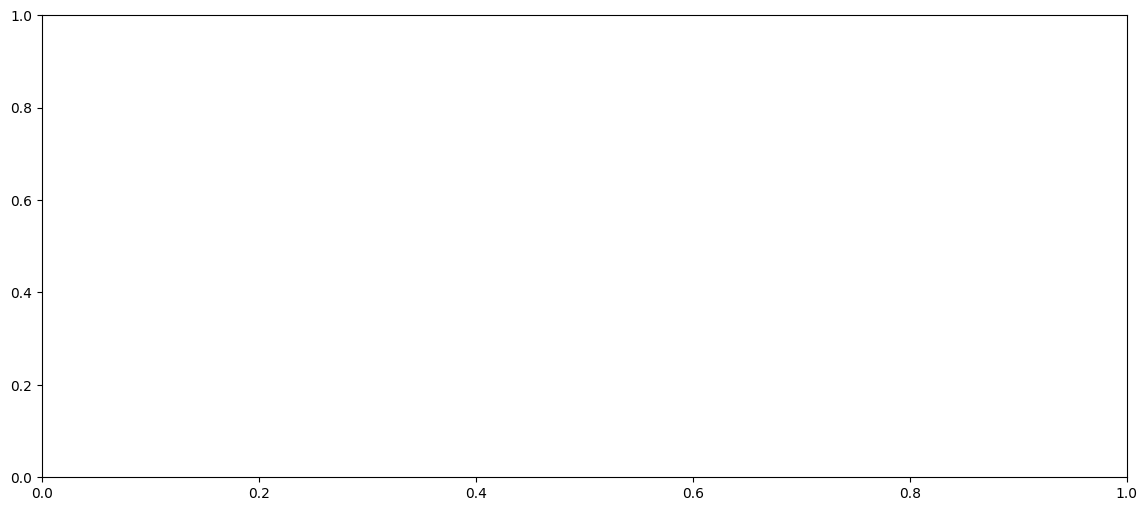

In [ ]:
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. MOTOR DE CLASSIFICAÇÃO (Likelihood)
# ==========================================
def classificar_segmento(chroma_segmento):
    """
    Analisa uma fatia de áudio (vetor de 12 notas) e decide qual o acorde.
    """
    # Se o segmento for silêncio absoluto, retorna vazio
    if np.sum(chroma_segmento) < 0.05:
        return "Silêncio"

    # Normaliza para que o volume não afete a decisão, apenas a proporção das notas
    chroma_norm = chroma_segmento / (np.max(chroma_segmento) + 1e-6)

    notas_nomes = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B']

    melhor_score = -float('inf')
    acorde_vencedor = "N/A"

    for i, root in enumerate(notas_nomes):
        # Template MAIOR (Raiz + 4 + 7 semitons)
        # Ex: Dó Maior = C, E, G
        mask_maj = np.zeros(12)
        mask_maj[[i, (i+4)%12, (i+7)%12]] = 1.0

        # Template MENOR (Raiz + 3 + 7 semitons)
        # Ex: Dó Menor = C, Eb, G
        mask_min = np.zeros(12)
        mask_min[[i, (i+3)%12, (i+7)%12]] = 1.0

        # CÁLCULO DE LIKELIHOOD (Pontuação)
        # Ganha pontos se tiver as notas certas, perde pontos se tiver notas erradas

        # Teste Maior
        score_maj = np.sum(chroma_norm * mask_maj) - 0.6 * np.sum(chroma_norm * (1-mask_maj))

        # Teste Menor
        score_min = np.sum(chroma_norm * mask_min) - 0.6 * np.sum(chroma_norm * (1-mask_min))

        if score_maj > melhor_score:
            melhor_score = score_maj
            acorde_vencedor = root # Maior

        if score_min > melhor_score:
            melhor_score = score_min
            acorde_vencedor = f"{root}m" # Menor

    return acorde_vencedor

# ==========================================
# 2. ALGORITMO PRINCIPAL COM ONSET
# ==========================================
def analisar_com_onset(audio_path):
    print(f"Processando com Onset Detection: {audio_path.split('/')[-1]}...")

    # A. Carregar Áudio
    y, sr = librosa.load(audio_path)

    # B. Separação Harmônica/Percussiva
    # Usamos 'y_percussive' para achar ONDE mudar (ritmo)
    # Usamos 'y_harmonic' para saber QUAL nota é (harmonia)
    y_harmonic, y_percussive = librosa.effects.hpss(y, margin=3.0)

    # C. CQT (Melhor resolução que FFT para notas graves)
    chroma = librosa.feature.chroma_cqt(y=y_harmonic, sr=sr, bins_per_octave=36)

    # D. Detecção de Onsets (Ataques)
    # wait=10 -> Espera ~230ms entre detecções (evita picotar dedilhados)
    # backtrack=True -> Ajusta o corte para o início exato do som
    onset_frames = librosa.onset.onset_detect(
        y=y_percussive,
        sr=sr,
        backtrack=True,
        units='frames',
        wait=30,
        delta=0.1
    )

    # E. Correção de Bordas (Fix Frames)
    # Adiciona o frame 0 e o frame final para cobrir a música toda
    onset_frames = librosa.util.fix_frames(onset_frames, x_max=chroma.shape[1])

    # F. Sincronização (A Mágica)
    # Tira a MEDIANA do chroma entre cada ataque detectado
    chroma_sync = librosa.util.sync(chroma, onset_frames, aggregate=np.median)

    # G. Converter frames para tempo (segundos) para o gráfico e print
    tempos_limite = librosa.frames_to_time(onset_frames, sr=sr)

    # ==========================================
    # 3. GERAÇÃO DA TIMELINE
    # ==========================================
    print("\n--- RESULTADO DA TRANSCRIÇÃO ---")

    acorde_anterior = ""
    inicio_tempo = 0.0

    # Normaliza para limpar ruído de fundo antes de classificar
    chroma_sync = librosa.util.normalize(chroma_sync, axis=0)

    for i in range(chroma_sync.shape[1]):
        coluna_atual = chroma_sync[:, i]
        acorde_detectado = classificar_segmento(coluna_atual)

        tempo_fim = tempos_limite[i+1]

        # Lógica de exibição: Junta segmentos iguais consecutivos
        # Se o onset detectou dois ataques seguidos do mesmo acorde (ex: batida dupla)
        # o código abaixo apenas estende o tempo, não imprime repetido.
        if acorde_detectado != acorde_anterior:
            if acorde_anterior != "":
                print(f"{inicio_tempo:5.2f}s -> {tempo_fim:5.2f}s : {acorde_anterior}")
                inicio_tempo = tempos_limite[i] # Novo marco zero

            acorde_anterior = acorde_detectado

    # Imprime o último acorde
    print(f"{inicio_tempo:5.2f}s -> {tempos_limite[-1]:5.2f}s : {acorde_anterior}")

    # ==========================================
    # 4. VISUALIZAÇÃO
    # ==========================================
    plt.figure(figsize=(14, 6))

    # Plota o Chroma Sincronizado
    librosa.display.specshow(chroma_sync,
                             x_axis='time',
                             y_axis='chroma',
                             x_coords=tempos_limite,
                             cmap='coolwarm')

    plt.title("Segmentação por Onset (Ataque) + Classificação Likelihood")
    plt.colorbar(label='Energia')
    plt.xlabel("Tempo (s)")
    plt.tight_layout()
    plt.show()

# ==========================================
# AREA DE TESTE
# ==========================================
if __name__ == "__main__":
    # Coloque aqui o caminho do seu arquivo
    arquivo_teste = '/content/drive/MyDrive/MusicaFFT/TrocaDeAcordes(C-G-F).mp3'

    analisar_com_onset(arquivo_teste)

Processando com Onset Detection: Tempo_Perdido.mp3...

--- RESULTADO DA TRANSCRIÇÃO ---
 0.00s ->  9.26s : C
 9.26s -> 12.77s : Am
12.77s -> 16.23s : Bm
16.23s -> 19.60s : Em
19.60s -> 23.01s : C
23.01s -> 26.40s : Am
26.40s -> 27.49s : Bm
27.49s -> 28.63s : Em
28.63s -> 29.72s : Bm
29.72s -> 33.11s : Em
33.11s -> 36.52s : C
36.52s -> 39.80s : Am
39.80s -> 43.12s : Bm
43.12s -> 44.16s : G
44.16s -> 46.67s : Em


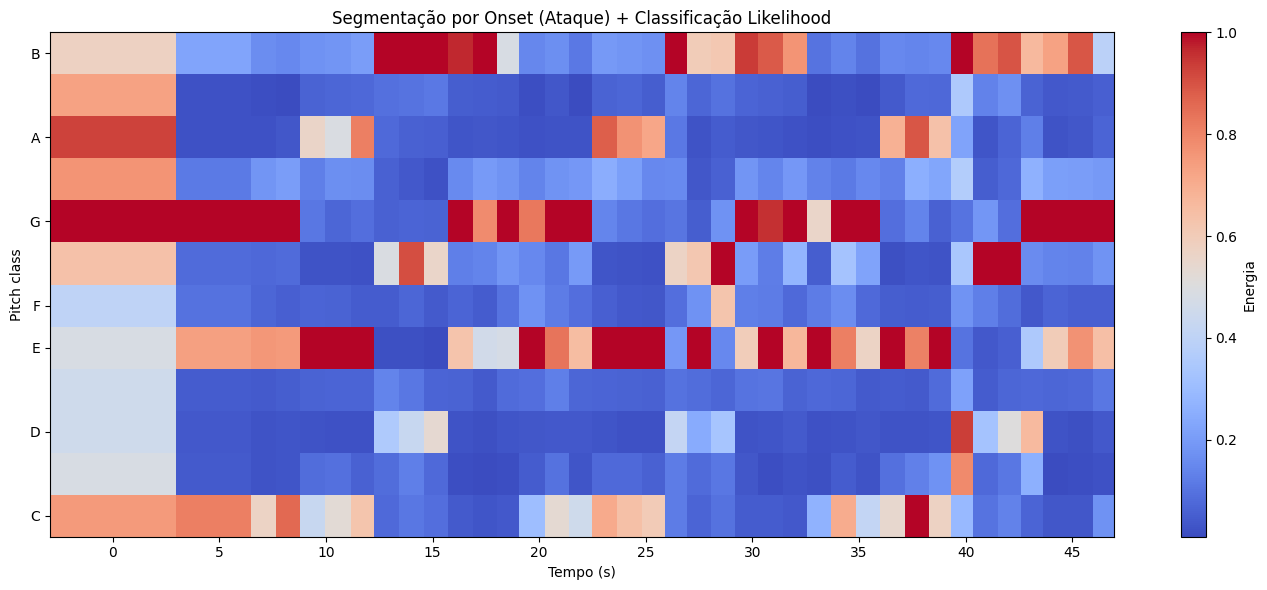

In [ ]:
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal
import scipy.ndimage

# ==========================================
# 1. MOTOR DE CLASSIFICAÇÃO (Likelihood)
# ==========================================
def classificar_segmento(chroma_segmento):
    """
    Analisa uma fatia de áudio (vetor de 12 notas) e decide qual o acorde.
    """
    # Se o segmento for silêncio absoluto, retorna vazio
    if np.sum(chroma_segmento) < 0.05:
        return "Silêncio"

    # Normaliza para que o volume não afete a decisão, apenas a proporção das notas
    chroma_norm = chroma_segmento / (np.max(chroma_segmento) + 1e-6)

    notas_nomes = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B']

    melhor_score = -float('inf')
    acorde_vencedor = "N/A"

    for i, root in enumerate(notas_nomes):
        # Template MAIOR (Raiz + 4 + 7 semitons)
        # Ex: Dó Maior = C, E, G
        mask_maj = np.zeros(12)
        mask_maj[[i, (i+4)%12, (i+7)%12]] = 1.0

        # Template MENOR (Raiz + 3 + 7 semitons)
        # Ex: Dó Menor = C, Eb, G
        mask_min = np.zeros(12)
        mask_min[[i, (i+3)%12, (i+7)%12]] = 1.0

        # Template Diminuto (Raiz + 3 + 7 semitons)
        # Ex: Dó Menor = C, Eb, G
        mask_min = np.zeros(12)
        mask_min[[i, (i+3)%12, (i+7)%12]] = 1.0

        # CÁLCULO DE LIKELIHOOD (Pontuação)
        # Ganha pontos se tiver as notas certas, perde pontos se tiver notas erradas

        # Teste Maior
        score_maj = np.sum(chroma_norm * mask_maj) - 0.6 * np.sum(chroma_norm * (1-mask_maj))

        # Teste Menor
        score_min = np.sum(chroma_norm * mask_min) - 0.6 * np.sum(chroma_norm * (1-mask_min))

        if score_maj > melhor_score:
            melhor_score = score_maj
            acorde_vencedor = root # Maior

        if score_min > melhor_score:
            melhor_score = score_min
            acorde_vencedor = f"{root}m" # Menor

    return acorde_vencedor

# ==========================================
# 2. ALGORITMO PRINCIPAL COM ONSET
# ==========================================
def analisar_com_onset(audio_path):
    print(f"Processando com Onset Detection: {audio_path.split('/')[-1]}...")

    # A. Carregar Áudio
    y, sr = librosa.load(audio_path)

    # B. Separação Harmônica/Percussiva
    # Usamos 'y_percussive' para achar ONDE mudar (ritmo)
    # Usamos 'y_harmonic' para saber QUAL nota é (harmonia)
    y_harmonic, y_percussive = librosa.effects.hpss(y, margin=3.0)

    # C. CQT (Melhor resolução que FFT para notas graves)
    chroma = librosa.feature.chroma_cqt(y=y_harmonic, sr=sr, bins_per_octave=36)

    # D. Detecção de Onsets (Ataques)
    # wait=10 -> Espera ~230ms entre detecções (evita picotar dedilhados)
    # backtrack=True -> Ajusta o corte para o início exato do som
    onset_frames = librosa.onset.onset_detect(
        y=y_percussive,
        sr=sr,
        backtrack=True,
        units='frames',
        wait=30,
        delta=0.1
    )

    # E. Correção de Bordas (Fix Frames)
    # Adiciona o frame 0 e o frame final para cobrir a música toda
    onset_frames = librosa.util.fix_frames(onset_frames, x_max=chroma.shape[1])

    # F. Sincronização (A Mágica)
    # Tira a MEDIANA do chroma entre cada ataque detectado
    # Note: If onset_frames has K elements, chroma_sync will have K-1 columns.
    chroma_sync = librosa.util.sync(chroma, onset_frames, aggregate=np.median)

    # G. Converter frames para tempo (segundos) para o gráfico e print
    # Note: tempos_limite will have K elements (from onset_frames)
    tempos_limite = librosa.frames_to_time(onset_frames, sr=sr)

    # ==========================================
    # 3. GERAÇÃO DA TIMELINE
    # ==========================================
    print("\n--- RESULTADO DA TRANSCRIÇÃO ---")

    acorde_anterior = ""
    # The first segment starts at tempos_limite[0]
    inicio_tempo_segmento = tempos_limite[0]

    # Normaliza para limpar ruído de fundo antes de classificar
    chroma_sync = librosa.util.normalize(chroma_sync, axis=0)

    # Loop through each synchronized segment. chroma_sync.shape[1] is N_segments
    # tempos_limite has N_segments + 1 elements, corresponding to edges.
    # The loop should go up to chroma_sync.shape[1]
    for i in range(chroma_sync.shape[1]):
        coluna_atual = chroma_sync[:, i]
        acorde_atual = classificar_segmento(coluna_atual)

        # Check for chord change
        if acorde_atual != acorde_anterior:
            # If there was a previous chord, print its duration.
            # The previous chord ended at tempos_limite[i] (which is the start of the current segment)
            if acorde_anterior != "": # Avoid printing for the very first 'empty' chord
                print(f"{inicio_tempo_segmento:5.2f}s -> {tempos_limite[i]:5.2f}s : {acorde_anterior}")

            # Start tracking the new chord. It begins at tempos_limite[i]
            acorde_anterior = acorde_atual
            inicio_tempo_segmento = tempos_limite[i]

    # Print the very last chord segment. It ends at tempos_limite[-1]
    print(f"{inicio_tempo_segmento:5.2f}s -> {tempos_limite[-1]:5.2f}s : {acorde_anterior}")

    # ==========================================
    # 4. VISUALIZAÇÃO
    # ==========================================
    plt.figure(figsize=(14, 6))

    # Plota o Chroma Sincronizado
    # We use tempos_limite[:-1] because chroma_sync has N columns,
    # and tempos_limite (from onset_frames) has N+1 elements.
    # For shading='nearest', x_coords should have N elements.
    librosa.display.specshow(chroma_sync,
                             x_axis='time',
                             y_axis='chroma',
                             x_coords=tempos_limite[:-1], # <-- FIX: Use tempos_limite without the last element
                             cmap='coolwarm',
                             shading='nearest')

    plt.title("Segmentação por Onset (Ataque) + Classificação Likelihood")
    plt.colorbar(label='Energia')
    plt.xlabel("Tempo (s)")
    plt.tight_layout()
    plt.show()

# ==========================================
# AREA DE TESTE
# ==========================================
if __name__ == "__main__":
    # Coloque aqui o caminho do seu arquivo
    arquivo_teste = '/content/drive/MyDrive/MusicaFFT/TrocaDeAcordes(C-G-F).mp3'

    analisar_com_onset(TempoPerdido)

Processando (Harmonic Clustering): TrocaDeAcordes(C-G-A-F).mp3...
Duração: 21.1s | Segmentos estimados (k): 8

--- TRANSCRIÇÃO HARMÔNICA ---
 0.00s ->  5.48s : C
 5.48s ->  6.18s : Gm
 6.18s -> 10.84s : G
10.84s -> 15.05s : A


TypeError: Dimensions of C (12, 7) should be one smaller than X(8) and Y(12) while using shading='flat' see help(pcolormesh)

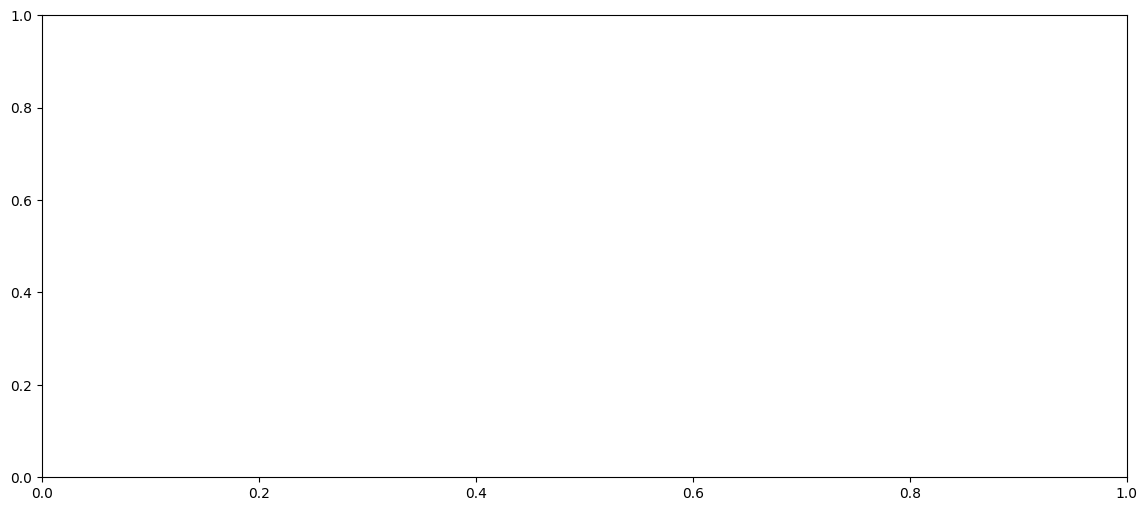

In [ ]:
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. MOTOR DE CLASSIFICAÇÃO (O mesmo de antes)
# ==========================================
def classificar_segmento(chroma_segmento):
    if np.sum(chroma_segmento) < 0.05: return "Silêncio"
    chroma_norm = chroma_segmento / (np.max(chroma_segmento) + 1e-6)

    notas = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B']
    melhor_score = -float('inf')
    acorde_vencedor = "N/A"

    for i, root in enumerate(notas):
        # Templates
        mask_maj = np.zeros(12); mask_maj[[i, (i+4)%12, (i+7)%12]] = 1.0
        mask_min = np.zeros(12); mask_min[[i, (i+3)%12, (i+7)%12]] = 1.0

        # Likelihood
        score_maj = np.sum(chroma_norm * mask_maj) - 0.6 * np.sum(chroma_norm * (1-mask_maj))
        score_min = np.sum(chroma_norm * mask_min) - 0.6 * np.sum(chroma_norm * (1-mask_min))

        if score_maj > melhor_score: melhor_score = score_maj; acorde_vencedor = root
        if score_min > melhor_score: melhor_score = score_min; acorde_vencedor = f"{root}m"

    return acorde_vencedor

# ==========================================
# 2. ALGORITMO AGLOMERATIVO
# ==========================================
def analisar_agglomerative(audio_path):
    print(f"Processando (Harmonic Clustering): {audio_path.split('/')[-1]}...")

    # A. Carregar e Separar
    y, sr = librosa.load(audio_path)
    y_harmonic, _ = librosa.effects.hpss(y, margin=3.0) # Usa só a harmonia

    # B. CQT e Suavização
    # Note: bins_per_octave=36 melhora a resolução para diferenciar acordes
    chroma = librosa.feature.chroma_cqt(y=y_harmonic, sr=sr, bins_per_octave=36)

    # TRUQUE DE MESTRE: Stack Memory
    # Isso empilha o frame atual com os vizinhos.
    # Ajuda o cluster a ver "contexto" e não mudar de ideia por causa de um ruído rápido.
    chroma_stack = librosa.feature.stack_memory(chroma, n_steps=3)

    # C. Definir o número de segmentos (k)
    # O algoritmo precisa saber quantos pedaços queremos.
    # Vamos estimar que, em média, um acorde muda a cada 1.5 ou 2 segundos.
    duracao_segundos = librosa.get_duration(y=y, sr=sr)
    k_estimado = int(duracao_segundos / 2.5)#1.5
    k_estimado = max(2, k_estimado) # Pelo menos 2 segmentos
    print(f"Duração: {duracao_segundos:.1f}s | Segmentos estimados (k): {k_estimado}")

    # D. Segmentação Aglomerativa
    # O algoritmo "cresce" os segmentos juntando frames vizinhos parecidos
    limites_frames = librosa.segment.agglomerative(chroma_stack, k_estimado)

    # Converter frames das bordas para tempo
    limites_tempos = librosa.frames_to_time(limites_frames, sr=sr)

    # E. Classificação Média por Segmento
    print("\n--- TRANSCRIÇÃO HARMÔNICA ---")
    acorde_anterior = ""
    inicio_tempo = 0.0

    # Preparar visualização
    chroma_sync = np.zeros((12, len(limites_frames)-1))

    # Iterar entre os intervalos descobertos
    # limites_frames nos dá as bordas [0, 50, 120, 200...]
    for i in range(len(limites_frames) - 1):
        start_f = limites_frames[i]
        end_f = limites_frames[i+1]

        # Pega a média do chroma APENAS dentro desse bloco harmônico
        segmento = np.mean(chroma[:, start_f:end_f], axis=1)

        # Classifica
        acorde = classificar_segmento(segmento)

        # Guarda para o plot
        chroma_sync[:, i] = segmento

        # Print inteligente (mescla repetidos)
        if acorde != acorde_anterior:
            tempo_fim = limites_tempos[i] # Fim do anterior
            if acorde_anterior != "":
                print(f"{inicio_tempo:5.2f}s -> {tempo_fim:5.2f}s : {acorde_anterior}")
                inicio_tempo = tempo_fim
            acorde_anterior = acorde

    # Último acorde
    print(f"{inicio_tempo:5.2f}s -> {limites_tempos[-1]:5.2f}s : {acorde_anterior}")

    # ==========================================
    # 3. VISUALIZAÇÃO
    # ==========================================
    plt.figure(figsize=(14, 6))

    # O specshow vai desenhar os blocos baseados nos limites que o agglomerative achou
    librosa.display.specshow(librosa.amplitude_to_db(chroma_sync, ref=np.max),
                             x_axis='time',
                             y_axis='chroma',
                             x_coords=limites_tempos,
                             cmap='coolwarm')

    plt.title(f"Segmentação Aglomerativa (Clustering por Textura Harmônica)")
    plt.colorbar(label='dB')
    plt.tight_layout()
    plt.show()

# ==========================================
# TESTE
# ==========================================
if __name__ == "__main__":
    arquivo = '/content/drive/MyDrive/MusicaFFT/TrocaDeAcordes(C-G-A-F).mp3'
    analisar_agglomerative(arquivo)

TESTE


--- Comparando algoritmos para: TrocaDeAcordes(C-G-A-F).mp3 ---
beat_tracking [{'start': np.float64(0.0), 'end': np.float64(2.159455782312925), 'label': 'C'}, {'start': np.float64(2.159455782312925), 'end': np.float64(3.01859410430839), 'label': 'C'}, {'start': np.float64(3.01859410430839), 'end': np.float64(3.947392290249433), 'label': 'C'}, {'start': np.float64(3.947392290249433), 'end': np.float64(4.829750566893424), 'label': 'C'}, {'start': np.float64(4.829750566893424), 'end': np.float64(5.758548752834467), 'label': 'C'}, {'start': np.float64(5.758548752834467), 'end': np.float64(6.640907029478458), 'label': 'D'}, {'start': np.float64(6.640907029478458), 'end': np.float64(7.500045351473923), 'label': 'G'}, {'start': np.float64(7.500045351473923), 'end': np.float64(8.359183673469389), 'label': 'G'}, {'start': np.float64(8.359183673469389), 'end': np.float64(9.218321995464853), 'label': 'G'}, {'start': np.float64(9.218321995464853), 'end': np.float64(10.077460317460318), 'label': 'G

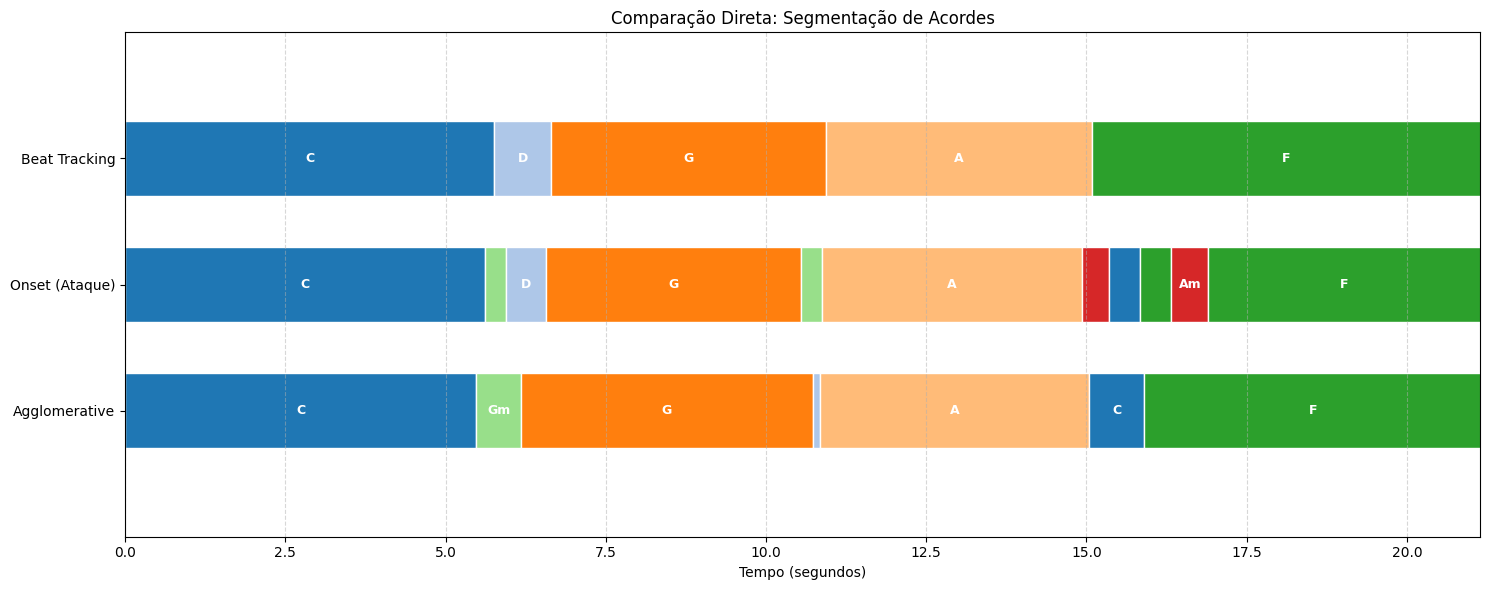

In [ ]:
import librosa
import numpy as np
import matplotlib.pyplot as plt
import time
import matplotlib.patches as mpatches

# ==========================================
# 1. MOTOR DE CLASSIFICAÇÃO (Padronizado)
# ==========================================
def classificar_segmento(chroma_segmento):
    if np.sum(chroma_segmento) < 0.05: return "Silencio"
    chroma_norm = chroma_segmento / (np.max(chroma_segmento) + 1e-6)

    notas = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B']
    melhor_score = -float('inf')
    vencedor = "N/A"

    for i, root in enumerate(notas):
        # Templates
        mask_maj = np.zeros(12); mask_maj[[i, (i+4)%12, (i+7)%12]] = 1.0
        mask_min = np.zeros(12); mask_min[[i, (i+3)%12, (i+7)%12]] = 1.0

        # Score (Likelihood simples)
        s_maj = np.sum(chroma_norm * mask_maj) - 0.5 * np.sum(chroma_norm * (1-mask_maj))
        s_min = np.sum(chroma_norm * mask_min) - 0.5 * np.sum(chroma_norm * (1-mask_min))

        if s_maj > melhor_score: melhor_score = s_maj; vencedor = root
        if s_min > melhor_score: melhor_score = s_min; vencedor = f"{root}m"

    return vencedor

# ==========================================
# 2. OS TRÊS ALGORITMOS (Retornando Dados)
# ==========================================

def run_beat_tracking(y, sr, y_harmonic, y_percussive):
    # 1. Detectar Batidas
    tempo, beats = librosa.beat.beat_track(y=y_percussive, sr=sr)

    # 2. Sincronizar Chroma
    chroma = librosa.feature.chroma_cqt(y=y_harmonic, sr=sr, bins_per_octave=36)
    beats = librosa.util.fix_frames(beats, x_max=chroma.shape[1])
    chroma_sync = librosa.util.sync(chroma, beats, aggregate=np.median)

    # 3. Gerar Lista de Segmentos
    tempos = librosa.frames_to_time(beats, sr=sr)
    segmentos = []

    for i in range(chroma_sync.shape[1]):
        acorde = classificar_segmento(chroma_sync[:, i])
        segmentos.append({'start': tempos[i], 'end': tempos[i+1], 'label': acorde})
    print("beat_tracking",segmentos)
    return segmentos, tempo

def run_onset_detection(y, sr, y_harmonic, y_percussive):
    # 1. Detectar Onsets
    onsets = librosa.onset.onset_detect(y=y_percussive, sr=sr, backtrack=True, wait=10, units='frames')

    # 2. Sincronizar
    chroma = librosa.feature.chroma_cqt(y=y_harmonic, sr=sr, bins_per_octave=36)
    onsets = librosa.util.fix_frames(onsets, x_max=chroma.shape[1])
    chroma_sync = librosa.util.sync(chroma, onsets, aggregate=np.median)

    # 3. Gerar Lista
    tempos = librosa.frames_to_time(onsets, sr=sr)
    segmentos = []

    for i in range(chroma_sync.shape[1]):
        acorde = classificar_segmento(chroma_sync[:, i])
        segmentos.append({'start': tempos[i], 'end': tempos[i+1], 'label': acorde})
    print("onset_detection",segmentos)
    return segmentos

def run_agglomerative(y, sr, y_harmonic):
    # 1. Configurar Cluster
    chroma = librosa.feature.chroma_cqt(y=y_harmonic, sr=sr, bins_per_octave=36)
    chroma_stack = librosa.feature.stack_memory(chroma, n_steps=3)

    # Estimar K (1 acorde a cada 1.5s)
    duracao = librosa.get_duration(y=y, sr=sr)
    k = max(2, int(duracao / 1.5))

    # 2. Segmentar
    bounds = librosa.segment.agglomerative(chroma_stack, k)
    bounds = librosa.util.fix_frames(bounds, x_max=chroma.shape[1])
    tempos = librosa.frames_to_time(bounds, sr=sr)

    # 3. Gerar Lista
    segmentos = []
    for i in range(len(bounds)-1):
        # Média do chroma dentro do segmento aglomerado
        bloco = np.mean(chroma[:, bounds[i]:bounds[i+1]], axis=1)
        acorde = classificar_segmento(bloco)
        segmentos.append({'start': tempos[i], 'end': tempos[i+1], 'label': acorde})
    print("agglomerative",segmentos)
    return segmentos

# ==========================================
# 3. FUNÇÃO DE COMPARAÇÃO VISUAL
# ==========================================
def comparar_metodos(audio_path):
    print(f"--- Comparando algoritmos para: {audio_path.split('/')[-1]} ---")

    # Carregar áudio uma vez
    y, sr = librosa.load(audio_path)
    y_harmonic, y_percussive = librosa.effects.hpss(y, margin=3.0)

    resultados = {}
    times = {}

    # --- 1. Beat Tracking ---
    start = time.time()
    resultados['Beat'], _ = run_beat_tracking(y, sr, y_harmonic, y_percussive)
    times['Beat'] = time.time() - start

    # --- 2. Onset ---
    start = time.time()
    resultados['Onset'] = run_onset_detection(y, sr, y_harmonic, y_percussive)
    times['Onset'] = time.time() - start

    # --- 3. Agglomerative ---
    start = time.time()
    resultados['Agglom'] = run_agglomerative(y, sr, y_harmonic)
    times['Agglom'] = time.time() - start

    # --- VISUALIZAÇÃO GANTT ---
    fig, ax = plt.subplots(figsize=(15, 6))

    # Cores para acordes (para ficar visualmente consistente)
    cores_base = plt.cm.tab20.colors
    mapa_cores = {}

    y_positions = {'Beat': 3, 'Onset': 2, 'Agglom': 1}
    height = 0.6

    idx_cor = 0

    print(f"\n{'MÉTODO':<15} | {'TEMPO(s)':<10} | {'SEGMENTOS':<10}")
    print("-" * 40)

    for metodo, segments in resultados.items():
        # Print Stats
        print(f"{metodo:<15} | {times[metodo]:.4f}     | {len(segments)}")

        # Simplificação visual: juntar segmentos iguais consecutivos para o gráfico
        merged = []
        if segments:
            curr = segments[0].copy()
            for next_seg in segments[1:]:
                if next_seg['label'] == curr['label']:
                    curr['end'] = next_seg['end'] # Estende
                else:
                    merged.append(curr)
                    curr = next_seg.copy()
            merged.append(curr)

        # Plotar Barras
        for seg in merged:
            label = seg['label']
            if label not in mapa_cores:
                mapa_cores[label] = cores_base[idx_cor % len(cores_base)]
                idx_cor += 1

            start_t = seg['start']
            duration = seg['end'] - start_t

            rect = mpatches.Rectangle((start_t, y_positions[metodo] - height/2),
                                      duration, height,
                                      color=mapa_cores[label], ec='white')
            ax.add_patch(rect)

            # Texto do acorde no meio da barra
            if duration > 0.5: # Só escreve se couber
                ax.text(start_t + duration/2, y_positions[metodo], label,
                        ha='center', va='center', color='white', fontweight='bold', fontsize=9)

    # Ajustes do Gráfico
    ax.set_yticks([1, 2, 3])
    ax.set_yticklabels(['Agglomerative', 'Onset (Ataque)', 'Beat Tracking'])
    ax.set_ylim(0, 4)
    ax.set_xlim(0, librosa.get_duration(y=y, sr=sr))
    ax.set_xlabel("Tempo (segundos)")
    ax.set_title("Comparação Direta: Segmentação de Acordes")
    ax.grid(axis='x', linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()

# ==========================================
# TESTE
# ==========================================
if __name__ == "__main__":
    arquivo = '/content/drive/MyDrive/MusicaFFT/TrocaDeAcordes(C-G-A-F).mp3'
    comparar_metodos(arquivo)

codigo com classificar segmento v2


--- Comparando algoritmos para: Tempo_Perdido.mp3 ---
beat_tracking [{'start': np.float64(0.0), 'end': np.float64(5.9675283446712015), 'label': 'C7'}, {'start': np.float64(5.9675283446712015), 'end': np.float64(6.524807256235827), 'label': 'C'}, {'start': np.float64(6.524807256235827), 'end': np.float64(7.151746031746032), 'label': 'C'}, {'start': np.float64(7.151746031746032), 'end': np.float64(7.848344671201814), 'label': 'C'}, {'start': np.float64(7.848344671201814), 'end': np.float64(8.498503401360544), 'label': 'C'}, {'start': np.float64(8.498503401360544), 'end': np.float64(9.1718820861678), 'label': 'C'}, {'start': np.float64(9.1718820861678), 'end': np.float64(9.845260770975056), 'label': 'C'}, {'start': np.float64(9.845260770975056), 'end': np.float64(10.495419501133787), 'label': 'Am'}, {'start': np.float64(10.495419501133787), 'end': np.float64(11.145578231292516), 'label': 'Am'}, {'start': np.float64(11.145578231292516), 'end': np.float64(11.795736961451247), 'label': 'Am'}

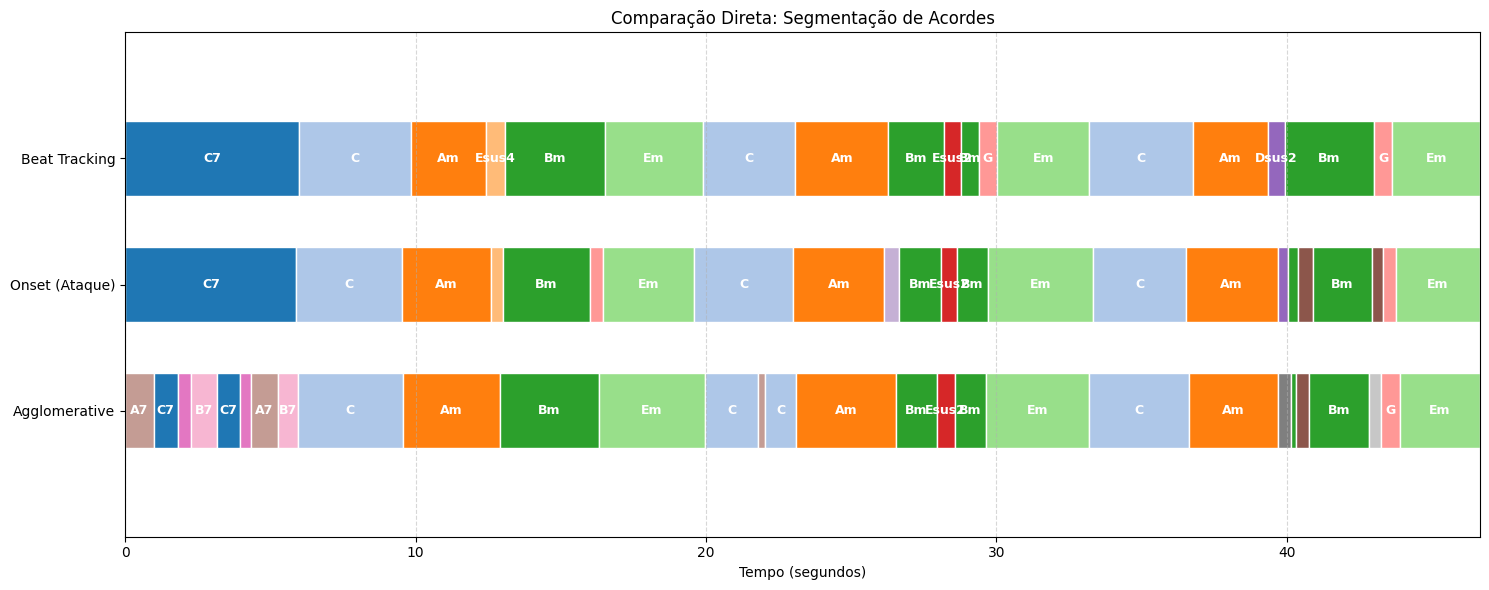

In [ ]:
import librosa
import numpy as np
import matplotlib.pyplot as plt
import time
import matplotlib.patches as mpatches

# ==========================================
# 1. MOTOR DE CLASSIFICAÇÃO (Padronizado)
# ==========================================
def classificar_segmento(chroma_segmento):
    if np.sum(chroma_segmento) < 0.05: return "Silencio"
    chroma_norm = chroma_segmento / (np.max(chroma_segmento) + 1e-6)

    notas = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B']
    melhor_score = -float('inf')
    vencedor = "N/A"

    for i, root in enumerate(notas):
        # Templates
        mask_maj = np.zeros(12); mask_maj[[i, (i+4)%12, (i+7)%12]] = 1.0
        mask_min = np.zeros(12); mask_min[[i, (i+3)%12, (i+7)%12]] = 1.0

        # Score (Likelihood simples)
        s_maj = np.sum(chroma_norm * mask_maj) - 0.5 * np.sum(chroma_norm * (1-mask_maj))
        s_min = np.sum(chroma_norm * mask_min) - 0.5 * np.sum(chroma_norm * (1-mask_min))

        if s_maj > melhor_score: melhor_score = s_maj; vencedor = root
        if s_min > melhor_score: melhor_score = s_min; vencedor = f"{root}m"

    return vencedor

# ==========================================
# 2. OS TRÊS ALGORITMOS (Retornando Dados)
# ==========================================

def run_beat_tracking(y, sr, y_harmonic, y_percussive):
    # 1. Detectar Batidas
    tempo, beats = librosa.beat.beat_track(y=y_percussive, sr=sr)

    # 2. Sincronizar Chroma
    chroma = librosa.feature.chroma_cqt(y=y_harmonic, sr=sr, bins_per_octave=36)
    beats = librosa.util.fix_frames(beats, x_max=chroma.shape[1])
    chroma_sync = librosa.util.sync(chroma, beats, aggregate=np.median)

    # 3. Gerar Lista de Segmentos
    tempos = librosa.frames_to_time(beats, sr=sr)
    segmentos = []

    for i in range(chroma_sync.shape[1]):
        acorde = classificar_segmento_v3(chroma_sync[:, i])
        segmentos.append({'start': tempos[i], 'end': tempos[i+1], 'label': acorde})
    print("beat_tracking",segmentos)
    return segmentos, tempo

def run_onset_detection(y, sr, y_harmonic, y_percussive):
    # 1. Detectar Onsets
    onsets = librosa.onset.onset_detect(y=y_percussive, sr=sr, backtrack=True, wait=10, units='frames')

    # 2. Sincronizar
    chroma = librosa.feature.chroma_cqt(y=y_harmonic, sr=sr, bins_per_octave=36)
    onsets = librosa.util.fix_frames(onsets, x_max=chroma.shape[1])
    chroma_sync = librosa.util.sync(chroma, onsets, aggregate=np.median)

    # 3. Gerar Lista
    tempos = librosa.frames_to_time(onsets, sr=sr)
    segmentos = []

    for i in range(chroma_sync.shape[1]):
        acorde = classificar_segmento_v3(chroma_sync[:, i])
        segmentos.append({'start': tempos[i], 'end': tempos[i+1], 'label': acorde})
    print("onset_detection",segmentos)
    return segmentos

def run_agglomerative(y, sr, y_harmonic):
    # 1. Configurar Cluster
    chroma = librosa.feature.chroma_cqt(y=y_harmonic, sr=sr, bins_per_octave=36)
    chroma_stack = librosa.feature.stack_memory(chroma, n_steps=3)

    # Estimar K (1 acorde a cada 1.5s)
    duracao = librosa.get_duration(y=y, sr=sr)
    k = max(2, int(duracao / 1.5))

    # 2. Segmentar
    bounds = librosa.segment.agglomerative(chroma_stack, k)
    bounds = librosa.util.fix_frames(bounds, x_max=chroma.shape[1])
    tempos = librosa.frames_to_time(bounds, sr=sr)

    # 3. Gerar Lista
    segmentos = []
    for i in range(len(bounds)-1):
        # Média do chroma dentro do segmento aglomerado
        bloco = np.mean(chroma[:, bounds[i]:bounds[i+1]], axis=1)
        acorde = classificar_segmento_v3(bloco)
        segmentos.append({'start': tempos[i], 'end': tempos[i+1], 'label': acorde})
    print("agglomerative",segmentos)
    return segmentos

# ==========================================
# 3. FUNÇÃO DE COMPARAÇÃO VISUAL
# ==========================================
def comparar_metodos(audio_path):
    print(f"--- Comparando algoritmos para: {audio_path.split('/')[-1]} ---")

    # Carregar áudio uma vez
    y, sr = librosa.load(audio_path)
    y_harmonic, y_percussive = librosa.effects.hpss(y, margin=3.0)

    resultados = {}
    times = {}

    # --- 1. Beat Tracking ---
    start = time.time()
    resultados['Beat'], _ = run_beat_tracking(y, sr, y_harmonic, y_percussive)
    times['Beat'] = time.time() - start

    # --- 2. Onset ---
    start = time.time()
    resultados['Onset'] = run_onset_detection(y, sr, y_harmonic, y_percussive)
    times['Onset'] = time.time() - start

    # --- 3. Agglomerative ---
    start = time.time()
    resultados['Agglom'] = run_agglomerative(y, sr, y_harmonic)
    times['Agglom'] = time.time() - start

    # --- VISUALIZAÇÃO GANTT ---
    fig, ax = plt.subplots(figsize=(15, 6))

    # Cores para acordes (para ficar visualmente consistente)
    cores_base = plt.cm.tab20.colors
    mapa_cores = {}

    y_positions = {'Beat': 3, 'Onset': 2, 'Agglom': 1}
    height = 0.6

    idx_cor = 0

    print(f"\n{'MÉTODO':<15} | {'TEMPO(s)':<10} | {'SEGMENTOS':<10}")
    print("-" * 40)

    for metodo, segments in resultados.items():
        # Print Stats
        print(f"{metodo:<15} | {times[metodo]:.4f}     | {len(segments)}")

        # Simplificação visual: juntar segmentos iguais consecutivos para o gráfico
        merged = []
        if segments:
            curr = segments[0].copy()
            for next_seg in segments[1:]:
                if next_seg['label'] == curr['label']:
                    curr['end'] = next_seg['end'] # Estende
                else:
                    merged.append(curr)
                    curr = next_seg.copy()
            merged.append(curr)

        # Plotar Barras
        for seg in merged:
            label = seg['label']
            if label not in mapa_cores:
                mapa_cores[label] = cores_base[idx_cor % len(cores_base)]
                idx_cor += 1

            start_t = seg['start']
            duration = seg['end'] - start_t

            rect = mpatches.Rectangle((start_t, y_positions[metodo] - height/2),
                                      duration, height,
                                      color=mapa_cores[label], ec='white')
            ax.add_patch(rect)

            # Texto do acorde no meio da barra
            if duration > 0.5: # Só escreve se couber
                ax.text(start_t + duration/2, y_positions[metodo], label,
                        ha='center', va='center', color='white', fontweight='bold', fontsize=9)

    # Ajustes do Gráfico
    ax.set_yticks([1, 2, 3])
    ax.set_yticklabels(['Agglomerative', 'Onset (Ataque)', 'Beat Tracking'])
    ax.set_ylim(0, 4)
    ax.set_xlim(0, librosa.get_duration(y=y, sr=sr))
    ax.set_xlabel("Tempo (segundos)")
    ax.set_title("Comparação Direta: Segmentação de Acordes")
    ax.grid(axis='x', linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()

# ==========================================
# TESTE
# ==========================================
if __name__ == "__main__":
    arquivo = '/content/drive/MyDrive/MusicaFFT/TrocaDeAcordes(C-G-A-F).mp3'
    comparar_metodos(TempoPerdido)
    comparar_metodos(arquivo)


euristica ADAPTATIVA, MUDAR A TABELA DE ACORDES


Mesclar


In [ ]:
def refinar_beat_tracking(segmentos_brutos):
    if not segmentos_brutos: return []

    cifra_refinada = []

    # 1. Primeira Passada: Mesclar Repetições (Merge)
    # Transforma [C, C, C, G, G] em [C, G]
    segmento_atual = segmentos_brutos[0].copy()

    for i in range(1, len(segmentos_brutos)):
        prox_seg = segmentos_brutos[i]

        # Se o acorde é igual, estende o tempo final
        if prox_seg['label'] == segmento_atual['label']:
            segmento_atual['end'] = prox_seg['end']
        else:
            # Se mudou, salva o anterior e começa um novo
            cifra_refinada.append(segmento_atual)
            segmento_atual = prox_seg.copy()

    cifra_refinada.append(segmento_atual) # Adiciona o último

    # 2. Segunda Passada: Remover "Acordes de Passagem" (Denoise)
    # Remove acordes que duram menos que 0.6 segundos (ruído de troca de dedo)
    cifra_limpa = []
    for i, seg in enumerate(cifra_refinada):
        duracao = seg['end'] - seg['start']

        # Se for muito curto e estiver "sanduichado" entre acordes válidos
        if duracao < 0.6 and len(cifra_limpa) > 0:
            # Estratégia: O acorde anterior engole esse curto
            cifra_limpa[-1]['end'] = seg['end']
            # (Não adicionamos o 'seg' atual na lista final)
        else:
            cifra_limpa.append(seg)

    return cifra_limpa

# ==========================================
# COMO TESTAR COM SEUS DADOS
# ==========================================
# Copiei seus dados do beat_tracking acima para a variável dados_beat
dados_beat =[{'start': np.float64(0.0), 'end': np.float64(5.9675283446712015), 'label': 'C'}, {'start': np.float64(5.9675283446712015), 'end': np.float64(6.524807256235827), 'label': 'C'}, {'start': np.float64(6.524807256235827), 'end': np.float64(7.151746031746032), 'label': 'C'}, {'start': np.float64(7.151746031746032), 'end': np.float64(7.848344671201814), 'label': 'C'}, {'start': np.float64(7.848344671201814), 'end': np.float64(8.498503401360544), 'label': 'C'}, {'start': np.float64(8.498503401360544), 'end': np.float64(9.1718820861678), 'label': 'C'}, {'start': np.float64(9.1718820861678), 'end': np.float64(9.845260770975056), 'label': 'C'}, {'start': np.float64(9.845260770975056), 'end': np.float64(10.495419501133787), 'label': 'Am'}, {'start': np.float64(10.495419501133787), 'end': np.float64(11.145578231292516), 'label': 'Am'}, {'start': np.float64(11.145578231292516), 'end': np.float64(11.795736961451247), 'label': 'Am'}, {'start': np.float64(11.795736961451247), 'end': np.float64(12.422675736961452), 'label': 'Am'}, {'start': np.float64(12.422675736961452), 'end': np.float64(13.072834467120181), 'label': 'Am'}, {'start': np.float64(13.072834467120181), 'end': np.float64(13.722993197278912), 'label': 'Bm'}, {'start': np.float64(13.722993197278912), 'end': np.float64(14.55891156462585), 'label': 'Bm'}, {'start': np.float64(14.55891156462585), 'end': np.float64(15.209070294784581), 'label': 'Bm'}, {'start': np.float64(15.209070294784581), 'end': np.float64(15.85922902494331), 'label': 'Bm'}, {'start': np.float64(15.85922902494331), 'end': np.float64(16.50938775510204), 'label': 'Bm'}, {'start': np.float64(16.50938775510204), 'end': np.float64(17.159546485260773), 'label': 'Em'}, {'start': np.float64(17.159546485260773), 'end': np.float64(17.832925170068027), 'label': 'Em'}, {'start': np.float64(17.832925170068027), 'end': np.float64(18.64562358276644), 'label': 'Em'}, {'start': np.float64(18.64562358276644), 'end': np.float64(19.272562358276645), 'label': 'Em'}, {'start': np.float64(19.272562358276645), 'end': np.float64(19.89950113378685), 'label': 'Em'}, {'start': np.float64(19.89950113378685), 'end': np.float64(20.526439909297054), 'label': 'C'}, {'start': np.float64(20.526439909297054), 'end': np.float64(21.153378684807254), 'label': 'C'}, {'start': np.float64(21.153378684807254), 'end': np.float64(21.78031746031746), 'label': 'C'}, {'start': np.float64(21.78031746031746), 'end': np.float64(22.430476190476192), 'label': 'C'}, {'start': np.float64(22.430476190476192), 'end': np.float64(23.08063492063492), 'label': 'C'}, {'start': np.float64(23.08063492063492), 'end': np.float64(23.73079365079365), 'label': 'Am'}, {'start': np.float64(23.73079365079365), 'end': np.float64(24.357732426303855), 'label': 'Am'}, {'start': np.float64(24.357732426303855), 'end': np.float64(25.007891156462584), 'label': 'Am'}, {'start': np.float64(25.007891156462584), 'end': np.float64(25.658049886621317), 'label': 'Am'}, {'start': np.float64(25.658049886621317), 'end': np.float64(26.284988662131518), 'label': 'Am'}, {'start': np.float64(26.284988662131518), 'end': np.float64(26.93514739229025), 'label': 'Bm'}, {'start': np.float64(26.93514739229025), 'end': np.float64(27.562086167800455), 'label': 'Bm'}, {'start': np.float64(27.562086167800455), 'end': np.float64(28.189024943310656), 'label': 'Bm'}, {'start': np.float64(28.189024943310656), 'end': np.float64(28.792743764172336), 'label': 'E'}, {'start': np.float64(28.792743764172336), 'end': np.float64(29.396462585034012), 'label': 'Bm'}, {'start': np.float64(29.396462585034012), 'end': np.float64(30.023401360544216), 'label': 'G'}, {'start': np.float64(30.023401360544216), 'end': np.float64(30.65034013605442), 'label': 'Em'}, {'start': np.float64(30.65034013605442), 'end': np.float64(31.277278911564625), 'label': 'Em'}, {'start': np.float64(31.277278911564625), 'end': np.float64(31.927437641723355), 'label': 'Em'}, {'start': np.float64(31.927437641723355), 'end': np.float64(32.57759637188209), 'label': 'Em'}, {'start': np.float64(32.57759637188209), 'end': np.float64(33.20453514739229), 'label': 'Em'}, {'start': np.float64(33.20453514739229), 'end': np.float64(33.80825396825397), 'label': 'C'}, {'start': np.float64(33.80825396825397), 'end': np.float64(34.319092970521545), 'label': 'C'}, {'start': np.float64(34.319092970521545), 'end': np.float64(34.92281179138322), 'label': 'C'}, {'start': np.float64(34.92281179138322), 'end': np.float64(35.54975056689342), 'label': 'C'}, {'start': np.float64(35.54975056689342), 'end': np.float64(36.17668934240363), 'label': 'C'}, {'start': np.float64(36.17668934240363), 'end': np.float64(36.78040816326531), 'label': 'C'}, {'start': np.float64(36.78040816326531), 'end': np.float64(37.40734693877551), 'label': 'Am'}, {'start': np.float64(37.40734693877551), 'end': np.float64(38.034285714285716), 'label': 'Am'}, {'start': np.float64(38.034285714285716), 'end': np.float64(38.70766439909297), 'label': 'Am'}, {'start': np.float64(38.70766439909297), 'end': np.float64(39.3578231292517), 'label': 'Am'}, {'start': np.float64(39.3578231292517), 'end': np.float64(39.938321995464854), 'label': 'Am'}, {'start': np.float64(39.938321995464854), 'end': np.float64(40.542040816326534), 'label': 'Bm'}, {'start': np.float64(40.542040816326534), 'end': np.float64(41.145759637188206), 'label': 'Bm'}, {'start': np.float64(41.145759637188206), 'end': np.float64(41.749478458049886), 'label': 'Bm'}, {'start': np.float64(41.749478458049886), 'end': np.float64(42.37641723356009), 'label': 'Bm'}, {'start': np.float64(42.37641723356009), 'end': np.float64(43.003356009070295), 'label': 'Bm'}, {'start': np.float64(43.003356009070295), 'end': np.float64(43.6302947845805), 'label': 'G'}, {'start': np.float64(43.6302947845805), 'end': np.float64(44.257233560090704), 'label': 'Em'}, {'start': np.float64(44.257233560090704), 'end': np.float64(44.860952380952384), 'label': 'Em'}, {'start': np.float64(44.860952380952384), 'end': np.float64(45.48789115646259), 'label': 'Em'}, {'start': np.float64(45.48789115646259), 'end': np.float64(46.09160997732426), 'label': 'Em'}, {'start': np.float64(46.09160997732426), 'end': np.float64(46.672108843537416), 'label': 'Em'}]


# Para testar, você pode passar a lista 'resultados['Beat']' direto da função anterior
nova_cifra = refinar_beat_tracking(dados_beat)

print("--- CIFRA FINAL LIMPA ---")
for seg in nova_cifra:
    print(f"{seg['start']:05.2f}s -> {seg['end']:05.2f}s : {seg['label']}")

--- CIFRA FINAL LIMPA ---
00.00s -> 09.85s : C
09.85s -> 13.07s : Am
13.07s -> 16.51s : Bm
16.51s -> 19.90s : Em
19.90s -> 23.08s : C
23.08s -> 26.28s : Am
26.28s -> 28.19s : Bm
28.19s -> 28.79s : E
28.79s -> 29.40s : Bm
29.40s -> 30.02s : G
30.02s -> 33.20s : Em
33.20s -> 36.78s : C
36.78s -> 39.94s : Am
39.94s -> 43.00s : Bm
43.00s -> 43.63s : G
43.63s -> 46.67s : Em


calsssificar 2


In [ ]:
import numpy as np

def classificar_segmento_v2(chroma_segmento):
    # 1. Gate de Silêncio
    # Se a soma da energia for muito baixa, ignora (evita ruído aleatório)
    if np.sum(chroma_segmento) < 0.1:
        return "" # Retorna vazio para não sujar a cifra

    # 2. Normalização (L1 ou Max)
    # Traz os valores para uma escala de 0 a 1 para comparação justa
    chroma_norm = chroma_segmento / (np.max(chroma_segmento) + 1e-6)

    notas_nomes = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B']

    # 3. Dicionário de Formatos (Intervalos em semitons a partir da tônica)
    # Ordem importa para o desempate: Testamos os simples primeiro.
    tipos_acordes = {
        '':     [0, 4, 7],      # Maior (Tríade) - Ex: C
        'm':    [0, 3, 7],      # Menor (Tríade) - Ex: Cm
        'sus2': [0, 2, 7],      # Suspenso 2 - Ex: Csus2
        'sus4': [0, 5, 7],      # Suspenso 4 - Ex: Csus4
        '7':    [0, 4, 7, 10]   # Dominante com 7ª Menor - Ex: C7
    }

    melhor_score = -float('inf')
    acorde_vencedor = "N/A"

    # 4. Loop de Classificação
    for i, root in enumerate(notas_nomes):
        for sufixo, intervalos in tipos_acordes.items():
            # Criar Template Dinâmico
            template = np.zeros(12)
            indices = [(i + intervalo) % 12 for intervalo in intervalos]
            template[indices] = 1.0

            # --- CÁLCULO DE LIKELIHOOD ---

            # Energia A FAVOR (Notas que batem com o template)
            energia_util = np.sum(chroma_norm * template)

            # Energia CONTRA (Notas intrusas que não deviam estar lá)
            # Penalidade 0.6 é agressiva o suficiente para limpar "sujeira"
            energia_ruido = np.sum(chroma_norm * (1 - template))

            score = energia_util - (0.6 * energia_ruido)

            # BÔNUS PARA 7ª (Ajuste Fino)
            # Se for um acorde com 4 notas (como o 7), ele tem mais chance de ter ruído.
            # Damos um empurrãozinho leve se ele preencher todos os requisitos.
            if len(intervalos) == 4:
                score *= 1.05

            # Lógica de Atualização (Só troca se for ESTRITAMENTE maior)
            # Isso garante que em caso de empate (C vs C7 tocando apenas C),
            # o C (que veio antes no loop) ganha.
            if score > melhor_score:
                melhor_score = score
                acorde_vencedor = f"{root}{sufixo}"

    return acorde_vencedor

classificar 3


In [ ]:
import numpy as np

def classificar_segmento_v3(chroma_segmento):
    # 1. Gate de Silêncio e Normalização
    if np.sum(chroma_segmento) < 0.1: return ""
    chroma_norm = chroma_segmento / (np.max(chroma_segmento) + 1e-6)

    notas_nomes = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B']

    # 2. Definição de Templates com Pesos
    # 'indices': quais notas compõem o acorde
    # 'bias': empurrãozinho na pontuação (Positivo = prefere esse / Negativo = evita esse)
    # 'required_idx': índice da nota que PRECISA estar forte (ex: a 7ª no acorde C7)

    tipos_acordes = {
        '':     {'idx': [0, 4, 7],     'bias': 0.10, 'required': None}, # Maior (Bônus 10%)
        'm':    {'idx': [0, 3, 7],     'bias': 0.10, 'required': None}, # Menor (Bônus 10%)
        'sus2': {'idx': [0, 2, 7],     'bias': -0.05, 'required': 2},   # Penalidade leve
        'sus4': {'idx': [0, 5, 7],     'bias': -0.05, 'required': 5},   # Penalidade leve
        '7':    {'idx': [0, 4, 7, 10], 'bias': -0.15, 'required': 10},  # Penalidade forte
    }

    melhor_score = -float('inf')
    acorde_vencedor = "N/A"

    # 3. Loop de Classificação
    for i, root in enumerate(notas_nomes):
        for sufixo, dados in tipos_acordes.items():
            intervalos = dados['idx']
            bias = dados['bias']
            required_interval = dados['required']

            # Criar máscara do template
            indices_reais = [(i + interval) % 12 for interval in intervalos]

            # --- REGRA DE OURO: Validação da Nota Crítica ---
            # Se for um acorde complexo (ex: C7), verificamos se a nota da sétima (Bb)
            # tem energia relevante (> 0.25). Se for fraca, pulamos esse acorde.
            if required_interval is not None:
                idx_critico = (i + required_interval) % 12
                if chroma_norm[idx_critico] < 0.3: # Threshold de sensibilidade
                    continue # Aborta: é ruído, não é uma nota real

            # --- CÁLCULO DE SCORE ---
            # Soma energia das notas certas
            energia_util = np.sum(chroma_norm[indices_reais])

            # Calcula energia das notas erradas (ruído fora do template)
            mask = np.ones(12, dtype=bool)
            mask[indices_reais] = False
            energia_ruido = np.sum(chroma_norm[mask])

            # Fórmula: (Energia Útil) - (Penalidade * Ruído) + (Viés de Simplicidade)
            # Aumentei a penalidade de ruído para 0.7 para ser mais "chato"
            score = energia_util - (0.7 * energia_ruido) + bias

            if score > melhor_score:
                melhor_score = score
                acorde_vencedor = f"{root}{sufixo}"

    return acorde_vencedor

# heuristica adaptativa

In [ ]:
import numpy as np

def classificar_segmento_v4(chroma_segmento, acorde_anterior=""):
    # 1. Gate e Normalização
    if np.sum(chroma_segmento) < 0.1: return ""
    chroma_norm = chroma_segmento / (np.max(chroma_segmento) + 1e-6)

    notas_nomes = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B']

    # 2. Definição de Templates (Mantendo a rigo do V3)
    tipos_acordes = {
        '':     {'idx': [0, 4, 7],     'bias': 0.15, 'required': None}, # Aumentei o bias das tríades
        'm':    {'idx': [0, 3, 7],     'bias': 0.15, 'required': None},
       # 'sus2': {'idx': [0, 2, 7],     'bias': -0.1, 'required': 2},
       # 'sus4': {'idx': [0, 5, 7],     'bias': -0.1, 'required': 5},
       # '7':    {'idx': [0, 4, 7, 10], 'bias': -0.2, 'required': 10},   # Penalidade maior
    }

    melhor_score = -float('inf')
    acorde_vencedor = "N/A"

    for i, root in enumerate(notas_nomes):
        for sufixo, dados in tipos_acordes.items():
            nome_atual = f"{root}{sufixo}"

            # --- Lógica Padrão V3 ---
            intervalos = dados['idx']
            bias = dados['bias']
            required_interval = dados['required']

            indices_reais = [(i + interval) % 12 for interval in intervalos]

            # Validação da nota crítica (Sétimas/Suspensas)
            if required_interval is not None:
                idx_critico = (i + required_interval) % 12
                if chroma_norm[idx_critico] < 0.25: # Threshold
                    continue

            energia_util = np.sum(chroma_norm[indices_reais])
            mask = np.ones(12, dtype=bool)
            mask[indices_reais] = False
            energia_ruido = np.sum(chroma_norm[mask])

            score = energia_util - (0.6 * energia_ruido) + bias

            # ====================================================
            # A NOVA MÁGICA: INÉRCIA TEMPORAL (Context Score)
            # ====================================================
            if nome_atual == acorde_anterior:
                # Bônus massivo para manter o acorde (Estabilidade)
                score += 0.5

            # (Opcional) Penalidade extra para trocar Tríade -> Complexo sem motivo
            # Se o anterior era simples e o atual é complexo, exige mais score
            if acorde_anterior and len(acorde_anterior) < len(nome_atual):
                 score -= 0.1

            if score > melhor_score:
                melhor_score = score
                acorde_vencedor = nome_atual

    return acorde_vencedor

--- Comparando algoritmos (V4 - Stateful) para: TrocaDeAcordes(C-G-A-F).wav ---
beat_tracking [{'start': np.float64(0.0), 'end': np.float64(2.159455782312925), 'label': 'C'}, {'start': np.float64(2.159455782312925), 'end': np.float64(3.01859410430839), 'label': 'C'}, {'start': np.float64(3.01859410430839), 'end': np.float64(3.947392290249433), 'label': 'C'}, {'start': np.float64(3.947392290249433), 'end': np.float64(4.829750566893424), 'label': 'C'}, {'start': np.float64(4.829750566893424), 'end': np.float64(5.758548752834467), 'label': 'C'}, {'start': np.float64(5.758548752834467), 'end': np.float64(6.640907029478458), 'label': 'D'}, {'start': np.float64(6.640907029478458), 'end': np.float64(7.500045351473923), 'label': 'G'}, {'start': np.float64(7.500045351473923), 'end': np.float64(8.359183673469389), 'label': 'G'}, {'start': np.float64(8.359183673469389), 'end': np.float64(9.218321995464853), 'label': 'G'}, {'start': np.float64(9.218321995464853), 'end': np.float64(10.0774603174603

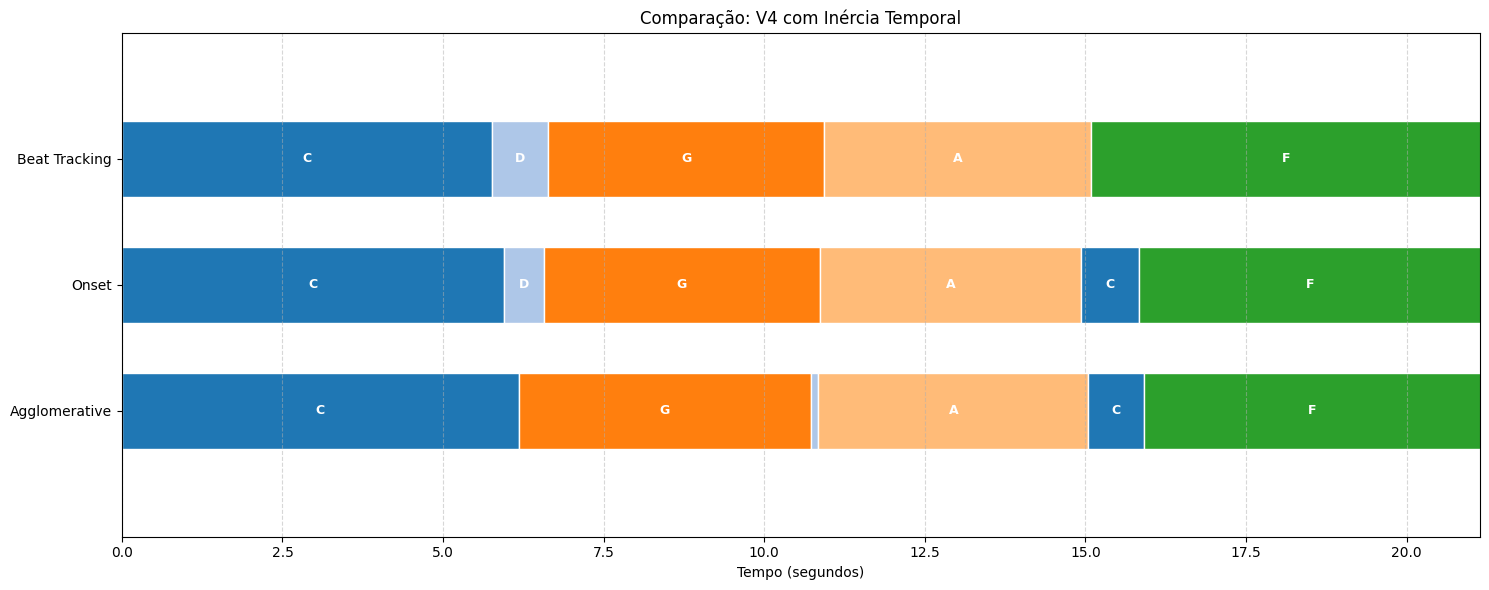

--- Comparando algoritmos (V4 - Stateful) para: Tempo_Perdido.mp3 ---
beat_tracking [{'start': np.float64(0.0), 'end': np.float64(5.9675283446712015), 'label': 'C'}, {'start': np.float64(5.9675283446712015), 'end': np.float64(6.524807256235827), 'label': 'C'}, {'start': np.float64(6.524807256235827), 'end': np.float64(7.151746031746032), 'label': 'C'}, {'start': np.float64(7.151746031746032), 'end': np.float64(7.848344671201814), 'label': 'C'}, {'start': np.float64(7.848344671201814), 'end': np.float64(8.498503401360544), 'label': 'C'}, {'start': np.float64(8.498503401360544), 'end': np.float64(9.1718820861678), 'label': 'C'}, {'start': np.float64(9.1718820861678), 'end': np.float64(9.845260770975056), 'label': 'C'}, {'start': np.float64(9.845260770975056), 'end': np.float64(10.495419501133787), 'label': 'Am'}, {'start': np.float64(10.495419501133787), 'end': np.float64(11.145578231292516), 'label': 'Am'}, {'start': np.float64(11.145578231292516), 'end': np.float64(11.795736961451247),

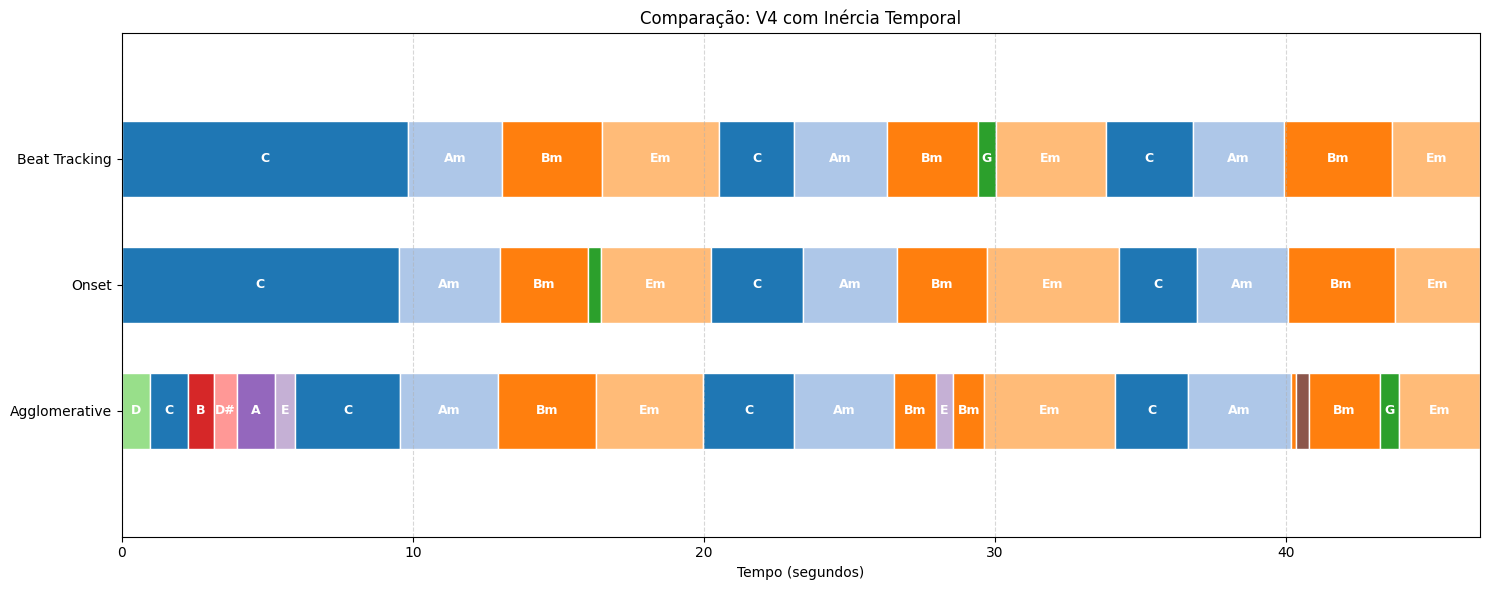

--- Comparando algoritmos (V4 - Stateful) para: Re_1.mp3 ---
beat_tracking [{'start': np.float64(0.0), 'end': np.float64(0.9287981859410431), 'label': 'D'}, {'start': np.float64(0.9287981859410431), 'end': np.float64(1.6253968253968254), 'label': 'D'}, {'start': np.float64(1.6253968253968254), 'end': np.float64(2.3219954648526078), 'label': 'D'}, {'start': np.float64(2.3219954648526078), 'end': np.float64(2.972154195011338), 'label': 'D'}, {'start': np.float64(2.972154195011338), 'end': np.float64(3.599092970521542), 'label': 'D'}, {'start': np.float64(3.599092970521542), 'end': np.float64(4.2260317460317465), 'label': 'D'}, {'start': np.float64(4.2260317460317465), 'end': np.float64(4.85297052154195), 'label': 'D'}, {'start': np.float64(4.85297052154195), 'end': np.float64(5.50312925170068), 'label': 'D'}, {'start': np.float64(5.50312925170068), 'end': np.float64(6.0836281179138325), 'label': 'D'}, {'start': np.float64(6.0836281179138325), 'end': np.float64(6.710566893424036), 'label'

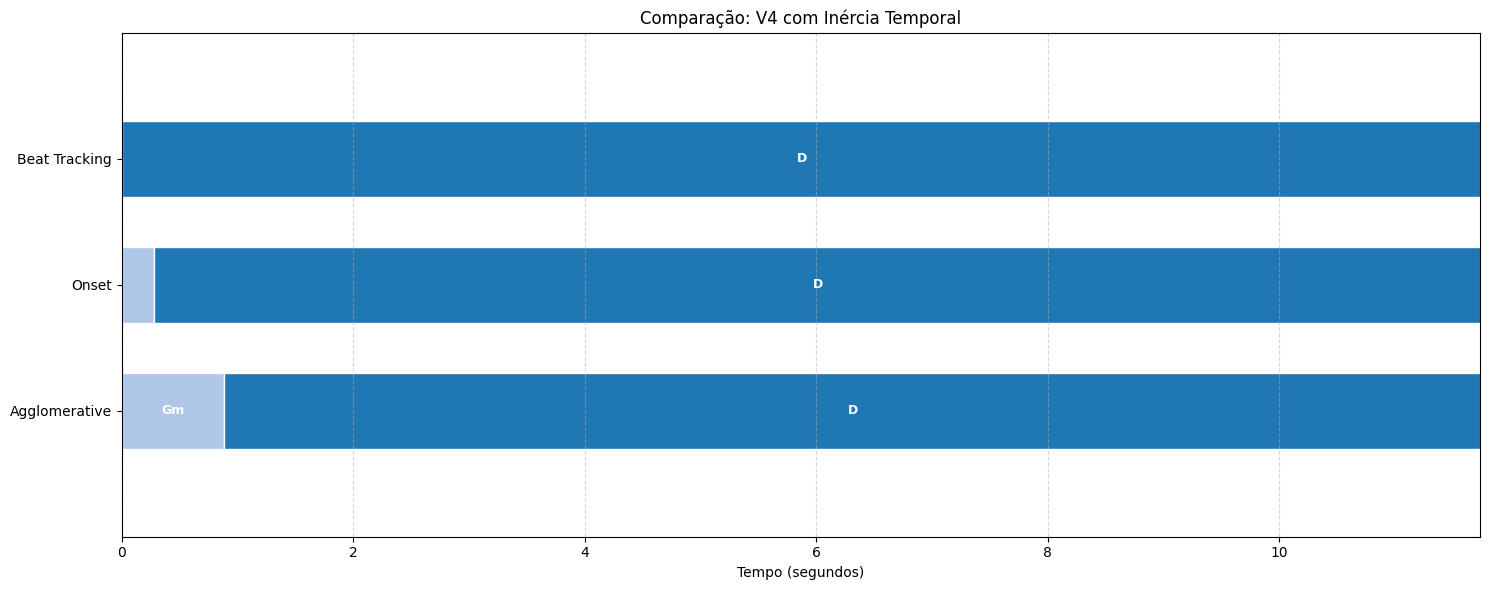

--- Comparando algoritmos (V4 - Stateful) para: La_1.mp3 ---
beat_tracking [{'start': np.float64(0.0), 'end': np.float64(1.3235374149659864), 'label': 'A'}, {'start': np.float64(1.3235374149659864), 'end': np.float64(2.089795918367347), 'label': 'A'}, {'start': np.float64(2.089795918367347), 'end': np.float64(3.0882539682539685), 'label': 'A'}, {'start': np.float64(3.0882539682539685), 'end': np.float64(4.040272108843538), 'label': 'A'}, {'start': np.float64(4.040272108843538), 'end': np.float64(4.922630385487528), 'label': 'A'}, {'start': np.float64(4.922630385487528), 'end': np.float64(5.990748299319728), 'label': 'A'}, {'start': np.float64(5.990748299319728), 'end': np.float64(7.035646258503402), 'label': 'A'}, {'start': np.float64(7.035646258503402), 'end': np.float64(7.894784580498866), 'label': 'A'}, {'start': np.float64(7.894784580498866), 'end': np.float64(8.753922902494331), 'label': 'A'}, {'start': np.float64(8.753922902494331), 'end': np.float64(9.58984126984127), 'label': '

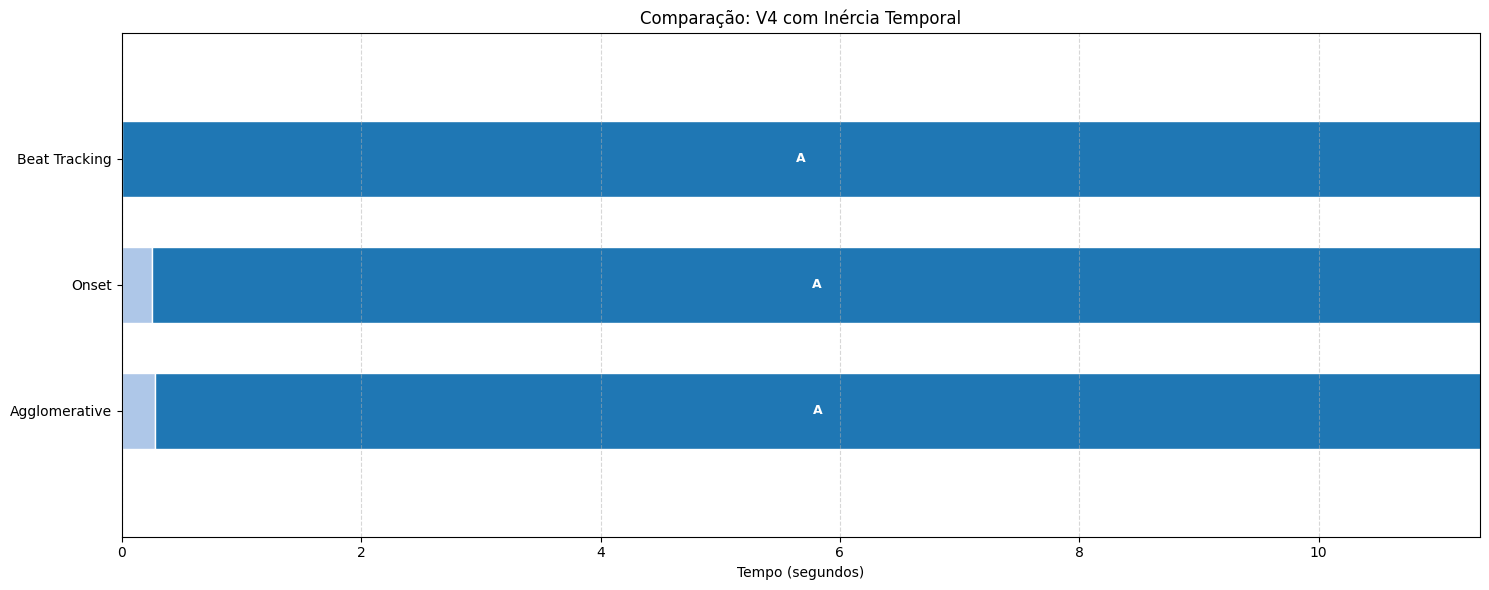

--- Comparando algoritmos (V4 - Stateful) para: La_menor_1.mp3 ---
beat_tracking [{'start': np.float64(0.0), 'end': np.float64(1.9736961451247166), 'label': 'Am'}, {'start': np.float64(1.9736961451247166), 'end': np.float64(2.716734693877551), 'label': 'Am'}, {'start': np.float64(2.716734693877551), 'end': np.float64(3.5294331065759637), 'label': 'Am'}, {'start': np.float64(3.5294331065759637), 'end': np.float64(4.295691609977324), 'label': 'Am'}, {'start': np.float64(4.295691609977324), 'end': np.float64(5.061950113378685), 'label': 'Am'}, {'start': np.float64(5.061950113378685), 'end': np.float64(5.712108843537415), 'label': 'Am'}, {'start': np.float64(5.712108843537415), 'end': np.float64(6.362267573696145), 'label': 'Am'}, {'start': np.float64(6.362267573696145), 'end': np.float64(7.151746031746032), 'label': 'Am'}, {'start': np.float64(7.151746031746032), 'end': np.float64(7.9412244897959186), 'label': 'Am'}, {'start': np.float64(7.9412244897959186), 'end': np.float64(8.7307029478

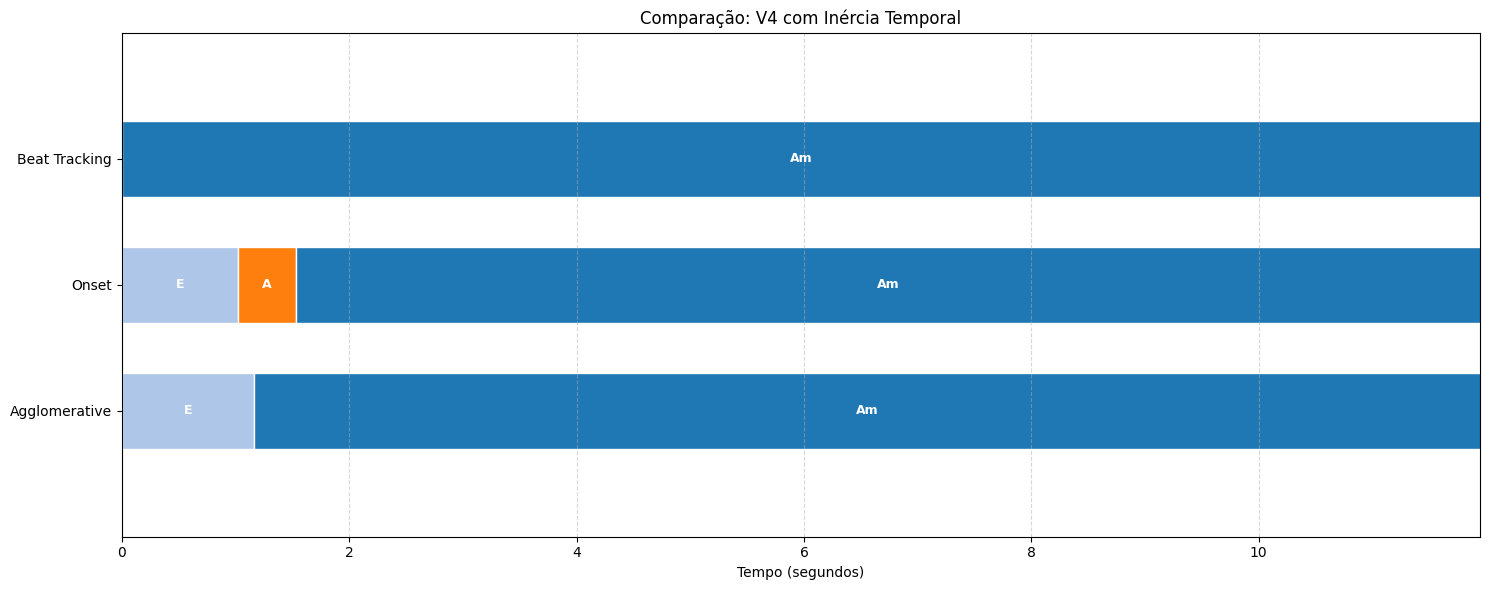

In [ ]:
# ==========================================
# 2. OS TRÊS ALGORITMOS (ADAPTADOS PARA V4)
# ==========================================
import matplotlib.patches as mpatches

def run_beat_tracking(y, sr, y_harmonic, y_percussive):
    # 1. Detectar Batidas
    tempo, beats = librosa.beat.beat_track(y=y_percussive, sr=sr)

    # 2. Sincronizar Chroma
    chroma = librosa.feature.chroma_cqt(y=y_harmonic, sr=sr, bins_per_octave=36)
    beats = librosa.util.fix_frames(beats, x_max=chroma.shape[1])
    chroma_sync = librosa.util.sync(chroma, beats, aggregate=np.median)

    # 3. Gerar Lista de Segmentos
    tempos = librosa.frames_to_time(beats, sr=sr)
    segmentos = []

    # --- MUDANÇA AQUI: Variável de Estado ---
    acorde_anterior = ""

    for i in range(chroma_sync.shape[1]):
        # Passamos o estado anterior para a função
        acorde = classificar_segmento_v4(chroma_sync[:, i], acorde_anterior)

        segmentos.append({'start': tempos[i], 'end': tempos[i+1], 'label': acorde})

        # Atualizamos o estado para a próxima iteração
        acorde_anterior = acorde

    print("beat_tracking", segmentos)
    return segmentos, tempo

def run_onset_detection(y, sr, y_harmonic, y_percussive):
    # 1. Detectar Onsets
    onsets = librosa.onset.onset_detect(y=y_percussive, sr=sr, backtrack=True, wait=10, units='frames')

    # 2. Sincronizar
    chroma = librosa.feature.chroma_cqt(y=y_harmonic, sr=sr, bins_per_octave=36)
    onsets = librosa.util.fix_frames(onsets, x_max=chroma.shape[1])
    chroma_sync = librosa.util.sync(chroma, onsets, aggregate=np.median)

    # 3. Gerar Lista
    tempos = librosa.frames_to_time(onsets, sr=sr)
    segmentos = []

    # --- MUDANÇA AQUI: Variável de Estado ---
    acorde_anterior = ""

    for i in range(chroma_sync.shape[1]):
        acorde = classificar_segmento_v4(chroma_sync[:, i], acorde_anterior)
        segmentos.append({'start': tempos[i], 'end': tempos[i+1], 'label': acorde})
        acorde_anterior = acorde # Atualiza memória

    print("onset_detection", segmentos)
    return segmentos

def run_agglomerative(y, sr, y_harmonic):
    # 1. Configurar Cluster
    chroma = librosa.feature.chroma_cqt(y=y_harmonic, sr=sr, bins_per_octave=36)
    chroma_stack = librosa.feature.stack_memory(chroma, n_steps=3)

    # Estimar K
    duracao = librosa.get_duration(y=y, sr=sr)
    k = max(2, int(duracao / 1.5))

    # 2. Segmentar
    bounds = librosa.segment.agglomerative(chroma_stack, k)
    bounds = librosa.util.fix_frames(bounds, x_max=chroma.shape[1])
    tempos = librosa.frames_to_time(bounds, sr=sr)

    # 3. Gerar Lista
    segmentos = []

    # --- MUDANÇA AQUI: Variável de Estado ---
    acorde_anterior = ""

    for i in range(len(bounds)-1):
        bloco = np.mean(chroma[:, bounds[i]:bounds[i+1]], axis=1)

        acorde = classificar_segmento_v4(bloco, acorde_anterior)

        segmentos.append({'start': tempos[i], 'end': tempos[i+1], 'label': acorde})
        acorde_anterior = acorde # Atualiza memória

    print("agglomerative", segmentos)
    return segmentos

# ==========================================
# 3. FUNÇÃO DE COMPARAÇÃO VISUAL
# ==========================================
def comparar_metodos(audio_path):
    print(f"--- Comparando algoritmos (V4 - Stateful) para: {audio_path.split('/')[-1]} ---")

    y, sr = librosa.load(audio_path)
    y_harmonic, y_percussive = librosa.effects.hpss(y, margin=3.0)

    resultados = {}
    times = {}

    # --- 1. Beat Tracking ---
    start = time.time()
    resultados['Beat'], _ = run_beat_tracking(y, sr, y_harmonic, y_percussive)
    times['Beat'] = time.time() - start

    # --- 2. Onset ---
    start = time.time()
    resultados['Onset'] = run_onset_detection(y, sr, y_harmonic, y_percussive)
    times['Onset'] = time.time() - start

    # --- 3. Agglomerative ---
    start = time.time()
    resultados['Agglom'] = run_agglomerative(y, sr, y_harmonic)
    times['Agglom'] = time.time() - start

    # --- VISUALIZAÇÃO GANTT ---
    fig, ax = plt.subplots(figsize=(15, 6))
    cores_base = plt.cm.tab20.colors
    mapa_cores = {}
    y_positions = {'Beat': 3, 'Onset': 2, 'Agglom': 1}
    height = 0.6
    idx_cor = 0

    print(f"\n{'MÉTODO':<15} | {'TEMPO(s)':<10} | {'SEGMENTOS':<10}")
    print("-" * 40)

    for metodo, segments in resultados.items():
        print(f"{metodo:<15} | {times[metodo]:.4f}     | {len(segments)}")
        merged = []
        if segments:
            curr = segments[0].copy()
            for next_seg in segments[1:]:
                if next_seg['label'] == curr['label']:
                    curr['end'] = next_seg['end']
                else:
                    merged.append(curr)
                    curr = next_seg.copy()
            merged.append(curr)

        for seg in merged:
            label = seg['label']
            if label not in mapa_cores:
                mapa_cores[label] = cores_base[idx_cor % len(cores_base)]
                idx_cor += 1

            start_t = seg['start']
            duration = seg['end'] - start_t
            rect = mpatches.Rectangle((start_t, y_positions[metodo] - height/2),
                                      duration, height,
                                      color=mapa_cores[label], ec='white')
            ax.add_patch(rect)
            if duration > 0.5:
                ax.text(start_t + duration/2, y_positions[metodo], label,
                        ha='center', va='center', color='white', fontweight='bold', fontsize=9)

    ax.set_yticks([1, 2, 3])
    ax.set_yticklabels(['Agglomerative', 'Onset', 'Beat Tracking'])
    ax.set_ylim(0, 4)
    ax.set_xlim(0, librosa.get_duration(y=y, sr=sr))
    ax.set_xlabel("Tempo (segundos)")
    ax.set_title("Comparação: V4 com Inércia Temporal")
    ax.grid(axis='x', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

# ==========================================
# TESTE
# ==========================================
if __name__ == "__main__":
    # Caminhos dos arquivos (Ajuste conforme necessário)
    TempoPerdido = '/content/drive/MyDrive/MusicaFFT/Tempo_Perdido.mp3' # Exemplo
    arquivo_troca = '/content/drive/MyDrive/MusicaFFT/TrocaDeAcordes(C-G-A-F).wav'
    do_1 = '/content/drive/MyDrive/MusicaFFT/Do_1.mp3'
    do_2 = '/content/drive/MyDrive/MusicaFFT/Do_2.mp3'
    re_1 = '/content/drive/MyDrive/MusicaFFT/Re_1.mp3'
    la_1 = '/content/drive/MyDrive/MusicaFFT/La_1.mp3'
    la_menor_1 = '/content/drive/MyDrive/MusicaFFT/La_menor_1.mp3'
    TempoPerdido = '/content/drive/MyDrive/MusicaFFT/Tempo_Perdido.mp3'



    # Executa a comparação
    comparar_metodos(arquivo_troca)
    comparar_metodos(TempoPerdido)
    comparar_metodos(re_1)
    comparar_metodos(la_1)
    comparar_metodos(la_menor_1)

In [ ]:
 !python --version

Python 3.12.12


colocar o wav

--- Comparando algoritmos (V4 - Stateful) para: Tempo_Perdido.mp3 ---
beat_tracking [{'start': np.float64(0.0), 'end': np.float64(5.9675283446712015), 'label': 'Am'}, {'start': np.float64(5.9675283446712015), 'end': np.float64(6.524807256235827), 'label': 'C'}, {'start': np.float64(6.524807256235827), 'end': np.float64(7.151746031746032), 'label': 'C'}, {'start': np.float64(7.151746031746032), 'end': np.float64(7.848344671201814), 'label': 'C'}, {'start': np.float64(7.848344671201814), 'end': np.float64(8.498503401360544), 'label': 'C'}, {'start': np.float64(8.498503401360544), 'end': np.float64(9.1718820861678), 'label': 'C'}, {'start': np.float64(9.1718820861678), 'end': np.float64(9.845260770975056), 'label': 'C'}, {'start': np.float64(9.845260770975056), 'end': np.float64(10.495419501133787), 'label': 'Am'}, {'start': np.float64(10.495419501133787), 'end': np.float64(11.145578231292516), 'label': 'Am'}, {'start': np.float64(11.145578231292516), 'end': np.float64(11.795736961451247)

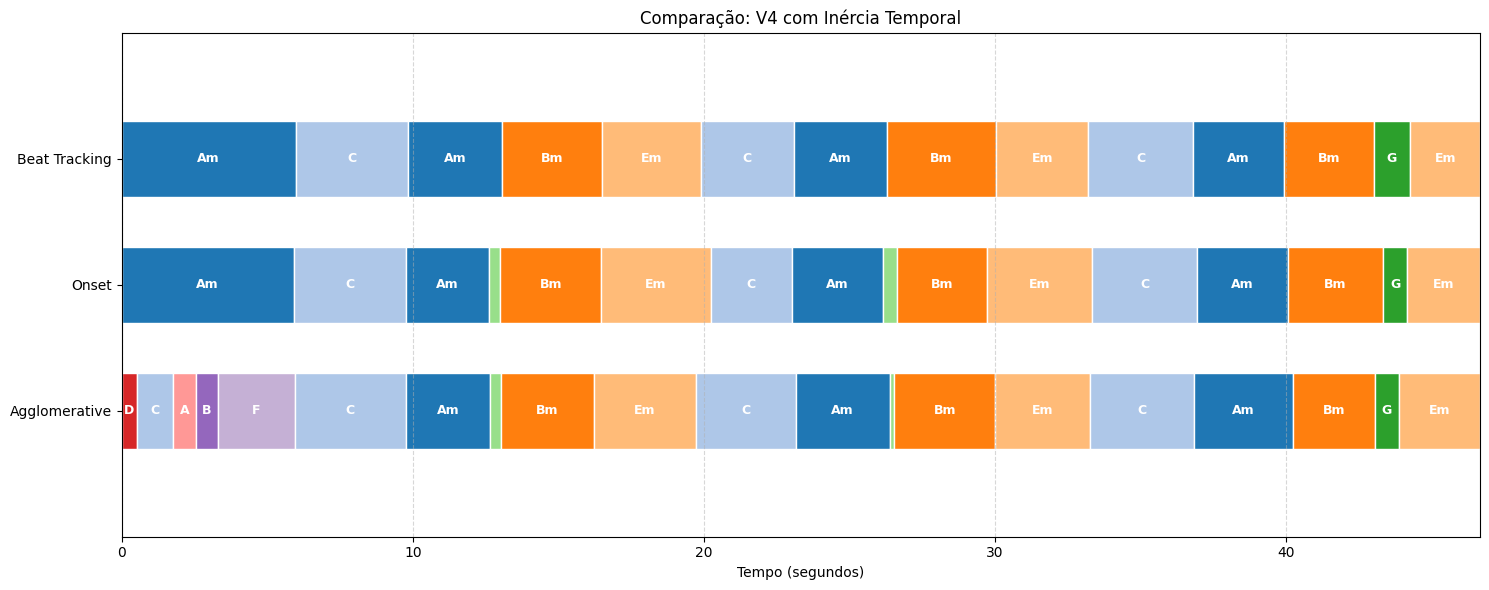

In [ ]:
import librosa
import numpy as np
import scipy.ndimage
# ==========================================
# 2. OS TRÊS ALGORITMOS (ADAPTADOS PARA V4)
# ==========================================
import matplotlib.patches as mpatches

def run_beat_tracking(y, sr, y_harmonic, y_percussive):
    # 1. Detectar Batidas
    tempo, beats = librosa.beat.beat_track(y=y_percussive, sr=sr)

    # 2. Sincronizar Chroma
    y_harmonic, y_percussive = librosa.effects.hpss(y, margin=3.0)

    # 3. Extração de Chroma CENS (Melhor para músicas completas)
    # Usamos y_harmonic em vez de y original
    chroma = librosa.feature.chroma_cens(y=y_harmonic, sr=sr)

    # 4. Suavização Temporal (Remove "ruídos" rápidos na detecção)
    # size=21 define a janela de suavização (ajuste conforme o tempo da música)
    chroma = scipy.ndimage.median_filter(chroma, size=(1, 21))

    beats = librosa.util.fix_frames(beats, x_max=chroma.shape[1])
    chroma_sync = librosa.util.sync(chroma, beats, aggregate=np.median)

    # 3. Gerar Lista de Segmentos
    tempos = librosa.frames_to_time(beats, sr=sr)
    segmentos = []

    # --- MUDANÇA AQUI: Variável de Estado ---
    acorde_anterior = ""

    for i in range(chroma_sync.shape[1]):
        # Passamos o estado anterior para a função
        acorde = classificar_segmento_v4(chroma_sync[:, i], acorde_anterior)

        segmentos.append({'start': tempos[i], 'end': tempos[i+1], 'label': acorde})

        # Atualizamos o estado para a próxima iteração
        acorde_anterior = acorde

    print("beat_tracking", segmentos)
    return segmentos, tempo

def run_onset_detection(y, sr, y_harmonic, y_percussive):
    # 1. Detectar Onsets
    onsets = librosa.onset.onset_detect(y=y_percussive, sr=sr, backtrack=True, wait=10, units='frames')

    # 2. Sincronizar
    # 3. Extração de Chroma CENS (Melhor para músicas completas)
    # Usamos y_harmonic em vez de y original
    chroma = librosa.feature.chroma_cens(y=y_harmonic, sr=sr)

    # 4. Suavização Temporal (Remove "ruídos" rápidos na detecção)
    # size=21 define a janela de suavização (ajuste conforme o tempo da música)
    chroma = scipy.ndimage.median_filter(chroma, size=(1, 21))    # 3. Extração de Chroma CENS (Melhor para músicas completas)
    # Usamos y_harmonic em vez de y original
    chroma = librosa.feature.chroma_cens(y=y_harmonic, sr=sr)

    # 4. Suavização Temporal (Remove "ruídos" rápidos na detecção)
    # size=21 define a janela de suavização (ajuste conforme o tempo da música)
    chroma = scipy.ndimage.median_filter(chroma, size=(1, 21))

    onsets = librosa.util.fix_frames(onsets, x_max=chroma.shape[1])
    chroma_sync = librosa.util.sync(chroma, onsets, aggregate=np.median)

    # 3. Gerar Lista
    tempos = librosa.frames_to_time(onsets, sr=sr)
    segmentos = []

    # --- MUDANÇA AQUI: Variável de Estado ---
    acorde_anterior = ""

    for i in range(chroma_sync.shape[1]):
        acorde = classificar_segmento_v4(chroma_sync[:, i], acorde_anterior)
        segmentos.append({'start': tempos[i], 'end': tempos[i+1], 'label': acorde})
        acorde_anterior = acorde # Atualiza memória

    print("onset_detection", segmentos)
    return segmentos

def run_agglomerative(y, sr, y_harmonic):
    # 1. Configurar Cluster
    # 3. Extração de Chroma CENS (Melhor para músicas completas)
    # Usamos y_harmonic em vez de y original
    chroma = librosa.feature.chroma_cens(y=y_harmonic, sr=sr)

    # 4. Suavização Temporal (Remove "ruídos" rápidos na detecção)
    # size=21 define a janela de suavização (ajuste conforme o tempo da música)
    chroma = scipy.ndimage.median_filter(chroma, size=(1, 21))
    chroma_stack = librosa.feature.stack_memory(chroma, n_steps=3)

    # Estimar K
    duracao = librosa.get_duration(y=y, sr=sr)
    k = max(2, int(duracao / 1.5))

    # 2. Segmentar
    bounds = librosa.segment.agglomerative(chroma_stack, k)
    bounds = librosa.util.fix_frames(bounds, x_max=chroma.shape[1])
    tempos = librosa.frames_to_time(bounds, sr=sr)

    # 3. Gerar Lista
    segmentos = []

    # --- MUDANÇA AQUI: Variável de Estado ---
    acorde_anterior = ""

    for i in range(len(bounds)-1):
        bloco = np.mean(chroma[:, bounds[i]:bounds[i+1]], axis=1)

        acorde = classificar_segmento_v4(bloco, acorde_anterior)

        segmentos.append({'start': tempos[i], 'end': tempos[i+1], 'label': acorde})
        acorde_anterior = acorde # Atualiza memória

    print("agglomerative", segmentos)
    return segmentos

# ==========================================
# 3. FUNÇÃO DE COMPARAÇÃO VISUAL
# ==========================================
def comparar_metodos(audio_path):
    print(f"--- Comparando algoritmos (V4 - Stateful) para: {audio_path.split('/')[-1]} ---")

    y, sr = librosa.load(audio_path)
    y_harmonic, y_percussive = librosa.effects.hpss(y, margin=3.0)

    resultados = {}
    times = {}

    # --- 1. Beat Tracking ---
    start = time.time()
    resultados['Beat'], _ = run_beat_tracking(y, sr, y_harmonic, y_percussive)
    times['Beat'] = time.time() - start

    # --- 2. Onset ---
    start = time.time()
    resultados['Onset'] = run_onset_detection(y, sr, y_harmonic, y_percussive)
    times['Onset'] = time.time() - start

    # --- 3. Agglomerative ---
    start = time.time()
    resultados['Agglom'] = run_agglomerative(y, sr, y_harmonic)
    times['Agglom'] = time.time() - start

    # --- VISUALIZAÇÃO GANTT ---
    fig, ax = plt.subplots(figsize=(15, 6))
    cores_base = plt.cm.tab20.colors
    mapa_cores = {}
    y_positions = {'Beat': 3, 'Onset': 2, 'Agglom': 1}
    height = 0.6
    idx_cor = 0

    print(f"\n{'MÉTODO':<15} | {'TEMPO(s)':<10} | {'SEGMENTOS':<10}")
    print("-" * 40)

    for metodo, segments in resultados.items():
        print(f"{metodo:<15} | {times[metodo]:.4f}     | {len(segments)}")
        merged = []
        if segments:
            curr = segments[0].copy()
            for next_seg in segments[1:]:
                if next_seg['label'] == curr['label']:
                    curr['end'] = next_seg['end']
                else:
                    merged.append(curr)
                    curr = next_seg.copy()
            merged.append(curr)

        for seg in merged:
            label = seg['label']
            if label not in mapa_cores:
                mapa_cores[label] = cores_base[idx_cor % len(cores_base)]
                idx_cor += 1

            start_t = seg['start']
            duration = seg['end'] - start_t
            rect = mpatches.Rectangle((start_t, y_positions[metodo] - height/2),
                                      duration, height,
                                      color=mapa_cores[label], ec='white')
            ax.add_patch(rect)
            if duration > 0.5:
                ax.text(start_t + duration/2, y_positions[metodo], label,
                        ha='center', va='center', color='white', fontweight='bold', fontsize=9)

    ax.set_yticks([1, 2, 3])
    ax.set_yticklabels(['Agglomerative', 'Onset', 'Beat Tracking'])
    ax.set_ylim(0, 4)
    ax.set_xlim(0, librosa.get_duration(y=y, sr=sr))
    ax.set_xlabel("Tempo (segundos)")
    ax.set_title("Comparação: V4 com Inércia Temporal")
    ax.grid(axis='x', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

# ==========================================
# TESTE
# ==========================================
if __name__ == "__main__":
    # Caminhos dos arquivos (Ajuste conforme necessário)
    TempoPerdido = '/content/drive/MyDrive/MusicaFFT/Tempo_Perdido.mp3' # Exemplo
    arquivo_troca = '/content/drive/MyDrive/MusicaFFT/TrocaDeAcordes(C-G-A-F).wav'
    MusicaDan = '/content/drive/MyDrive/MusicaFFT/MusicaDan.mp3'


    # Executa a comparação
    #comparar_metodos(la_menor_1)
    #comparar_metodos(MusicaDan)
    comparar_metodos(TempoPerdido)
    #comparar_metodos(arquivo_troca)
# 1. Carregamento
#y, sr = librosa.load('musica_completa.mp3', sr=22050)

# 2. Separação Harmônica-Percussiva (O "Pulo do Gato")
# margin aumenta a separação: valores mais altos isolam mais a harmonia
#y_harmonic, y_percussive = librosa.effects.hpss(y, margin=3.0)

# 3. Extração de Chroma CENS (Melhor para músicas completas)
# Usamos y_harmonic em vez de y original
#chroma = librosa.feature.chroma_cens(y=y_harmonic, sr=sr)

# 4. Suavização Temporal (Remove "ruídos" rápidos na detecção)
# size=21 define a janela de suavização (ajuste conforme o tempo da música)
#chroma = scipy.ndimage.median_filter(chroma, size=(1, 21))


# Baixo


--- Iniciando análise de: Money_PinkFloyd.mp3 ---
Separando componentes harmônicos...
Executando pYIN (isso pode levar alguns segundos)...
[✓] pYIN concluído em 2.41s
Executando CQT adaptado para tônicas...
[✓] CQT concluído em 0.07s
Gerando gráfico...


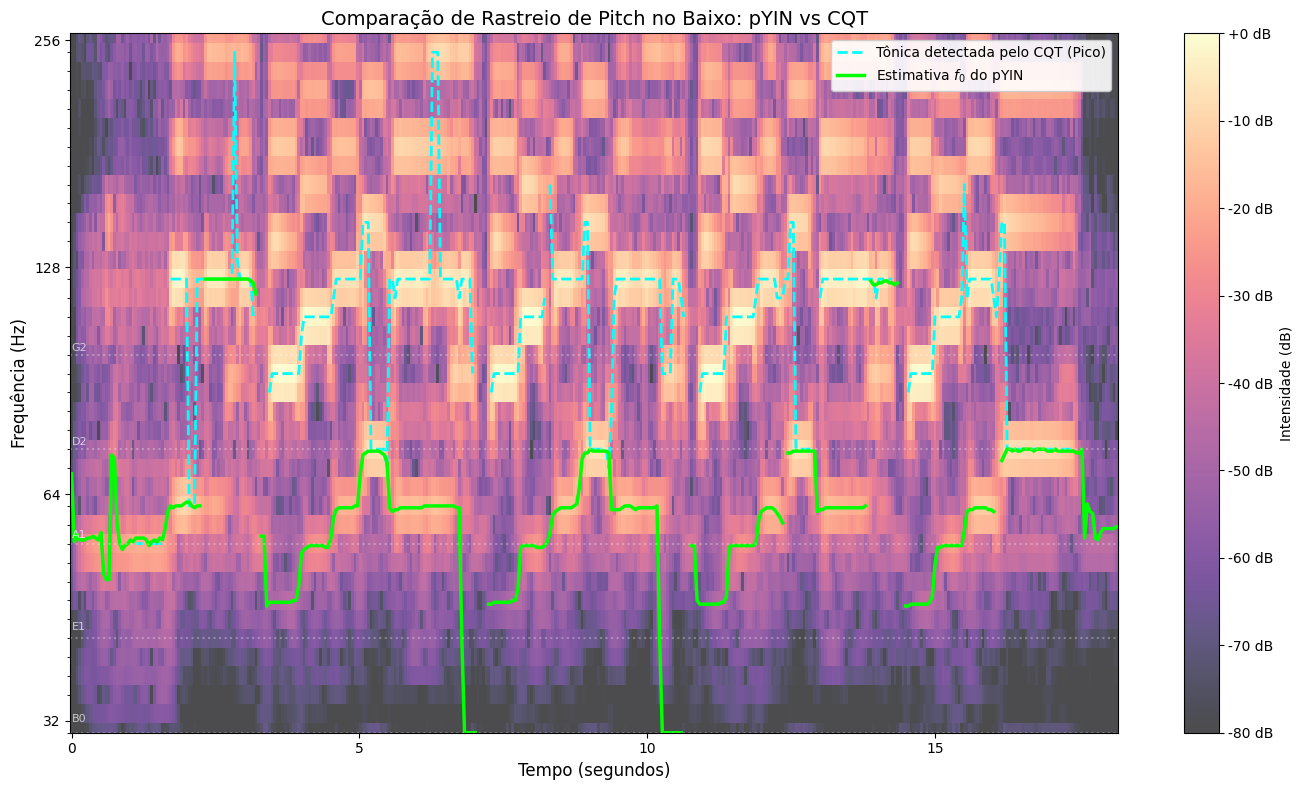


--- Iniciando análise de: Corda_La_A.mp3 ---
Separando componentes harmônicos...
Executando pYIN (isso pode levar alguns segundos)...
[✓] pYIN concluído em 1.65s
Executando CQT adaptado para tônicas...
[✓] CQT concluído em 0.07s
Gerando gráfico...


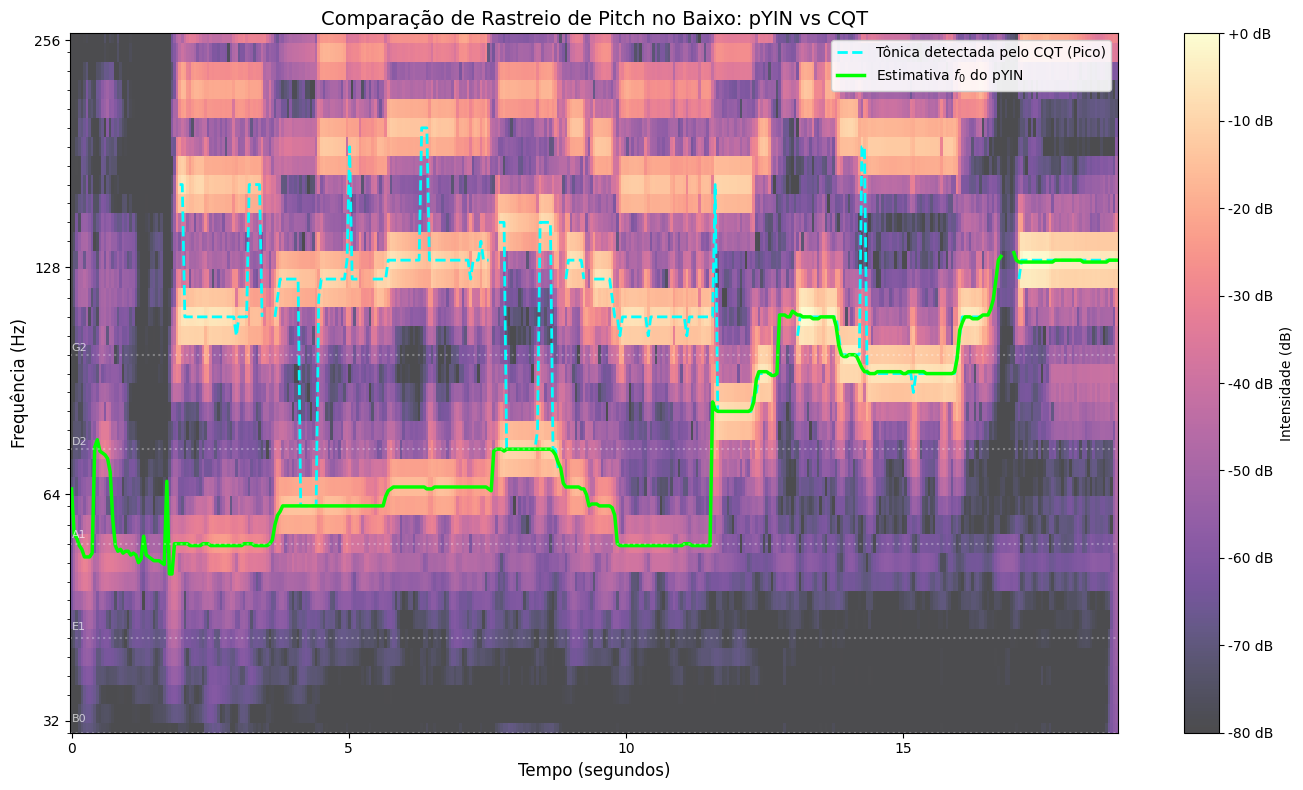


--- Iniciando análise de: Corda_Si_B.mp3 ---
Separando componentes harmônicos...
Executando pYIN (isso pode levar alguns segundos)...
[✓] pYIN concluído em 4.41s
Executando CQT adaptado para tônicas...
[✓] CQT concluído em 0.07s
Gerando gráfico...


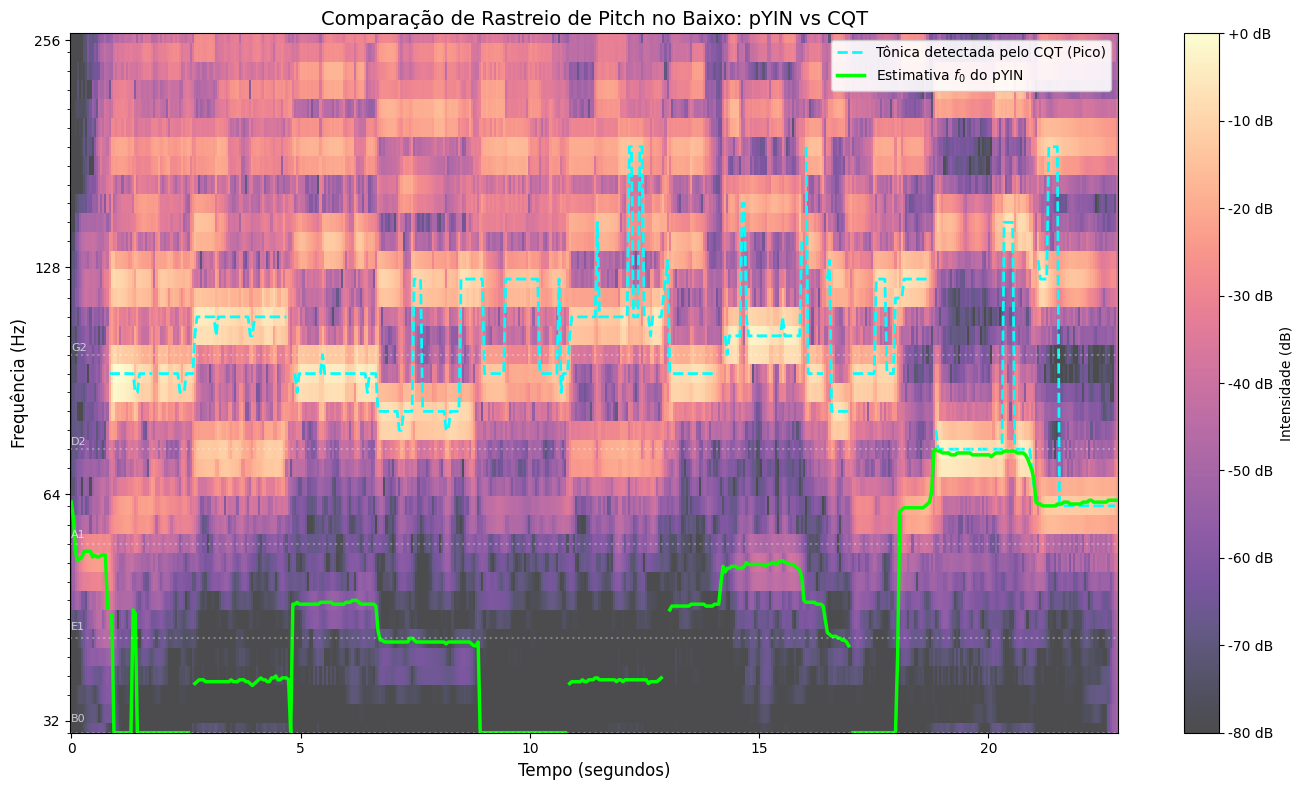


--- Iniciando análise de: Como_tudo_Deve_Ser.mp3 ---
Separando componentes harmônicos...
Executando pYIN (isso pode levar alguns segundos)...
[✓] pYIN concluído em 0.60s
Executando CQT adaptado para tônicas...
[✓] CQT concluído em 0.04s
Gerando gráfico...


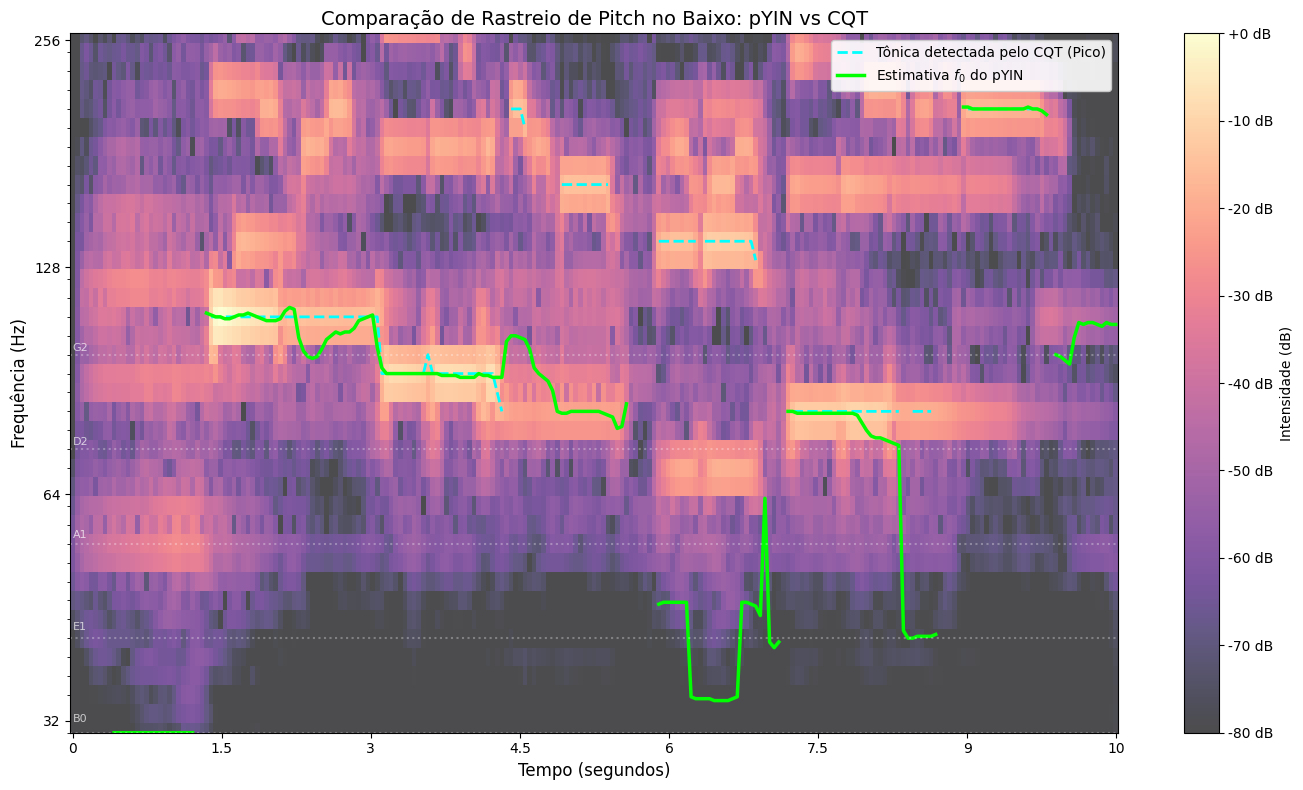

In [ ]:
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
import time

def analisar_baixo_pyin_vs_cqt(audio_path):
    print(f"\n--- Iniciando análise de: {audio_path.split('/')[-1]} ---")

    # Carrega o áudio
    y, sr = librosa.load(audio_path)

    # ==========================================
    # 1. PARÂMETROS PARA BAIXO DE 5 CORDAS
    # ==========================================
    fmin = librosa.note_to_hz('B0') # ~30.87 Hz (Si grave)
    fmax = librosa.note_to_hz('C4') # ~261.63 Hz (Sobrando para solos agudos)

    # Para frequências muito baixas (30Hz), o ciclo de onda é longo.
    # Precisamos de uma janela maior para o pYIN conseguir "ver" a onda inteira.
    frame_length = 4096
    hop_length = 1024

    # Separar harmônicos de percussivos (tira o ataque da palheta/slap da análise de nota)
    print("Separando componentes harmônicos...")
    y_harmonic, _ = librosa.effects.hpss(y, margin=2.0)

    # ==========================================
    # 2. TESTE pYIN (O Especialista em Monofonia)
    # ==========================================
    print("Executando pYIN (isso pode levar alguns segundos)...")
    start_time = time.time()

    f0_pyin, voiced_flag, voiced_probs = librosa.pyin(
        y_harmonic,
        fmin=fmin,
        fmax=fmax,
        sr=sr,
        frame_length=frame_length,
        hop_length=hop_length
    )

    print(f"[✓] pYIN concluído em {time.time() - start_time:.2f}s")

    # ==========================================
    # 3. TESTE CQT (A Abordagem de Energia)
    # ==========================================
    print("Executando CQT adaptado para tônicas...")
    start_time = time.time()

    # Vamos gerar 48 bins (4 oitavas x 12 notas), começando do B0
    n_bins = 48
    C = np.abs(librosa.cqt(y_harmonic, sr=sr, fmin=fmin, n_bins=n_bins,
                           bins_per_octave=12, hop_length=hop_length))

    # Para o CQT agir como um "detector de tônica", pegamos o bin com mais energia
    f0_cqt = np.zeros(C.shape[1])
    cqt_freqs = librosa.cqt_frequencies(n_bins, fmin=fmin, bins_per_octave=12)

    threshold_energia = 0.1 * np.max(C) # Ignora ruídos de fundo

    for i in range(C.shape[1]):
        pico_idx = np.argmax(C[:, i])
        if C[pico_idx, i] > threshold_energia:
            f0_cqt[i] = cqt_freqs[pico_idx]
        else:
            f0_cqt[i] = np.nan # Considera silêncio

    print(f"[✓] CQT concluído em {time.time() - start_time:.2f}s")

    # ==========================================
    # 4. VISUALIZAÇÃO
    # ==========================================
    print("Gerando gráfico...")
    times = librosa.times_like(f0_pyin, sr=sr, hop_length=hop_length)

    plt.figure(figsize=(14, 8))

    # Fundo: Espectrograma CQT em decibéis
    C_db = librosa.amplitude_to_db(C, ref=np.max)
    librosa.display.specshow(C_db, sr=sr, x_axis='time', y_axis='cqt_hz',
                             fmin=fmin, bins_per_octave=12, hop_length=hop_length,
                             cmap='magma', alpha=0.7)
    plt.colorbar(format='%+2.0f dB', label='Intensidade (dB)')

    # Sobrepondo as linhas
    plt.plot(times, f0_cqt, label='Tônica detectada pelo CQT (Pico)',
             color='cyan', linewidth=2, linestyle='--')
    plt.plot(times, f0_pyin, label='Estimativa $f_0$ do pYIN',
             color='lime', linewidth=2.5)

    plt.title('Comparação de Rastreio de Pitch no Baixo: pYIN vs CQT', fontsize=14)
    plt.xlabel('Tempo (segundos)', fontsize=12)
    plt.ylabel('Frequência (Hz)', fontsize=12)

    # Trava o eixo Y exatamente no range que nos importa
    plt.ylim(fmin, fmax)

    # Adiciona linhas guias para as cordas soltas (Opcional, mas ajuda visualmente)
    cordas = {'B0': 30.87, 'E1': 41.20, 'A1': 55.00, 'D2': 73.42, 'G2': 98.00}
    for nome, freq in cordas.items():
        plt.axhline(y=freq, color='white', linestyle=':', alpha=0.3)
        plt.text(0, freq + 1, nome, color='white', alpha=0.7, fontsize=8)

    plt.legend(loc='upper right', framealpha=0.9)
    plt.tight_layout()
    plt.show()

# ==========================================
# ÁREA DE EXECUÇÃO
# ==========================================
if __name__ == "__main__":
    # Coloque o caminho do seu arquivo WAV/MP3 da linha de baixo aqui
    #/content/drive/MyDrive/MusicaFFT/Corda_La_A.mp3
    #
    arquivo_teste = "/content/drive/MyDrive/MusicaFFT/Money_PinkFloyd.mp3"
    cordaLa = "/content/drive/MyDrive/MusicaFFT/Corda_La_A.mp3"
    cordaSi = "/content/drive/MyDrive/MusicaFFT/Corda_Si_B.mp3"
    comotudo = "/content/drive/MyDrive/MusicaFFT/Como_tudo_Deve_Ser.mp3"



    analisar_baixo_pyin_vs_cqt(arquivo_teste)
    analisar_baixo_pyin_vs_cqt(cordaLa)
    analisar_baixo_pyin_vs_cqt(cordaSi)
    analisar_baixo_pyin_vs_cqt(comotudo)



--- Processando: Money_PinkFloyd.mp3 ---
Separando componentes harmônicos...
Executando pYIN...
[✓] pYIN concluído em 4.34s


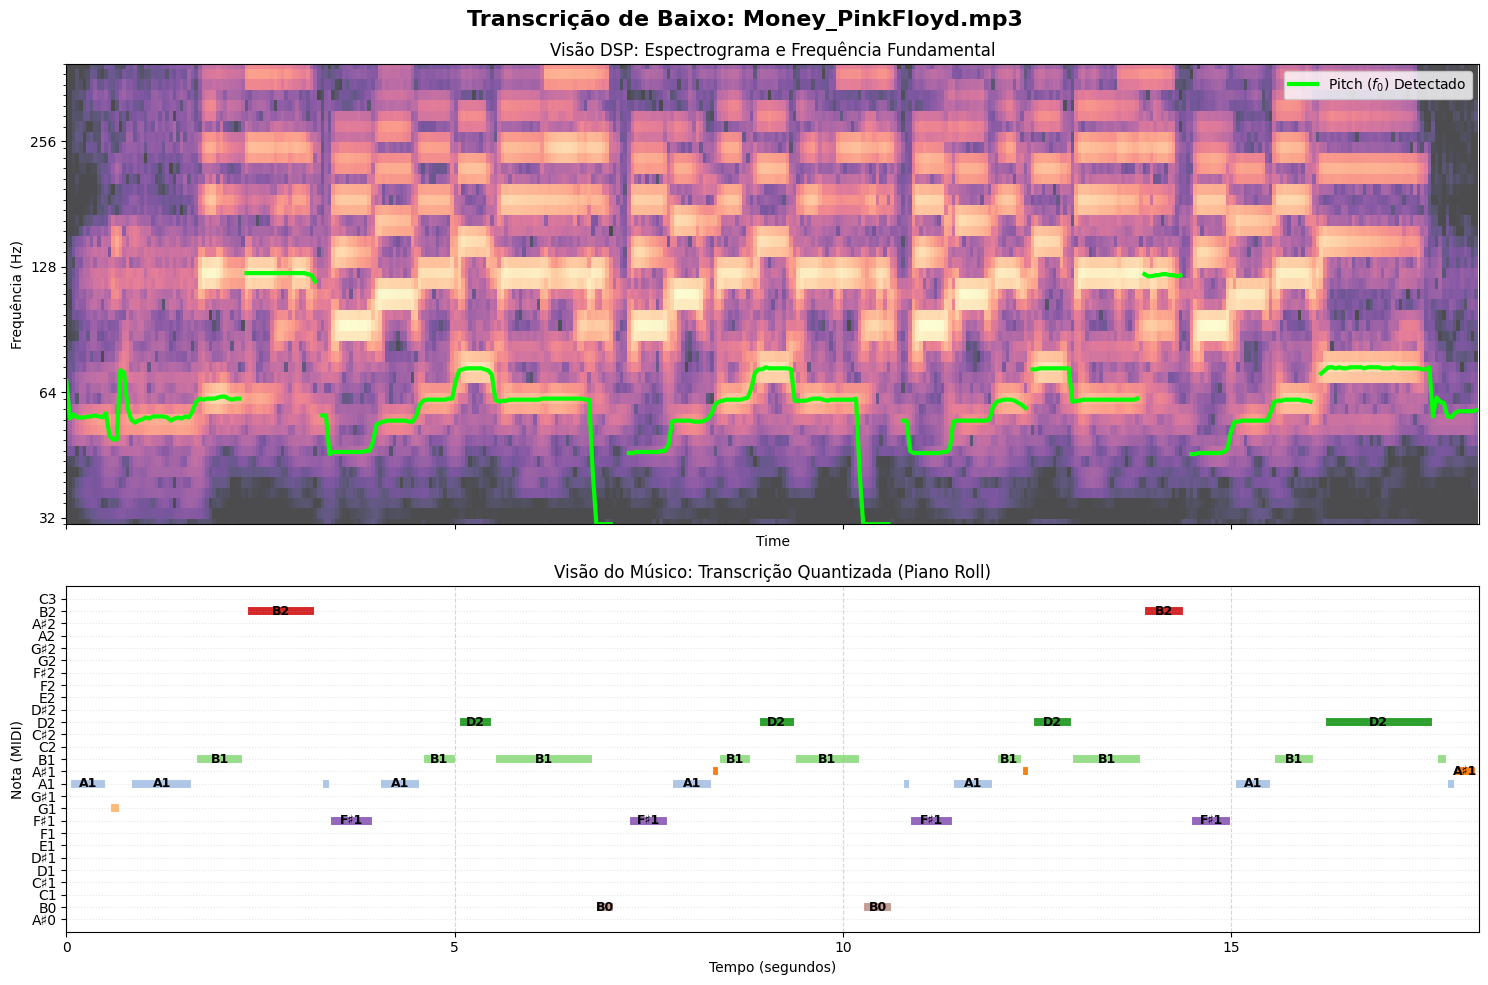

In [ ]:
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import time

def analisar_baixo_apresentacao(audio_path):
    print(f"\n--- Processando: {audio_path.split('/')[-1]} ---")

    y, sr = librosa.load(audio_path)

    # 1. PARÂMETROS ATUALIZADOS
    fmin = librosa.note_to_hz('B0') # ~30.87 Hz (Si grave)
    fmax = librosa.note_to_hz('G4') # ~392.00 Hz (Teto alto para solos/slaps)
    frame_length = 4096
    hop_length = 1024

    print("Separando componentes harmônicos...")
    y_harmonic, _ = librosa.effects.hpss(y, margin=2.0)

    # 2. EXECUÇÃO DO pYIN
    print("Executando pYIN...")
    start_time = time.time()

    f0, voiced_flag, voiced_probs = librosa.pyin(
        y_harmonic,
        fmin=fmin,
        fmax=fmax,
        sr=sr,
        frame_length=frame_length,
        hop_length=hop_length
    )

    print(f"[✓] pYIN concluído em {time.time() - start_time:.2f}s")

    # 3. LIMPEZA DOS DADOS (A Mágica do Voiced Flag)
    # Mascara (transforma em NaN) tudo o que o algoritmo considerou silêncio ou ruído não-tonal
    f0_clean = f0.copy()
    f0_clean[~voiced_flag] = np.nan

    # 4. QUANTIZAÇÃO PARA A VISÃO DO MÚSICO (Piano Roll)
    # Converte frequências para números MIDI (ex: 60 = Dó Central)
    midi_notes = librosa.hz_to_midi(f0_clean)

    # Arredonda para a nota exata mais próxima (Remove os bends/vibratos temporariamente para a visualização gráfica)
    midi_quantized = np.round(midi_notes)

    times = librosa.times_like(f0, sr=sr, hop_length=hop_length)

    # Agrupa frames consecutivos da mesma nota em "Segmentos" (Blocos estilo Gantt)
    segmentos = []
    nota_atual = None
    inicio_idx = 0

    for i, nota in enumerate(midi_quantized):
        if np.isnan(nota):
            if nota_atual is not None:
                segmentos.append({'nota_midi': nota_atual, 'inicio': times[inicio_idx], 'fim': times[i]})
                nota_atual = None
        else:
            if nota_atual is None:
                nota_atual = nota
                inicio_idx = i
            elif nota != nota_atual:
                # Se a nota mudou, salva a anterior e começa uma nova
                segmentos.append({'nota_midi': nota_atual, 'inicio': times[inicio_idx], 'fim': times[i]})
                nota_atual = nota
                inicio_idx = i

    if nota_atual is not None:
        segmentos.append({'nota_midi': nota_atual, 'inicio': times[inicio_idx], 'fim': times[-1]})

    # 5. VISUALIZAÇÃO DUPLA (Para a Aula)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10), sharex=True, gridspec_kw={'height_ratios': [2, 1.5]})
    fig.suptitle(f'Transcrição de Baixo: {audio_path.split("/")[-1]}', fontsize=16, fontweight='bold')

    # --- AX1: A Visão do Algoritmo (Espectrograma + pYIN Limpo) ---
    C = np.abs(librosa.cqt(y_harmonic, sr=sr, fmin=fmin, n_bins=60, bins_per_octave=12, hop_length=hop_length))
    C_db = librosa.amplitude_to_db(C, ref=np.max)

    librosa.display.specshow(C_db, sr=sr, x_axis='time', y_axis='cqt_hz',
                             fmin=fmin, bins_per_octave=12, hop_length=hop_length,
                             cmap='magma', alpha=0.7, ax=ax1)

    ax1.plot(times, f0_clean, label='Pitch ($f_0$) Detectado', color='lime', linewidth=3)
    ax1.set_title("Visão DSP: Espectrograma e Frequência Fundamental", fontsize=12)
    ax1.set_ylabel("Frequência (Hz)")
    ax1.set_ylim(fmin, fmax)
    ax1.legend(loc='upper right')

    # --- AX2: A Visão do Músico (Blocos Quantizados) ---
    cores = plt.cm.tab20.colors
    mapa_cores = {}
    idx_cor = 0

    notas_usadas = set()

    for seg in segmentos:
        nome_nota = librosa.midi_to_note(seg['nota_midi'])
        notas_usadas.add(seg['nota_midi'])

        if nome_nota not in mapa_cores:
            mapa_cores[nome_nota] = cores[idx_cor % len(cores)]
            idx_cor += 1

        start_t = seg['inicio']
        duration = seg['fim'] - start_t

        # Ignora ruídos ultracurtos (menores que 50ms) para não sujar o gráfico
        if duration > 0.05:
            rect = mpatches.Rectangle((start_t, seg['nota_midi'] - 0.4),
                                      duration, 0.8,
                                      color=mapa_cores[nome_nota], ec='white', lw=1.5)
            ax2.add_patch(rect)

            # Escreve o nome da nota no centro do bloco se houver espaço
            if duration > 0.15:
                ax2.text(start_t + duration/2, seg['nota_midi'], nome_nota,
                         ha='center', va='center', color='black', fontweight='bold', fontsize=9)

    ax2.set_title("Visão do Músico: Transcrição Quantizada (Piano Roll)", fontsize=12)
    ax2.set_ylabel("Nota (MIDI)")
    ax2.set_xlabel("Tempo (segundos)")

    # Ajusta o eixo Y para mostrar apenas o range de notas tocadas na música
    if notas_usadas:
        ax2.set_ylim(min(notas_usadas) - 2, max(notas_usadas) + 2)
        yticks = np.arange(min(notas_usadas) - 1, max(notas_usadas) + 2)
        ax2.set_yticks(yticks)
        ax2.set_yticklabels([librosa.midi_to_note(y) for y in yticks])

    ax2.grid(axis='x', linestyle='--', alpha=0.5)
    ax2.grid(axis='y', linestyle=':', alpha=0.3)
    ax2.set_xlim(0, librosa.get_duration(y=y, sr=sr))

    plt.tight_layout()
    plt.show()
    # Código 1 produz segmentos com nota_midi (float)
    # Código 2 quer ["A#1", "B1", ...]
    nomes = [librosa.midi_to_note(int(seg["nota_midi"])) for seg in segmentos]
    return segmentos, nomes



# ==========================================
if __name__ == "__main__":
    # arquivo_teste = "seu_audio_charlie_brown.wav"
    arquivo_teste = "/content/drive/MyDrive/MusicaFFT/Money_PinkFloyd.mp3"
    cordaLa = "/content/drive/MyDrive/MusicaFFT/Corda_La_A.mp3"
    cordaSi = "/content/drive/MyDrive/MusicaFFT/Corda_Si_B.mp3"
    comotudo = "/content/drive/MyDrive/MusicaFFT/Como_tudo_Deve_Ser.mp3"

    analisar_baixo_apresentacao(arquivo_teste)

In [ ]:
def converter_notas_para_indices(vetor_notas):
    # Dicionário com os valores das notas (C = 0 até B = 11)
    mapa_notas = {
        'C': 0,  'C#': 1,  'Db': 1,
        'D': 2,  'D#': 3,  'Eb': 3,
        'E': 4,
        'F': 5,  'F#': 6,  'Gb': 6,
        'G': 7,  'G#': 8,  'Ab': 8,
        'A': 9,  'A#': 10, 'Bb': 10,
        'B': 11
    }

    indices = []

    for nota_string in vetor_notas:
        # Separa a string: tudo menos o último caractere é a nota, o último é a oitava
        nome_nota = nota_string[:-1]
        oitava = int(nota_string[-1])

        # Aplica a fórmula de compensação para B0 ser o índice 0
        valor_base = mapa_notas[nome_nota]
        indice = (oitava * 12) + valor_base - 11

        indices.append(indice)

    return indices

# Testando com o seu vetor e as notas de exemplo
vet_notas = ["B0", "C1", "C#1", "A#1", "B1", "C2", "D3", "B2", "A#2"]

resultado = converter_notas_para_indices(vet_notas)

print("Vetor de Notas:", vet_notas)
print("Índices:       ", resultado)

Vetor de Notas: ['B0', 'C1', 'C#1', 'A#1', 'B1', 'C2', 'D3', 'B2', 'A#2']
Índices:        [0, 1, 2, 11, 12, 13, 27, 24, 23]


In [ ]:
# vet_notas = ["A#1","B1","C2","D3","B2","A#2"]
# cordas=["B0","E1","A1","D2","G2"]
# cordas_num=[0,5,10,15,20]

# def calcular_casas_baixo(vetor_notas, cordas_afinação){
#     nota_num = nota_to_num(vetor_notas)
#     for i in corda_num;:
#       for j in nota_num:
#         if i < j:
#           corda = j.index()
#           casa_nota =  j - i
#         #colocar isso em uma matriz A#1 pode ser [5,11], [4,6], [3,1]. e a corda 1 é a mais fina do baixo( no caso a corda G[G2 para a gente]) e a corda 5 é a mais grave(no caso a B0)
# }

def converter_notas_para_indices(vetor_notas):
    mapa_notas = {
        'C': 0, 'C#': 1, 'Db': 1, 'D': 2, 'D#': 3, 'Eb': 3,
        'E': 4, 'F': 5, 'F#': 6, 'Gb': 6, 'G': 7, 'G#': 8,
        'Ab': 8, 'A': 9, 'A#': 10, 'Bb': 10, 'B': 11
    }
    indices = []
    for nota in vetor_notas:
        nome = nota[:-1]
        oitava = int(nota[-1])
        indices.append((oitava * 12) + mapa_notas[nome] - 11)
    return indices

def calcular_casas_baixo(vetor_notas):
    notas_num = converter_notas_para_indices(vetor_notas)

    # Dicionário relacionando o valor numérico da corda com o número físico dela.
    # Corda 1 (G2) = 20, Corda 5 (B0) = 0
    cordas_info = {
        20: 1, # G2
        15: 2, # D2
        10: 3, # A1
        5:  4, # E1
        0:  5  # B0
    }

    max_casas = 24 # Limite máximo de casas em um baixo padrão
    matriz_resultados = {}

    for i in range(len(vetor_notas)):
        nota_nome = vetor_notas[i]
        valor_nota = notas_num[i]
        possibilidades = []

        # Testa a nota em cada uma das cordas
        for valor_corda, num_corda in cordas_info.items():
            casa_nota = valor_nota - valor_corda

            # Verifica se a casa é válida (maior ou igual a 0 e dentro do limite do braço)
            if 0 <= casa_nota <= max_casas:
                possibilidades.append([num_corda, casa_nota])

        matriz_resultados[nota_nome] = possibilidades

    return matriz_resultados

# --- Testando com seus dados ---
vetor_teste = ["A#1", "B1", "C2", "D3", "B2", "A#2","B0"]
resultados = calcular_casas_baixo(vetor_teste)

for nota, posicoes in resultados.items():
    print(f"Nota {nota}: {posicoes}")



Nota A#1: [[3, 1], [4, 6], [5, 11]]
Nota B1: [[3, 2], [4, 7], [5, 12]]
Nota C2: [[3, 3], [4, 8], [5, 13]]
Nota D3: [[1, 7], [2, 12], [3, 17], [4, 22]]
Nota B2: [[1, 4], [2, 9], [3, 14], [4, 19], [5, 24]]
Nota A#2: [[1, 3], [2, 8], [3, 13], [4, 18], [5, 23]]
Nota B0: [[5, 0]]


# Menor caminho



In [ ]:
#custo = |f2 - f1|                         # só movimento de casa
#custo = |f2 - f1| + |c2 - c1|            # manhattan
#custo = sqrt((f2-f1)² + (c2-c1)²)        # euclidiano
#custo = |f2 - f1| * peso + |c2 - c1|     # ponderado (casa custa mais)

##modelando o problema como o grafo
def custo(pos1, pos2):
    """Distância Manhattan entre duas posições [corda, traste]."""
    return abs(pos2[1] - pos1[1]) + abs(pos2[0] - pos1[0])

def custo(pos1, pos2):
    """Distância Manhattan entre duas posições [corda, traste]."""
    return abs(pos2[1] - pos1[1]) + abs(pos2[0] - pos1[0])


#dijakstra para o menor caminho


#DP melhor caminho

def menor_caminho_DP(notas):
    """
    notas: lista de dicts com 'nome' e 'posicoes' (lista de [corda, traste])
    Retorna: (custo_total, caminho_completo)
    """
    n = len(notas)

    # Tabela DP: dp[i][j] = (melhor custo acumulado, índice do predecessor)
    dp = [[None] * len(notas[i]["posicoes"]) for i in range(n)]

    # ── Caso base: primeira nota ──────────────────────────────────────────
    for j in range(len(notas[0]["posicoes"])):
        dp[0][j] = (0, None)          # custo zero, sem predecessor

    # ── Preenchendo de frente para trás ──────────────────────────────────
    for i in range(1, n):
      for j, pos_atual in enumerate(notas[i]["posicoes"]):
          melhor = float("inf")
          de_onde = None

          for k, pos_ant in enumerate(notas[i - 1]["posicoes"]):
              c = dp[i - 1][k][0] + custo(pos_ant, pos_atual)
              if c < melhor:
                  melhor, de_onde = c, k

          dp[i][j] = (melhor, de_onde)

    # ── Mínimo na última coluna ───────────────────────────────────────────
    melhor_j = min(range(len(notas[-1]["posicoes"])),
                   key=lambda j: dp[-1][j][0])
    custo_total = dp[-1][melhor_j][0]

    # ── Backtracking: reconstruindo o caminho ─────────────────────────────
    caminho, j = [], melhor_j
    for i in range(n - 1, -1, -1):
        pos = notas[i]["posicoes"][j]
        caminho.append({"nota": notas[i]["nome"], "posicao": pos})
        if i > 0:
            j = dp[i][j][1]

    return custo_total, list(reversed(caminho))

#Beam Seach

#Testes
# ── Exemplo com as 4 notas ────────────────────────────────────────────────
notas = [
    {"nome": "B0",  "posicoes": [[5, 0]]},
    {"nome": "A#1", "posicoes": [[3, 1], [4, 6], [5, 11]]},
    {"nome": "B1",  "posicoes": [[3, 2], [4, 7], [5, 12]]},
    {"nome": "C2",  "posicoes": [[3, 3], [4, 8], [5, 13]]},
]

total, caminho = menor_caminho_DP(notas)
print(f"Custo total: {total}")
for p in caminho:
    print(f"  {p['nota']}: corda {p['posicao'][0]}, traste {p['posicao'][1]}")



Custo total: 5
  B0: corda 5, traste 0
  A#1: corda 3, traste 1
  B1: corda 3, traste 2
  C2: corda 3, traste 3


In [ ]:
def print_tab(sequencia_escolhida):
    # Inicializamos as 5 linhas da tablatura (1 é a mais fina G, 5 é a B)
    tablatura = {
        1: "G|",
        2: "D|",
        3: "A|",
        4: "E|",
        5: "B|"
    }

    # sequencia_escolhida é uma lista de listas com [corda, casa]
    # Ex: [[3, 1], [4, 7], [1, 5]]

    for posicao in sequencia_escolhida:
        corda_atual = posicao[0]
        casa_atual = posicao[1]

        # Para cada uma das 5 cordas, verificamos se é a corda da nota
        for numero_corda in range(1, 6):
            if numero_corda == corda_atual:
                # Coloca a casa na corda certa
                tablatura[numero_corda] += f"-{casa_atual}-"
            else:
                # Preenche as outras cordas com traços
                # Usamos len(str(casa_atual)) para que notas a partir da 10ª casa
                # (2 dígitos) não desalinhem a tablatura.
                tracos = "-" * len(str(casa_atual))
                tablatura[numero_corda] += f"-{tracos}-"

    # Imprime a tablatura na ordem correta (da mais aguda G para a mais grave B)
    for i in range(1, 6):
        print(tablatura[i])

# --- Testando a lógica ---
# Digamos que o algoritmo (ou você) escolheu essas posições específicas para tocar:
# A#1 (corda 3, casa 1), B1 (corda 3, casa 2), C2 (corda 3, casa 3), D3 (corda 1, casa 7)
sequencia_para_tocar = [[3, 1], [3, 2], [5, 3], [1, 1], [3, 2], [5, 3], [1, 1], [3, 2], [5, 3], [1, 1], [3, 2], [5, 3], [1, 1], [3, 2], [5, 3], [1, 1]]
sequencia_para_tocar_2 = [[3, 1], [3, 2], [5, 3], [1, 1], [3, 2], [5, 3], [1, 1], [3, 2], [5, 3], [1, 1], [3, 2], [5, 3], [1, 1], [3, 2], [5, 3], [1, 1]]


print_tab(sequencia_para_tocar)
print(f"")
print_tab(sequencia_para_tocar_2)

notas_com_tempo = [[3, 1, 0], [3, 2, 0], [5, 3, 1], [1, 1,0], [3, 2,1], [5, 3,0], [1, 1,1], [3, 2,1]]
def prit_tab_mesmo_tempo(sequencia_escolhida, num_cordas):
      # Inicializamos as 5 linhas da tablatura (1 é a mais fina G, 5 é a B)
    tablatura_5 = {
        1: "G|",
        2: "D|",
        3: "A|",
        4: "E|",
        5: "B|"
    }
        # Inicializamos as 5 linhas da tablatura (1 é a mais fina G, 5 é a B)
    tablatura_4= {
        1: "G|",
        2: "D|",
        3: "A|",
        4: "E|",
    }

  for posicao in sequencia_escolhida:
        corda_atual = posicao[0]
        casa_atual = posicao[1]

        # Para cada uma das 5 cordas, verificamos se é a corda da nota

        for numero_corda in range(1, 6):
            if numero_corda == corda_atual:
                # Coloca a casa na corda certa
                tablatura[numero_corda] += f"-{casa_atual}-"
                if

            else:
                # Preenche as outras cordas com traços
                # Usamos len(str(casa_atual)) para que notas a partir da 10ª casa
                # (2 dígitos) não desalinhem a tablatura.
                tracos = "-" * len(str(casa_atual))
                tablatura[numero_corda] += f"-{tracos}-"

    # Imprime a tablatura na ordem correta (da mais aguda G para a mais grave B)
    for i in range(1, 6):
        print(tablatura[i])




G|----------1--------1--------1--------1--------1-
D|------------------------------------------------
A|-1--2--------2--------2--------2--------2-------
E|------------------------------------------------
B|-------3--------3--------3--------3--------3----

G|----------1--------1--------1--------1--------1-
D|------------------------------------------------
A|-1--2--------2--------2--------2--------2-------
E|------------------------------------------------
B|-------3--------3--------3--------3--------3----


In [ ]:
def print_tab_multiplas_notas(sequencia_escolhida, num_cordas=5):
    # Inicializa as linhas conforme o número de cordas
    nomes_cordas = {1: "G", 2: "D", 3: "A", 4: "E", 5: "B"}
    tablatura = {i: f"{nomes_cordas[i]}|--" for i in range(1, num_cordas + 1)}

    if not sequencia_escolhida:
        return

    # Agrupando notas por tempo
    blocos_tempo = []
    if len(sequencia_escolhida) > 0:
        bloco_atual = []
        tempo_referencia = sequencia_escolhida[0][2]

        for nota in sequencia_escolhida:
            corda, casa, tempo = nota
            if tempo == tempo_referencia:
                bloco_atual.append((corda, casa))
            else:
                blocos_tempo.append(bloco_atual)
                bloco_atual = [(corda, casa)]
                tempo_referencia = tempo
        blocos_tempo.append(bloco_atual)

    # Processando cada bloco de tempo
    for bloco in blocos_tempo:
        # Verifica se existe algum comando para pular tempo (corda == 0)
        pular_tempo = any(n[0] == 0 for n in bloco)

        if pular_tempo:
            # Adiciona apenas traços extras para representar o pulo
            for c in range(1, num_cordas + 1):
                tablatura[c] += "---"
            continue

        # Determina a largura da coluna baseada no maior número de dígitos da casa
        largura = max([len(str(n[1])) for n in bloco]) if bloco else 1
        notas_no_bloco = {n[0]: n[1] for n in bloco}

        for c in range(1, num_cordas + 1):
            if c in notas_no_bloco:
                casa = str(notas_no_bloco[c])
                tablatura[c] += casa + "-" * (largura - len(casa) + 1)
            else:
                tablatura[c] += "-" * (largura + 1)

        # Adiciona um separador entre os tempos
        for c in range(1, num_cordas + 1):
            tablatura[c] += "-"

    # Imprime o resultado final
    for i in range(1, num_cordas + 1):
        print(tablatura[i])

# Exemplo de teste com o comando de pular [0, 0, 1]
notas_com_tempo_teste = [[3, 1, 0], [4, 2, 0], [0, 0, 1], [1, 5, 2], [2, 5, 2]]
print("Tablatura com lógica de pular tempo [0,x,x]:")
print_tab_multiplas_notas(notas_com_tempo_teste, num_cordas=5)

Tablatura com lógica de pular tempo [0,x,x]:
G|--------5--
D|--------5--
A|--1--------
E|--2--------
B|-----------


## Teste Sintetizador de áudio

# Prova de Conceito: Síntese de Baixo via Modelagem Física (Karplus-Strong)

Este documento descreve a implementação inicial da técnica de modelagem física para a geração de áudio no Decifrae-MusicForge, utilizando a transformada Z e filtros IIR para simular a vibração de uma corda.

## 1. O Modelo Matemático

O algoritmo funciona inserindo um "burst" inicial de ruído (simulando a energia mecânica do dedo na corda) em uma malha de controle em tempo discreto. A cada ciclo que o som percorre a malha, ele é atrasado e passa por um filtro passa-baixa, o que simula a dissipação da energia da corda, onde frequências agudas decaem mais rápido que as graves.

A equação de diferenças no domínio do tempo é:
$$y[n] = x[n] + \rho \cdot \frac{1}{2} (y[n-N] + y[n-N-1])$$

Onde:
*   $x[n]$ é o ruído inicial (tamanho $N$).
*   $N$ é o período da nota em amostras ($N = f_s / f_{alvo}$).
*   $\rho$ é o fator de perda (damping), definindo o *sustain* da nota.

Aplicando a Transformada Z para encontrar a função de transferência do sistema fechado, temos:
$$H(z) = \frac{1}{1 - \frac{\rho}{2}z^{-N} - \frac{\rho}{2}z^{-(N+1)}}$$

Esta função de transferência dita a construção dos arrays `a` e `b` utilizados na função `scipy.signal.lfilter`.

## 2. Roteiro de Testes e Ajustes (Por onde começar)

O som gerado pelo script inicial ainda lembrará um violão ou um cravo. Para aproximá-lo do timbre encorpado de um contrabaixo, você deve atuar nestas três frentes:

### A. Modelagem da Excitação (Ataque)
Um baixo não é excitado com ruído branco puro.
*   **O que testar:** Na variável `burst`, antes de injetar no array `x`, aplique um filtro passa-baixa inicial, ou troque a distribuição de `np.random.uniform` por uma onda dente de serra ruidosa. Simular diferentes pontos de impacto (perto da ponte vs. perto do braço) altera fundamentalmente o formato do burst.

### B. Calibração da Rigidez e Frequência Fundamental
O atraso $N$ puramente baseado na matemática $f_s / f_{alvo}$ costuma gerar notas levemente desafinadas porque o filtro de média móvel na realimentação introduz um atraso extra de fase.
*   **O que testar:** Você precisará introduzir filtros de dispersão (*all-pass filters*) na malha de feedback ou aplicar um ajuste fino na variável $N$ (que na modelagem ideal deve ser fracionária, exigindo interpolação linear entre $y[n-N]$ e $y[n-N-1]$).

### C. Otimização de Parâmetros (Heurística)
Em vez de testar as variáveis na intuição, você pode automatizar a calibração.
*   **A Abordagem:** Grave uma nota do seu baixo real (ex: um Mi solto gravado em linha, sem amplificador, o mais puro possível) e carregue o array do `.wav` no script.
*   Configure uma função de custo (fitness) que calcule o Erro Quadrático Médio (MSE) entre a Transformada de Fourier da sua simulação e a Transformada de Fourier do áudio real.
*   Utilize algoritmos de otimização, como Otimização por Nuvem de Partículas (PSO) ou Algoritmos Genéticos, para buscar iterativamente a melhor combinação dos coeficientes do filtro de excitação inicial e do fator de damping $\rho$ que minimize a divergência entre a simulação e o som do instrumento real.

## 3. Caminho para Produção (Tauri + Web Audio API)

Uma vez que o sinal passe na sua validação heurística e auditiva, a transposição para o TypeScript será:
1. Criar um arquivo `bass-processor.js` (um `AudioWorkletProcessor`).
2. Transcrever a lógica do array de diferenças para dentro da função `process(inputs, outputs, parameters)`.
3. O frontend do Decifrae-MusicForge enviará uma mensagem (`port.postMessage`) com o valor de `freq` desejado cada vez que o `useScalePlayback` ou a tablatura do editor de frases acionar uma nota.


In [ ]:
!pip install sounddevice

Hit:1 https://cli.github.com/packages stable InRelease
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease
Hit:3 http://security.ubuntu.com/ubuntu jammy-security InRelease
Hit:4 https://r2u.stat.illinois.edu/ubuntu jammy InRelease
Hit:5 http://archive.ubuntu.com/ubuntu jammy InRelease
Hit:6 http://archive.ubuntu.com/ubuntu jammy-updates InRelease
Hit:7 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease
Hit:8 http://archive.ubuntu.com/ubuntu jammy-backports InRelease
Hit:9 https://ppa.launchpadcontent.net/ubuntugis/ppa/ubuntu jammy InRelease
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
portaudio19-dev is already the newest version (19.6.0-1.1).
0 upgraded, 0 newly installed, 0 t

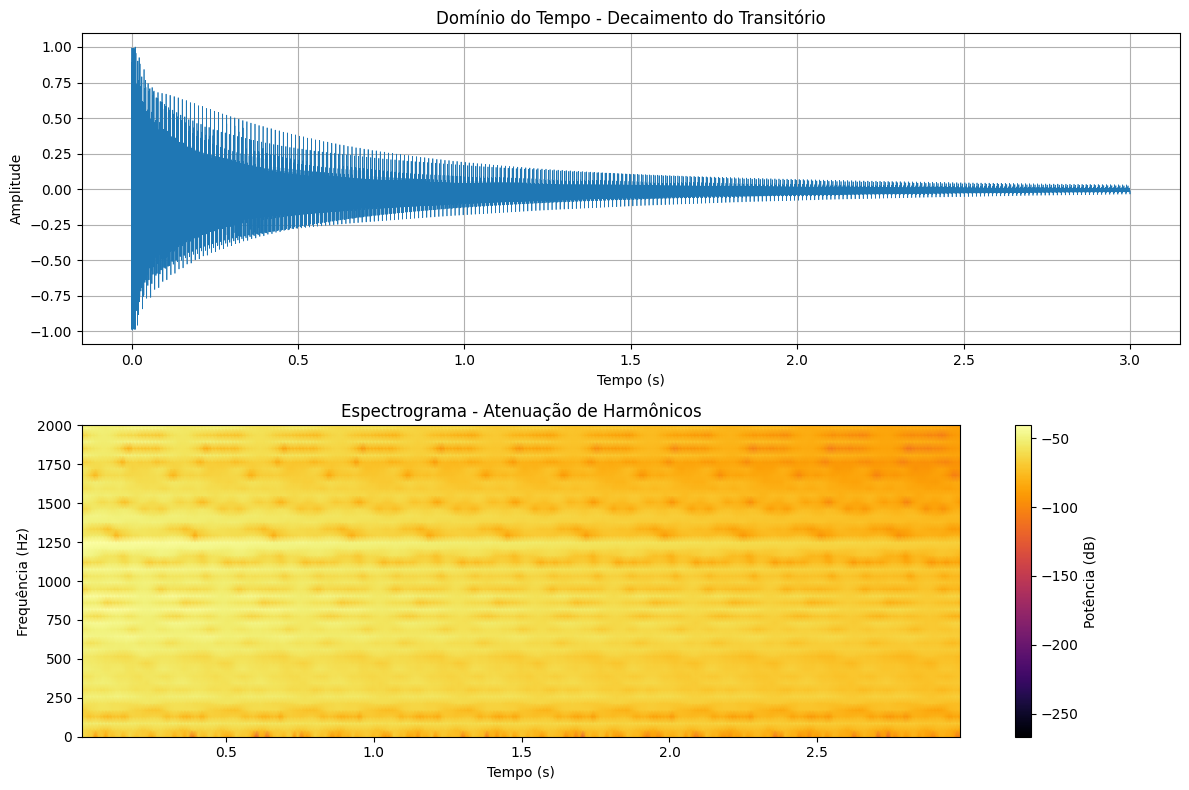

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import lfilter, spectrogram
from scipy.io.wavfile import write as write_wav # Import for saving WAV files

# Update package lists and then install PortAudio library for sounddevice
!apt-get update
!apt-get install -y portaudio19-dev
# import sounddevice as sd # Commented out as direct playback is not supported

def generate_bass_note(freq, duration, fs=44100, rho=0.996):
    """
    Sintetiza uma nota de baixo utilizando o algoritmo Karplus-Strong modelado como um filtro IIR.
    """
    # N é o atraso fundamental em amostras
    N = int(np.round(fs / freq))
    total_samples = int(duration * fs)

    # 1. Sinal de Excitação (Ataque da palheta/dedo)
    # Inicializa com zeros
    x = np.zeros(total_samples)

    # Para um baixo, um ruído "puro" soa muito estridente.
    # Usamos ruído branco inicial, mas na prática, você vai querer pré-filtrar isso.
    burst = np.random.uniform(-1.0, 1.0, N)
    x[:N] = burst

    # 2. Coeficientes do Filtro IIR
    # Numerador (feedforward): apenas passa o sinal de entrada
    b = [1.0]

    # Denominador (feedback): implementa a malha de atraso com o passa-baixa
    # A equação característica é: a[0]*y[n] + a[N]*y[n-N] + a[N+1]*y[n-N-1] = x[n]
    a = np.zeros(N + 2)
    a[0] = 1.0
    a[N] = -0.5 * rho
    a[N+1] = -0.5 * rho

    # 3. Processamento do Sinal (Equação de Diferenças)
    y = lfilter(b, a, x)

    # 4. Normalização (evita estourar o áudio)
    y = y / np.max(np.abs(y))

    return y, fs

def plot_analysis(y, fs):
    """Gera gráficos no domínio do tempo e da frequência para análise do transitório."""
    plt.figure(figsize=(12, 8))

    # Forma de onda
    plt.subplot(2, 1, 1)
    time_axis = np.arange(len(y)) / fs
    plt.plot(time_axis, y, color='#1f77b4', linewidth=0.5)
    plt.title('Domínio do Tempo - Decaimento do Transitório')
    plt.xlabel('Tempo (s)')
    plt.ylabel('Amplitude')
    plt.grid(True)

    # Espectrograma
    plt.subplot(2, 1, 2)
    f, t, Sxx = spectrogram(y, fs, nperseg=1024, noverlap=512)
    plt.pcolormesh(t, f, 10 * np.log10(Sxx), shading='gouraud', cmap='inferno')
    plt.title('Espectrograma - Atenuação de Harmônicos')
    plt.ylabel('Frequência (Hz)')
    plt.xlabel('Tempo (s)')
    plt.ylim(0, 2000) # Foco nas frequências graves e médias do baixo
    plt.colorbar(label='Potência (dB)')

    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    # Testando um Mi2 (E2) - corda solta padrão do baixo, aprox 82.41 Hz
    frequencia_alvo = 82.41
    duracao_segundos = 3.0
    coeficiente_rigidez = 0.992 # Valores mais próximos de 1.0 prolongam o sustain

    print(f"Gerando nota de {frequencia_alvo}Hz...")
    audio_signal, samplerate = generate_bass_note(frequencia_alvo, duracao_segundos, rho=coeficiente_rigidez)

    # Save the audio to a WAV file instead of playing it directly
    output_filename = 'bass_note.wav'
    # Convert to 16-bit PCM for common audio players
    audio_signal_int = np.int16(audio_signal * 32767)
    write_wav(output_filename, samplerate, audio_signal_int)
    print(f"Audio saved to {output_filename}")
    # sd.play(audio_signal, samplerate) # Commented out
    # sd.wait() # Commented out

    # Plota a análise matemática
    print("Gerando gráficos...")
    plot_analysis(audio_signal, samplerate)


In [ ]:
import librosa

def generate_solo(note_sequence, fs=44100, rho=0.992):
    """
    Gera um solo a partir de uma lista de tuplas (nota_freq, duracao).
    """
    solo_signal = np.array([])

    for freq, duration in note_sequence:
        if freq == 0: # Silêncio
            note_wave = np.zeros(int(duration * fs))
        else:
            note_wave, _ = generate_bass_note(freq, duration, fs=fs, rho=rho)

        solo_signal = np.concatenate([solo_signal, note_wave])

    # Normalização final do solo completo
    if len(solo_signal) > 0:
        solo_signal = solo_signal / np.max(np.abs(solo_signal))

    return solo_signal

# --- Mapeamento de Notas para Frequência ---
def get_freq(note_name):
    return librosa.note_to_hz(note_name)

# 1. Solo Simples de Teste (C2, E2, G2, C3)
solo_teste = [
    (get_freq('C2'), 0.5), (get_freq('E2'), 0.5),
    (get_freq('G2'), 0.5), (get_freq('C3'), 1.0)
]

# 2. Conversão da Tablatura (Solo Intro)
# Notas aproximadas baseadas na tablatura fornecida
solo_intro_tab = [
    # Parte 1
    (get_freq('C4'), 0.4), (get_freq('C4'), 0.2), (get_freq('E4'), 0.2),
    (get_freq('G4'), 0.2), (get_freq('F4'), 0.2), (get_freq('E4'), 0.2),
    (get_freq('F4'), 0.2), (get_freq('F4'), 0.2), (get_freq('E4'), 0.2),
    (get_freq('C4'), 0.3), (get_freq('D4'), 0.4), (get_freq('D4'), 0.3),
    (get_freq('G3'), 0.2), (get_freq('B3'), 0.2), (get_freq('G3'), 0.2),
    # Parte 2
    (get_freq('D4'), 0.3), (get_freq('F4'), 0.2), (get_freq('E4'), 0.2),
    (get_freq('F4'), 0.2), (get_freq('F4'), 0.3), (get_freq('E4'), 0.2),
    (get_freq('G3'), 0.2), (get_freq('A3'), 0.3), (get_freq('A3'), 0.2), (get_freq('D4'), 0.5),
    # Parte 3
    (get_freq('F3'), 0.2), (get_freq('G3'), 0.2), (get_freq('G3'), 0.2),
    (get_freq('A3'), 0.2), (get_freq('A3'), 0.2), (get_freq('C4'), 0.2),
    (get_freq('C4'), 0.3), (get_freq('E4'), 0.4), (get_freq('C5'), 0.8)
]

# Gerar e Salvar Solo de Teste
signal_teste = generate_solo(solo_teste)
write_wav('solo_simples.wav', 44100, np.int16(signal_teste * 32767))

# Gerar e Salvar Solo da Tablatura
signal_tab = generate_solo(solo_intro_tab)
write_wav('solo_tablatura.wav', 44100, np.int16(signal_tab * 32767))

print("Arquivos gerados: solo_simples.wav e solo_tablatura.wav")

Arquivos gerados: solo_simples.wav e solo_tablatura.wav


In [ ]:
import scipy.signal

def generate_bass_note_v2(freq, duration, fs=44100, rho=0.994, lowpass_cutoff=1000):
    """
    Sintetiza uma nota de baixo com ataque filtrado para um som menos estridente.
    """
    N = int(np.round(fs / freq))
    total_samples = int(duration * fs)
    x = np.zeros(total_samples)

    # Gerar burst de ruído
    burst = np.random.uniform(-1.0, 1.0, N)

    # Aplicar um filtro passa-baixa simples no burst para tirar o 'brilho' excessivo (estridência)
    # Criamos um filtro Butterworth de 2ª ordem
    nyq = 0.5 * fs
    normal_cutoff = lowpass_cutoff / nyq
    b_lp, a_lp = scipy.signal.butter(2, normal_cutoff, btype='low', analog=False)
    burst_filtered = scipy.signal.lfilter(b_lp, a_lp, burst)

    x[:N] = burst_filtered

    # Coeficientes Karplus-Strong
    b = [1.0]
    a = np.zeros(N + 2)
    a[0] = 1.0
    a[N] = -0.5 * rho
    a[N+1] = -0.5 * rho

    y = lfilter(b, a, x)

    # Normalização local
    if np.max(np.abs(y)) > 0:
        y = y / np.max(np.abs(y))

    return y

def generate_solo_v2(note_sequence, fs=44100, rho=0.994, overlap_samples=441):
    """
    Gera um solo com crossfade entre as notas para transições mais naturais.
    """
    total_duration = sum(d for _, d in note_sequence)
    # Criamos um buffer grande o suficiente
    solo_signal = np.zeros(int(total_duration * fs) + fs)
    current_ptr = 0

    for freq, duration in note_sequence:
        num_samples = int(duration * fs)
        if freq == 0:
            note_wave = np.zeros(num_samples)
        else:
            # Geramos a nota um pouco mais longa para permitir o fade
            note_wave = generate_bass_note_v2(freq, duration + (overlap_samples/fs), fs=fs, rho=rho)

            # Aplicar fade out suave no final da nota para o crossfade
            if len(note_wave) > overlap_samples:
                fade_out = np.linspace(1.0, 0.0, overlap_samples)
                note_wave[-overlap_samples:] *= fade_out

        # Mixagem no sinal principal (adição para permitir sobreposição)
        end_ptr = current_ptr + len(note_wave)
        solo_signal[current_ptr:end_ptr] += note_wave

        # Avançamos o ponteiro apenas pela duração original (causando o overlap no final)
        current_ptr += num_samples

    # Cortar o excesso e normalizar
    solo_signal = solo_signal[:current_ptr]
    if np.max(np.abs(solo_signal)) > 0:
        solo_signal = solo_signal / np.max(np.abs(solo_signal))

    return solo_signal

# Gerar novas versões
signal_teste_v2 = generate_solo_v2(solo_teste)
write_wav('solo_simples_v2.wav', 44100, np.int16(signal_teste_v2 * 32767))

signal_tab_v2 = generate_solo_v2(solo_intro_tab)
write_wav('solo_tablatura_v2.wav', 44100, np.int16(signal_tab_v2 * 32767))

print("Novos arquivos com som aveludado e transições suaves gerados!")

Novos arquivos com som aveludado e transições suaves gerados!


In [ ]:
import numpy as np
from scipy.io.wavfile import write as write_wav

# Nova sequência baseada na tablatura refinada enviada pelo usuário
# Cada tupla: (frequência, duração em segundos)
# Nota: Usei 0.4s como tempo base para cada batida

solo_refinado = [
    # Parte 1 de 3
    (get_freq('C4'), 0.4), (get_freq('G3'), 0.4), (get_freq('C4'), 0.4),
    (get_freq('E4'), 0.4), (get_freq('G4'), 0.4), (get_freq('F4'), 0.4),
    (get_freq('E4'), 0.4), (get_freq('F4'), 0.4), (get_freq('E4'), 0.4),
    (get_freq('C4'), 0.4), (get_freq('D4'), 0.4), (get_freq('G3'), 0.4),
    (get_freq('D4'), 0.4), (get_freq('G3'), 0.4),
    # Parte 2 de 3
    (get_freq('D4'), 0.4), (get_freq('C4'), 0.4), (get_freq('B3'), 0.4),
    (get_freq('C4'), 0.4), (get_freq('B3'), 0.4), (get_freq('G3'), 0.4),
    (get_freq('A3'), 0.4), (get_freq('A3'), 0.4), (get_freq('D4'), 0.4),
    # Parte 3 de 3 (Simplificada para notas únicas na síntese atual)
    (get_freq('F4'), 0.4), (get_freq('G4'), 0.4), (get_freq('E4'), 0.4),
    (get_freq('F4'), 0.4), (get_freq('A4'), 0.4), (get_freq('A4'), 0.4),
    (get_freq('C5'), 0.4), (get_freq('A4'), 0.4), (get_freq('F5'), 0.8)
]

# Gerar o áudio com as melhorias de transição v2
fs = 44100
signal_refinado = generate_solo_v2(solo_refinado, fs=fs, rho=0.995)

# Salvar o novo arquivo
output_v3 = 'solo_atualizado_v3.wav'
write_wav(output_v3, fs, np.int16(signal_refinado * 32767))

print(f"Arquivo '{output_v3}' gerado com sucesso baseado na nova tablatura!")

Arquivo 'solo_atualizado_v3.wav' gerado com sucesso baseado na nova tablatura!
